# MMAD LAB_1: Классификация датасета Car Evaluation
**Выполнил:** Ямщиков Владимир Сергеевич  
**Группа:** 26162 
**Направление:** Математика и Компьютерные Науки 
**Дата:** 12.10.2026

## Цель работы:
1. Провести разведочный анализ данных (EDA) датасета Car Evaluation.
2. Построить и визуализировать разделяющие поверхности для 5 алгоритмов классификации (LDA, QDA, Logistic Regression, SVM linear, SVM poly).
3. Провести автоматизированный подбор гиперпараметров с помощью фреймворка Optuna.
4. Глубоко проанализировать качество моделей (матрицы ошибок, кривые обучения, калибровка, SHAP).
5. Визуализировать работу LDA во всех двумерных подпространствах признаков.

## Условие лабораторной работы:

- 1. Загрузить **таблицу Car Evaluation** из **репозитория UCI** (можно из любого доступного источника: UCI, sklearn, kaggle). Поместить данные в объект DataFrame библиотеки pandas.
Визуализировать распределения классов на всех парах переменных.

- 2. Выбрать две переменные. Построить и визуализировать (показать разделяющую кривую) решения **методами линейный и квадратичный дискриминант, логистическая регрессия, SVM (линейное и квадратичное ядро)**. Оценить качество классификации этими методами при помощи коросс-валидации на выбранных признаках и во всем признаковом пространстве.

- 3. Построить **линейный дискриминант** на всех переменных. Визуализировать ответы алгоритма (выделить, например, цветом) на обучающей выборке и классы объектов (выделить, например, формой маркеров) во всех двумерных подпространствах.

## Установка необходимых библиотек

In [ ]:
# ! pip install scikit-learn ucimlrepo pandas shap matplotlib seaborn optuna

## Импорт библиотек

In [162]:
# Вспомогательные библиотеки и типизация
from tqdm import tqdm
import warnings
from pathlib import Path
from itertools import combinations
from typing import List, Tuple, Dict, Any

# Для работы с данными
import pandas as pd
import numpy as np

# Для визуализации
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.colors import ListedColormap

# Интерпретация
import shap 

# Метрики и модели
from sklearn.base import clone
from sklearn.calibration import calibration_curve
from sklearn.model_selection import StratifiedKFold, learning_curve, cross_val_score
from sklearn.discriminant_analysis import LinearDiscriminantAnalysis, QuadraticDiscriminantAnalysis
from sklearn.metrics import roc_curve, roc_auc_score, confusion_matrix, classification_report, precision_recall_curve, average_precision_score
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef, auc
from sklearn.preprocessing import label_binarize

# Для автоматического подбора параметров моделей
import optuna
optuna.logging.set_verbosity(optuna.logging.WARNING)

from ucimlrepo import fetch_ucirepo 

# Настройка параметров библиотек
warnings.filterwarnings('ignore')
sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams['figure.figsize'] = (12, 6)

# Для полного вывода без сокращения
# pd.set_option('display.max_columns', None)
# pd.set_option('display.max_rows', None)

RANDOM_STATE: int = 42
ROOT: Path = Path.cwd()
DATA_DIR: Path = ROOT / "data" if (ROOT / "data").exists() else ROOT

print("✅ Окружение настроено")

✅ Окружение настроено


In [2]:
print(f"Root: {ROOT}")

Root: /home/yamshchikov/ML_practice/Torchvision_core_project/MMAD/Lab_1


## 1. Загрузка и разведочный анализ данных (EDA)

## Импорт данных датасета Car Evaluation из репозитория UCI

In [3]:
def load_car_evaluation_dataset() -> Tuple[pd.DataFrame, pd.DataFrame, Dict[str, Any], pd.DataFrame]:
    """
    Загружает датасет Car Evaluation из UCI Machine Learning Repository.
    
    Returns:
        Tuple containing:
            - X: Features DataFrame
            - y: Targets DataFrame
            - metadata: Dataset metadata dictionary
            - variables: Variable information DataFrame
    """
    car_evaluation = fetch_ucirepo(id=19)
    
    X: pd.DataFrame = car_evaluation.data.features
    y: pd.DataFrame = car_evaluation.data.targets
    metadata: Dict[str, Any] = car_evaluation.metadata
    variables: pd.DataFrame = car_evaluation.variables
    
    print(metadata)
    print(variables)
    
    return X, y, metadata, variables

In [4]:
X, y, metadata, variables = load_car_evaluation_dataset()

{'uci_id': 19, 'name': 'Car Evaluation', 'repository_url': 'https://archive.ics.uci.edu/dataset/19/car+evaluation', 'data_url': 'https://archive.ics.uci.edu/static/public/19/data.csv', 'abstract': 'Derived from simple hierarchical decision model, this database may be useful for testing constructive induction and structure discovery methods.', 'area': 'Other', 'tasks': ['Classification'], 'characteristics': ['Multivariate'], 'num_instances': 1728, 'num_features': 6, 'feature_types': ['Categorical'], 'demographics': [], 'target_col': ['class'], 'index_col': None, 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 1988, 'last_updated': 'Thu Aug 10 2023', 'dataset_doi': '10.24432/C5JP48', 'creators': ['Marko Bohanec'], 'intro_paper': {'ID': 249, 'type': 'NATIVE', 'title': 'Knowledge acquisition and explanation for multi-attribute decision making', 'authors': 'M. Bohanec, V. Rajkovič', 'venue': '8th Intl Workshop on Expert Systems and their Applications, 

## Создание pandas DataFrame

In [5]:
df: pd.DataFrame = pd.concat([X, y], axis=1)
df

,buying,maint,doors,persons,lug_boot,safety,class
0,vhigh,vhigh,2,2,small,low,unacc
1,vhigh,vhigh,2,2,small,med,unacc
2,vhigh,vhigh,2,2,small,high,unacc
3,vhigh,vhigh,2,2,med,low,unacc
4,vhigh,vhigh,2,2,med,med,unacc
...,...,...,...,...,...,...,...
1723,low,low,5more,more,med,med,good
1724,low,low,5more,more,med,high,vgood
1725,low,low,5more,more,big,low,unacc
1726,low,low,5more,more,big,med,good


## Выведем статистику исходного DataFrame

### Размер датафрейма

In [6]:
df.shape

(1728, 7)

### Информация о датафрейме

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1728 entries, 0 to 1727
Data columns (total 7 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   buying    1728 non-null   object
 1   maint     1728 non-null   object
 2   doors     1728 non-null   object
 3   persons   1728 non-null   object
 4   lug_boot  1728 non-null   object
 5   safety    1728 non-null   object
 6   class     1728 non-null   object
dtypes: object(7)
memory usage: 94.6+ KB


In [8]:
df.quantile

<bound method DataFrame.quantile of      buying  maint  doors persons lug_boot safety  class
0     vhigh  vhigh      2       2    small    low  unacc
1     vhigh  vhigh      2       2    small    med  unacc
2     vhigh  vhigh      2       2    small   high  unacc
3     vhigh  vhigh      2       2      med    low  unacc
4     vhigh  vhigh      2       2      med    med  unacc
...     ...    ...    ...     ...      ...    ...    ...
1723    low    low  5more    more      med    med   good
1724    low    low  5more    more      med   high  vgood
1725    low    low  5more    more      big    low  unacc
1726    low    low  5more    more      big    med   good
1727    low    low  5more    more      big   high  vgood

[1728 rows x 7 columns]>

### Колонки датафрейма

In [9]:
df.columns

Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')

### Типы данных в датафрейме

In [10]:
df.dtypes

buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object

### Индекс

In [11]:
df.index

RangeIndex(start=0, stop=1728, step=1)

### Оси датафрейма

In [12]:
df.axes

[RangeIndex(start=0, stop=1728, step=1),
 Index(['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class'], dtype='object')]

### Статистика данных датафрейма

In [13]:
print("Типы данных DataFrame:\n", df.dtypes)
print("Основные статистики для числовых признаков:\n", df.describe())

cat_cols_train: pd.Index = df.select_dtypes(include=['object']).columns
if len(cat_cols_train) > 0:
    print("Основные статистики для категориальных признаков:\n", df[cat_cols_train].describe())

Типы данных DataFrame:
 buying      object
maint       object
doors       object
persons     object
lug_boot    object
safety      object
class       object
dtype: object
Основные статистики для числовых признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210
Основные статистики для категориальных признаков:
        buying  maint doors persons lug_boot safety  class
count    1728   1728  1728    1728     1728   1728   1728
unique      4      4     4       3        3      3      4
top     vhigh  vhigh     2       2    small    low  unacc
freq      432    432   432     576      576    576   1210


In [14]:
print(f"\nКолонки в train: {df.columns.tolist()}")
print(f"\nТипы данных:\n{df.dtypes.value_counts()}")


Колонки в train: ['buying', 'maint', 'doors', 'persons', 'lug_boot', 'safety', 'class']

Типы данных:
object    7
Name: count, dtype: int64


### Подсчёт числовых и категориальных признаков

In [15]:
num_cols_train: pd.Index = df.select_dtypes(include=["int64", "float64"]).columns
cat_cols_train: pd.Index = df.select_dtypes(include=["object"]).columns

print(f"Числовые: {len(num_cols_train)}")
print(f"Категориальные: {len(cat_cols_train)}")

Числовые: 0
Категориальные: 7


## Получение целевой переменной

In [16]:
target_col: str = y.columns[0]
target_col

'class'

## Уникальные классы целевой переменной

In [17]:
print(f"Целевая переменная: {target_col}")
print(f"Классы: {df[target_col].unique()}\n")

Целевая переменная: class
Классы: ['unacc' 'acc' 'vgood' 'good']



Датасет содержит 1728 объектов и 6 категориальных признаков. Все признаки имеют естественный порядок (ordinal), что позволяет применить порядковое кодирование (Ordinal Encoding) вместо One-Hot, сохраняя семантику данных (например, `low` < `med` < `high`).

## Порядок категорий для осмысленного порядкового кодирования

In [18]:
ordinal_mappings: Dict[str, Dict[str, int]] = {
    'buying': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'maint': {'vhigh': 0, 'high': 1, 'med': 2, 'low': 3},
    'doors': {'2': 0, '3': 1, '4': 2, '5more': 3},
    'persons': {'2': 0, '4': 1, 'more': 2},
    'lug_boot': {'small': 0, 'med': 1, 'big': 2},
    'safety': {'low': 0, 'med': 1, 'high': 2},
    target_col: {'unacc': 0, 'acc': 1, 'good': 2, 'vgood': 3}
}

## Применение кодирования к DataFrame

In [19]:
df_plot: pd.DataFrame = df.copy()
for col in df_plot.columns:
    if df_plot[col].dtype == 'object' or isinstance(df_plot[col].dtype, pd.CategoricalDtype):
        df_plot[col] = df_plot[col].astype('category').cat.codes

## Визуализация распределений на всех парах переменных

<Figure size 1400x1200 with 0 Axes>

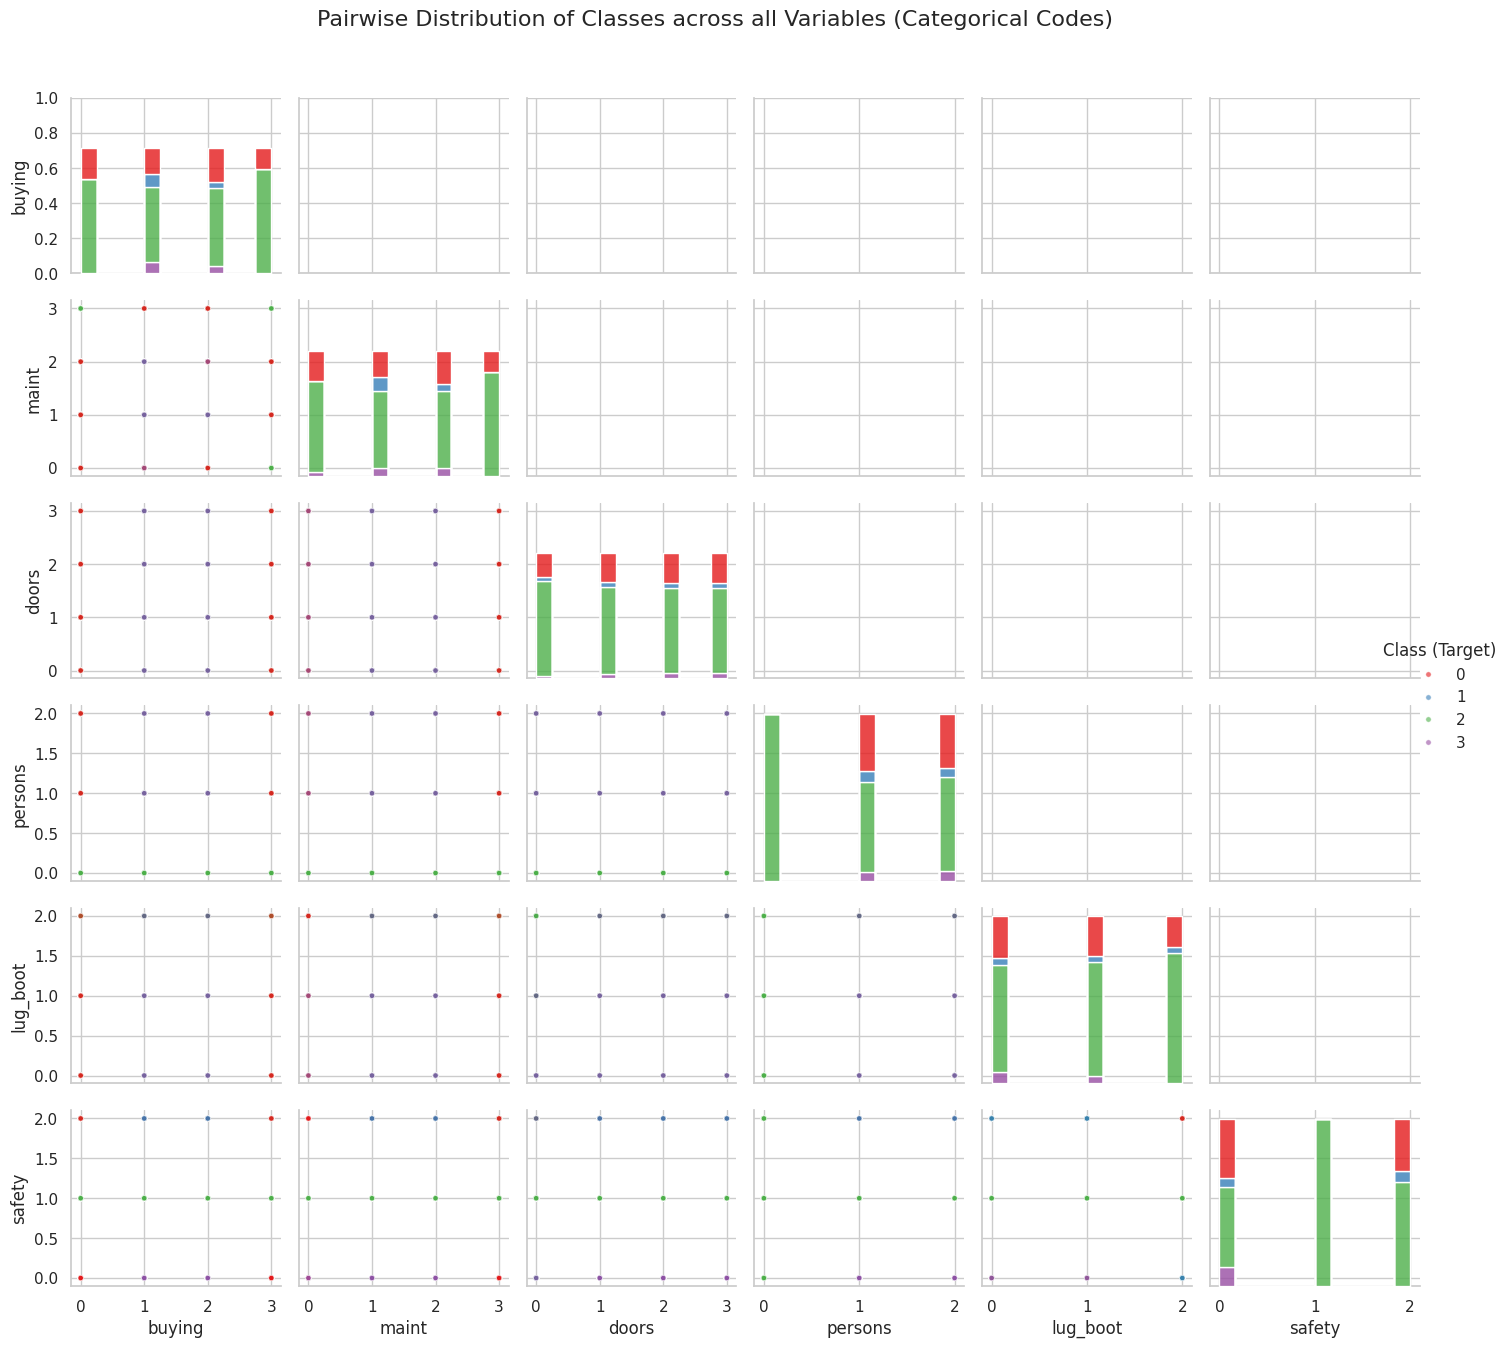

In [ ]:
sns.set_theme(style="whitegrid")
plt.figure(figsize=(14, 12))

g = sns.PairGrid(df_plot, hue=target_col, palette='Set1', height=2.2, corner=False)

# Нижняя часть матрицы: точки с прозрачностью
g.map_lower(sns.scatterplot, alpha=0.6, s=15, edgecolor='w', linewidth=0.5)

# Диагональ: гистограммы распределения признака, сложенные по классам (stacked)
g.map_diag(sns.histplot, kde=False, element="step", stat="count", multiple="stack", alpha=0.8)

g.add_legend(title='Class (Target)', bbox_to_anchor=(1.05, 0.5))
plt.suptitle("Pairwise Distribution of Classes across all Variables (Categorical Codes)", y=1.02, fontsize=16)
plt.tight_layout()
plt.show()

## Stacked Bar Charts (Категориальные графики)

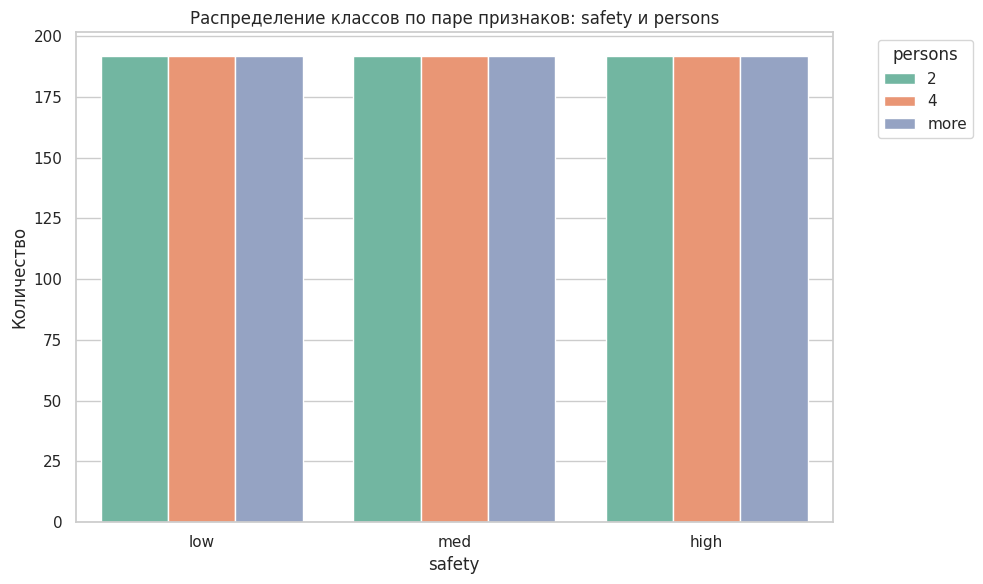

In [22]:
feat1_1, feat2_1 = 'safety', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_1, hue=feat2_1, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_1} и {feat2_1}')
plt.xlabel(feat1_1)
plt.ylabel('Количество')
plt.legend(title=feat2_1, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

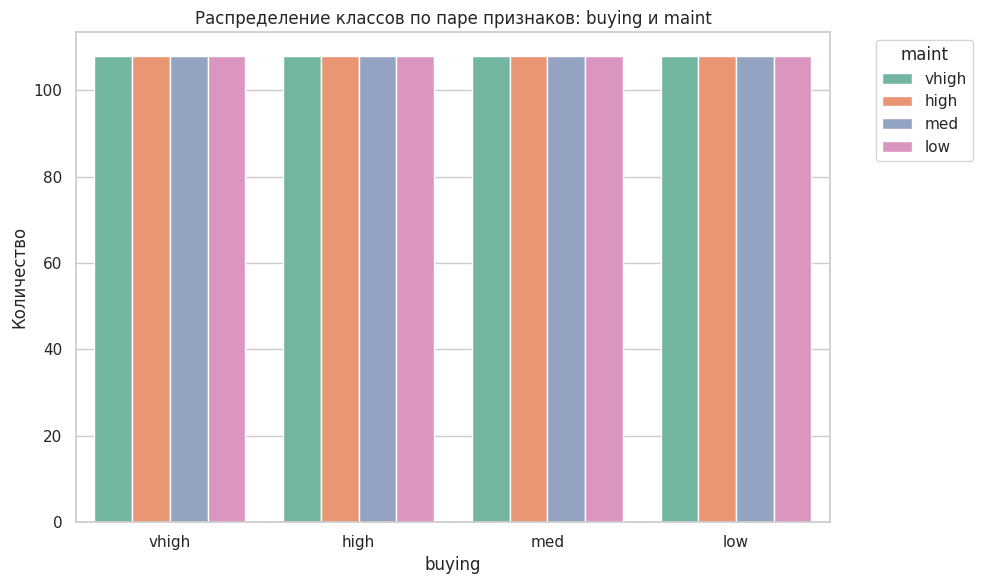

In [23]:
feat1_2, feat2_2 = 'buying', 'maint'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_2, hue=feat2_2, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_2} и {feat2_2}')
plt.xlabel(feat1_2)
plt.ylabel('Количество')
plt.legend(title=feat2_2, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

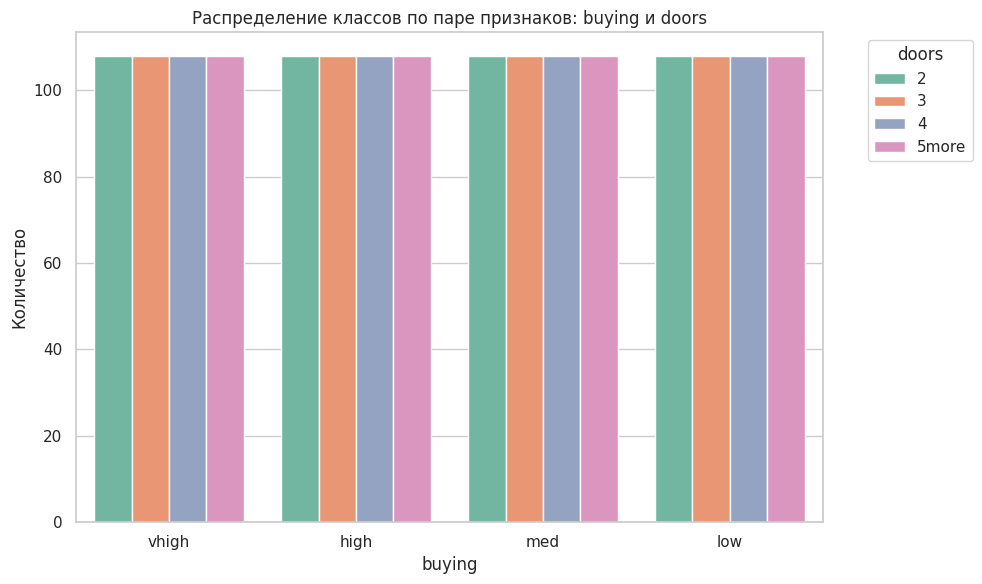

In [24]:
feat1_3, feat2_3 = 'buying', 'doors'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_3, hue=feat2_3, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_3} и {feat2_3}')
plt.xlabel(feat1_3)
plt.ylabel('Количество')
plt.legend(title=feat2_3, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

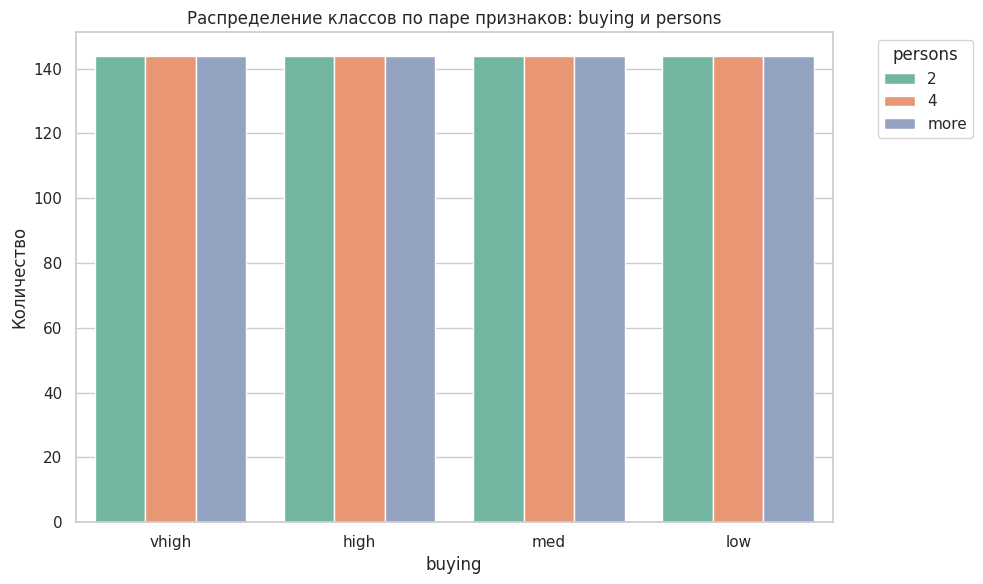

In [25]:
feat1_4, feat2_4 = 'buying', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_4, hue=feat2_4, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_4} и {feat2_4}')
plt.xlabel(feat1_4)
plt.ylabel('Количество')
plt.legend(title=feat2_4, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

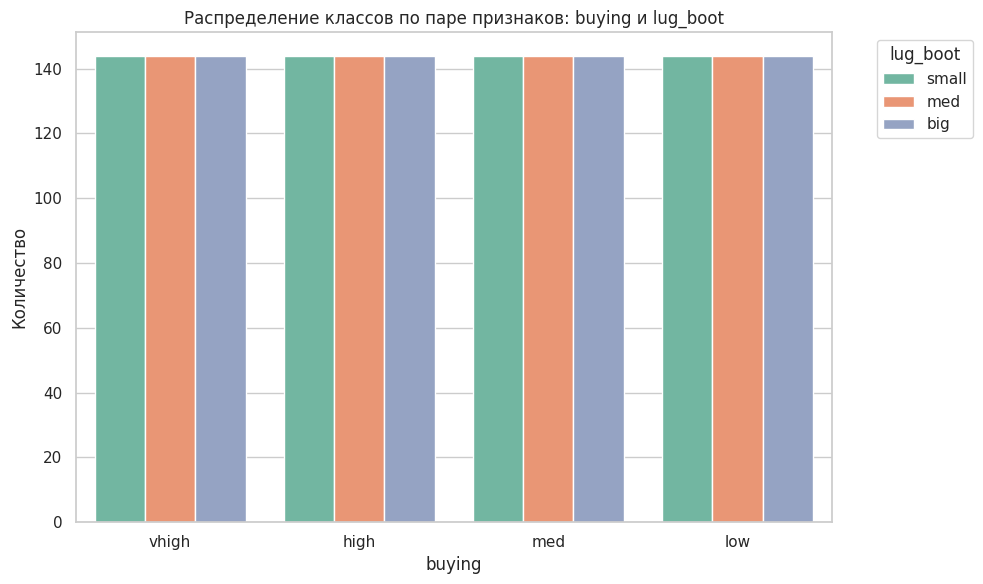

In [26]:
feat1_5, feat2_5 = 'buying', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_5, hue=feat2_5, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_5} и {feat2_5}')
plt.xlabel(feat1_5)
plt.ylabel('Количество')
plt.legend(title=feat2_5, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

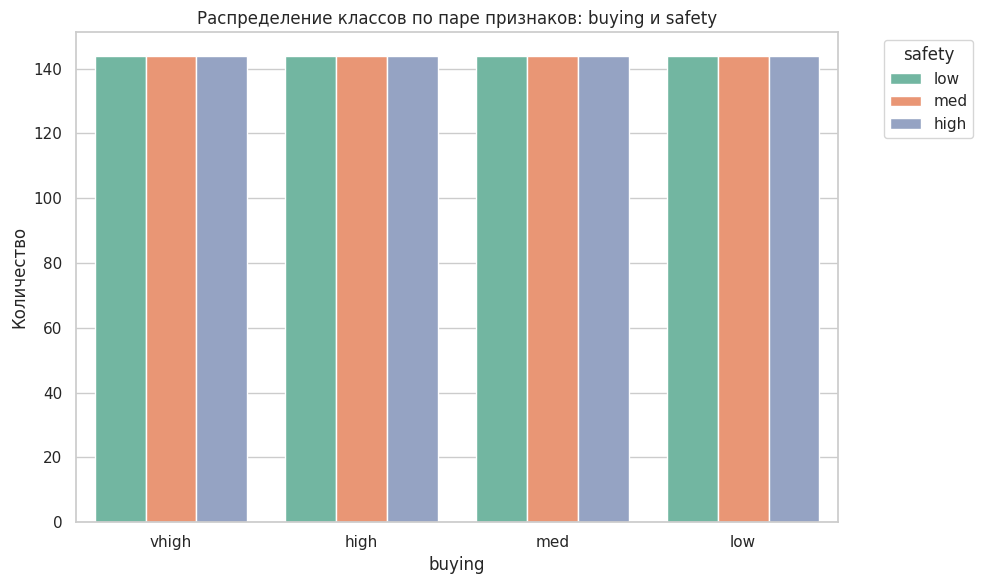

In [27]:
feat1_6, feat2_6 = 'buying', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_6, hue=feat2_6, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_6} и {feat2_6}')
plt.xlabel(feat1_6)
plt.ylabel('Количество')
plt.legend(title=feat2_6, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

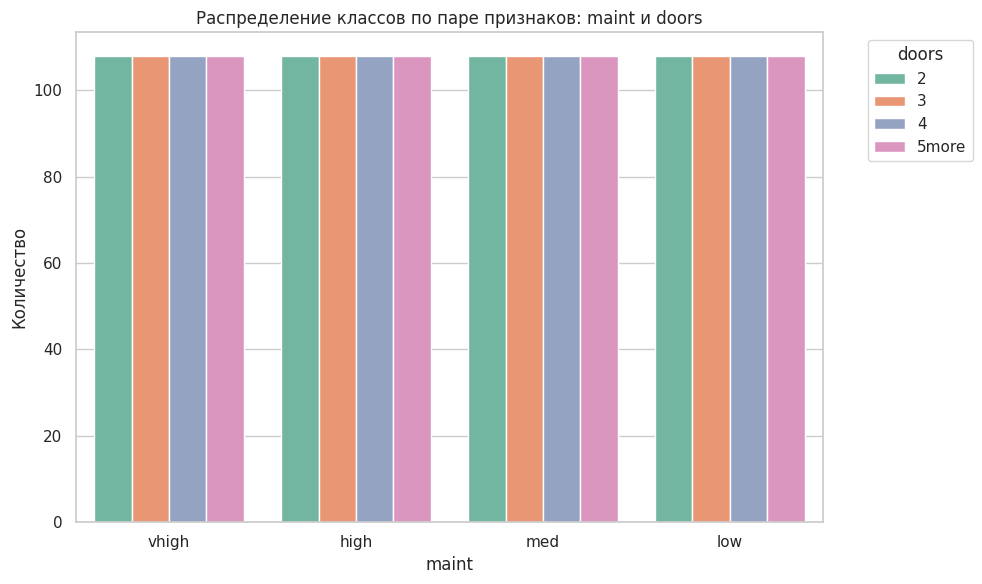

In [28]:
feat1_7, feat2_7 = 'maint', 'doors'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_7, hue=feat2_7, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_7} и {feat2_7}')
plt.xlabel(feat1_7)
plt.ylabel('Количество')
plt.legend(title=feat2_7, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

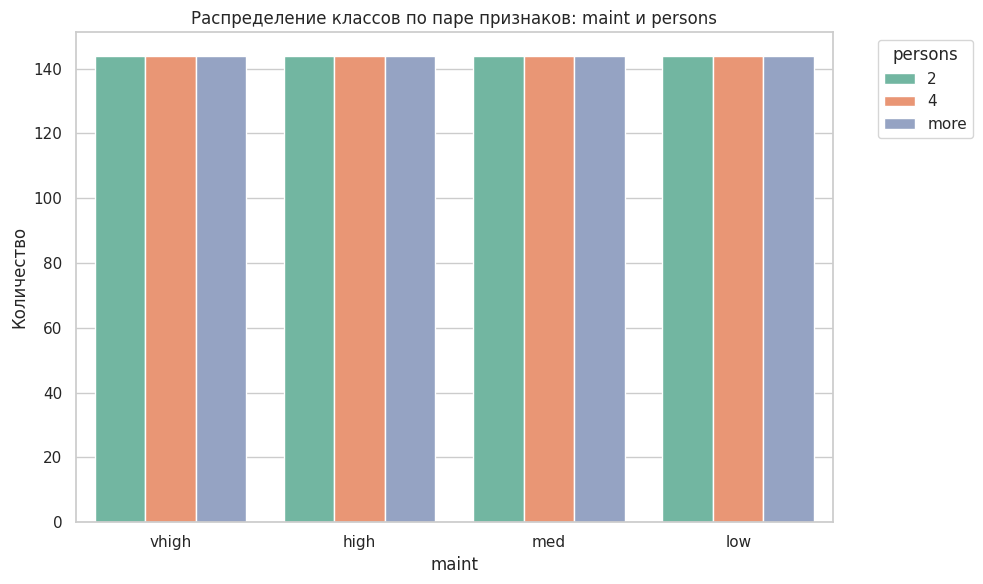

In [29]:
feat1_8, feat2_8 = 'maint', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_8, hue=feat2_8, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_8} и {feat2_8}')
plt.xlabel(feat1_8)
plt.ylabel('Количество')
plt.legend(title=feat2_8, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

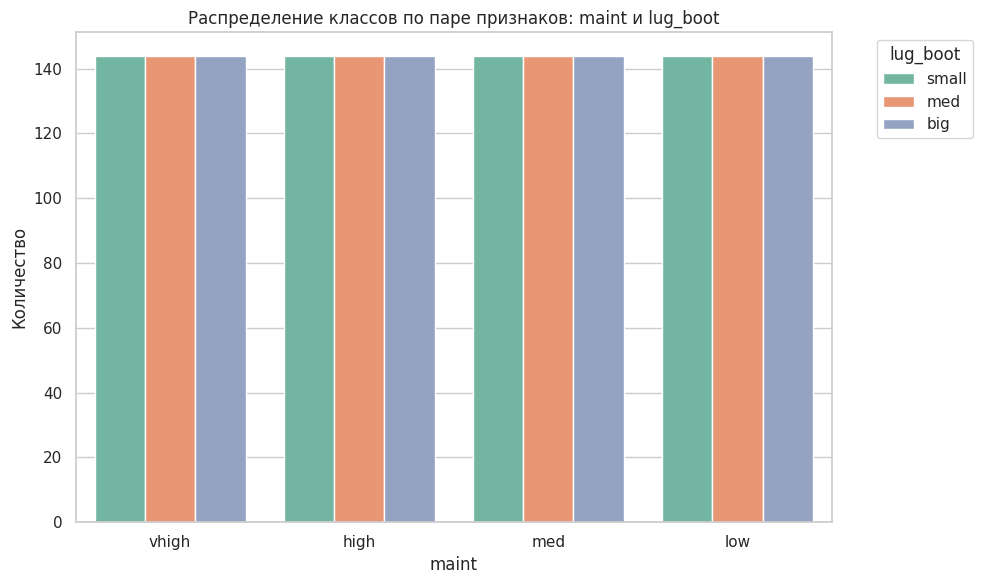

In [30]:
feat1_9, feat2_9 = 'maint', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_9, hue=feat2_9, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_9} и {feat2_9}')
plt.xlabel(feat1_9)
plt.ylabel('Количество')
plt.legend(title=feat2_9, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

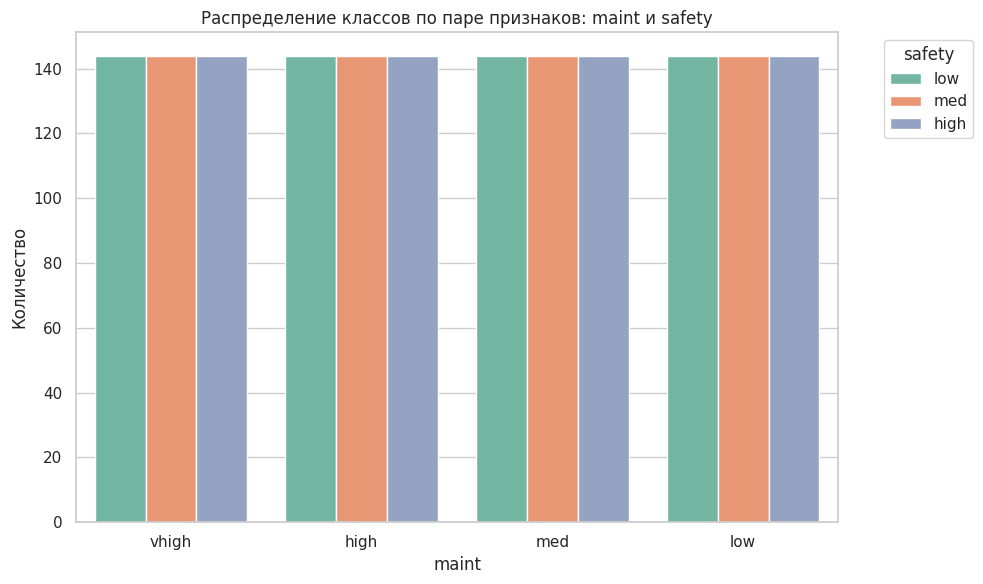

In [31]:
feat1_10, feat2_10 = 'maint', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_10, hue=feat2_10, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_10} и {feat2_10}')
plt.xlabel(feat1_10)
plt.ylabel('Количество')
plt.legend(title=feat2_10, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

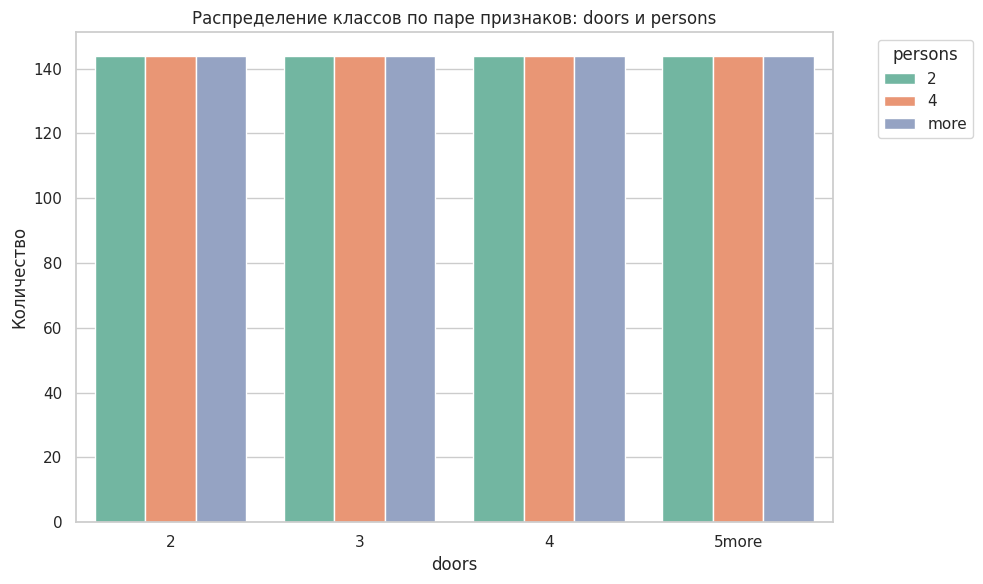

In [32]:
feat1_11, feat2_11 = 'doors', 'persons'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_11, hue=feat2_11, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_11} и {feat2_11}')
plt.xlabel(feat1_11)
plt.ylabel('Количество')
plt.legend(title=feat2_11, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

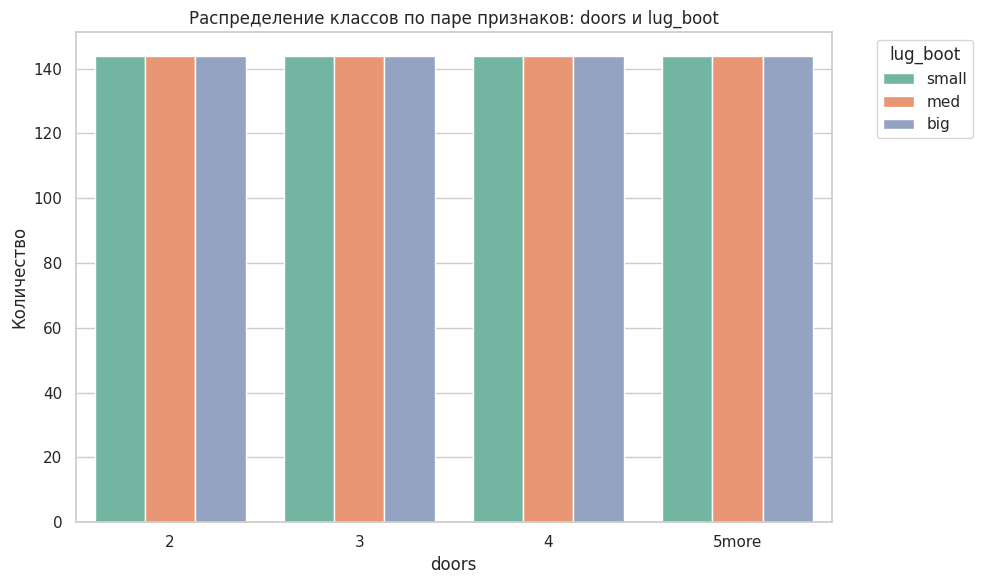

In [33]:
feat1_12, feat2_12 = 'doors', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_12, hue=feat2_12, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_12} и {feat2_12}')
plt.xlabel(feat1_12)
plt.ylabel('Количество')
plt.legend(title=feat2_12, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

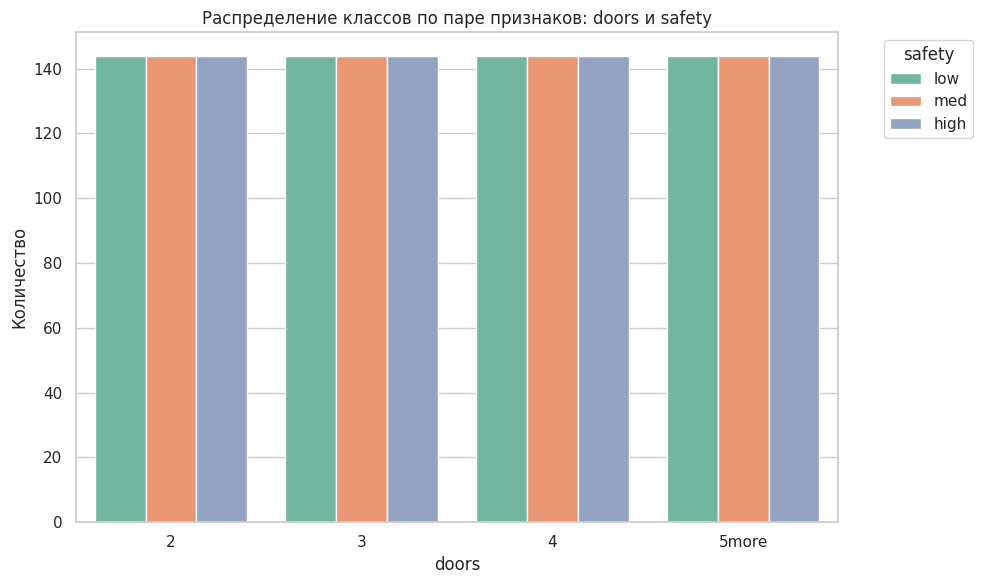

In [34]:
feat1_13, feat2_13 = 'doors', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_13, hue=feat2_13, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_13} и {feat2_13}')
plt.xlabel(feat1_13)
plt.ylabel('Количество')
plt.legend(title=feat2_13, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

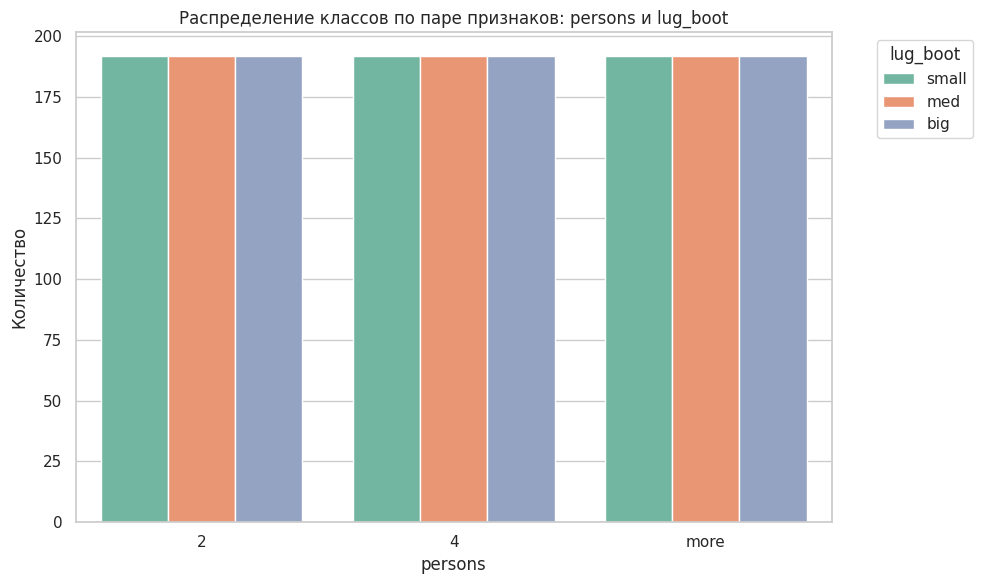

In [35]:
feat1_14, feat2_14 = 'persons', 'lug_boot'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_14, hue=feat2_14, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_14} и {feat2_14}')
plt.xlabel(feat1_14)
plt.ylabel('Количество')
plt.legend(title=feat2_14, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

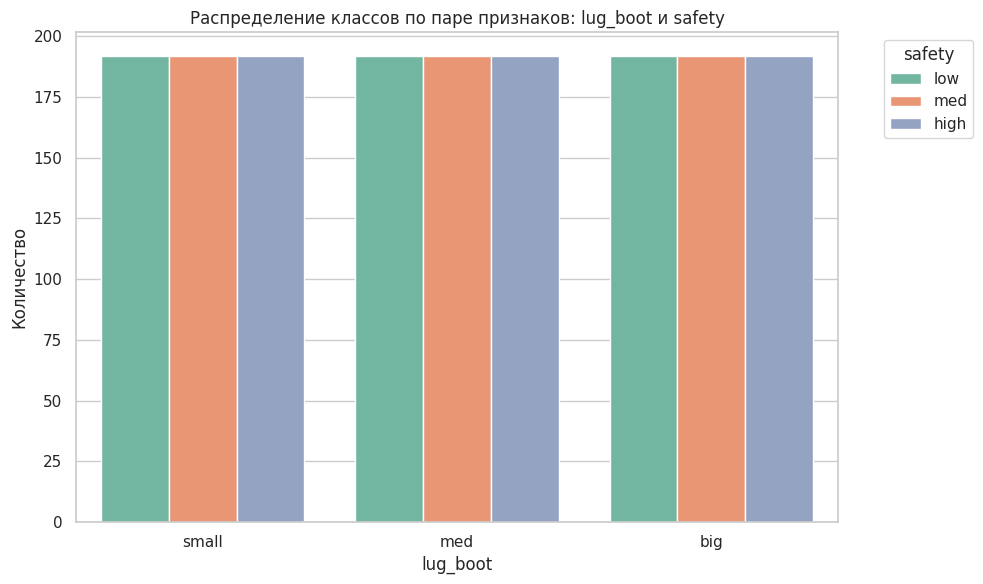

In [36]:
feat1_15, feat2_15 = 'lug_boot', 'safety'

plt.figure(figsize=(10, 6))
sns.countplot(data=df, x=feat1_15, hue=feat2_15, palette='Set2')
plt.title(f'Распределение классов по паре признаков: {feat1_15} и {feat2_15}')
plt.xlabel(feat1_15)
plt.ylabel('Количество')
plt.legend(title=feat2_15, bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

## Применение кодирования к DataFrame

In [37]:
df_encoded: pd.DataFrame = df.copy()
for col, mapping in ordinal_mappings.items():
    df_encoded[col] = df_encoded[col].map(mapping)

In [38]:
df_encoded

,buying,maint,doors,persons,lug_boot,safety,class
0,0,0,0,0,0,0,0
1,0,0,0,0,0,1,0
2,0,0,0,0,0,2,0
3,0,0,0,0,1,0,0
4,0,0,0,0,1,1,0
...,...,...,...,...,...,...,...
1723,3,3,3,2,1,1,2
1724,3,3,3,2,1,2,3
1725,3,3,3,2,2,0,0
1726,3,3,3,2,2,1,2


## Выделение матрицы признаков и целевой переменной из DataFrame

In [39]:
X_all: pd.DataFrame = df_encoded.drop(columns=[target_col])
y: pd.Series = df_encoded[target_col]

In [40]:
X_all

,buying,maint,doors,persons,lug_boot,safety
0,0,0,0,0,0,0
1,0,0,0,0,0,1
2,0,0,0,0,0,2
3,0,0,0,0,1,0
4,0,0,0,0,1,1
...,...,...,...,...,...,...
1723,3,3,3,2,1,1
1724,3,3,3,2,1,2
1725,3,3,3,2,2,0
1726,3,3,3,2,2,1


In [41]:
y

0       0
1       0
2       0
3       0
4       0
       ..
1723    2
1724    3
1725    0
1726    2
1727    3
Name: class, Length: 1728, dtype: int64

## Выбираем две переменные для визуализации границ

## Сравним все 15 пар. Для этого выделим переменные вида X_2d_1, X_2d_2, ..., X_2d_15

In [42]:
X_2d_1: pd.DataFrame = df_encoded[[feat1_1, feat2_1]]
X_2d_1

,safety,persons
0,0,0
1,1,0
2,2,0
3,0,0
4,1,0
...,...,...
1723,1,2
1724,2,2
1725,0,2
1726,1,2


In [43]:
X_2d_2: pd.DataFrame = df_encoded[[feat1_2, feat2_2]]
X_2d_2

,buying,maint
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,3
1724,3,3
1725,3,3
1726,3,3


In [44]:
X_2d_3: pd.DataFrame = df_encoded[[feat1_3, feat2_3]]
X_2d_3

,buying,doors
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,3
1724,3,3
1725,3,3
1726,3,3


In [45]:
X_2d_4: pd.DataFrame = df_encoded[[feat1_4, feat2_4]]
X_2d_4

,buying,persons
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,2
1724,3,2
1725,3,2
1726,3,2


In [46]:
X_2d_5: pd.DataFrame = df_encoded[[feat1_5, feat2_5]]
X_2d_5

,buying,lug_boot
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
1723,3,1
1724,3,1
1725,3,2
1726,3,2


In [47]:
X_2d_6: pd.DataFrame = df_encoded[[feat1_6, feat2_6]]
X_2d_6

,buying,safety
0,0,0
1,0,1
2,0,2
3,0,0
4,0,1
...,...,...
1723,3,1
1724,3,2
1725,3,0
1726,3,1


In [48]:
X_2d_7: pd.DataFrame = df_encoded[[feat1_7, feat2_7]]
X_2d_7

,maint,doors
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,3
1724,3,3
1725,3,3
1726,3,3


In [49]:
X_2d_8: pd.DataFrame = df_encoded[[feat1_8, feat2_8]]
X_2d_8

,maint,persons
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,2
1724,3,2
1725,3,2
1726,3,2


In [50]:
X_2d_9: pd.DataFrame = df_encoded[[feat1_9, feat2_9]]
X_2d_9

,maint,lug_boot
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
1723,3,1
1724,3,1
1725,3,2
1726,3,2


In [51]:
X_2d_10: pd.DataFrame = df_encoded[[feat1_10, feat2_10]]
X_2d_10

,maint,safety
0,0,0
1,0,1
2,0,2
3,0,0
4,0,1
...,...,...
1723,3,1
1724,3,2
1725,3,0
1726,3,1


In [52]:
X_2d_11: pd.DataFrame = df_encoded[[feat1_11, feat2_11]]
X_2d_11

,doors,persons
0,0,0
1,0,0
2,0,0
3,0,0
4,0,0
...,...,...
1723,3,2
1724,3,2
1725,3,2
1726,3,2


In [53]:
X_2d_12: pd.DataFrame = df_encoded[[feat1_12, feat2_12]]
X_2d_12

,doors,lug_boot
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
1723,3,1
1724,3,1
1725,3,2
1726,3,2


In [54]:
X_2d_13: pd.DataFrame = df_encoded[[feat1_13, feat2_13]]
X_2d_13

,doors,safety
0,0,0
1,0,1
2,0,2
3,0,0
4,0,1
...,...,...
1723,3,1
1724,3,2
1725,3,0
1726,3,1


In [55]:
X_2d_14: pd.DataFrame = df_encoded[[feat1_14, feat2_14]]
X_2d_14

,persons,lug_boot
0,0,0
1,0,0
2,0,0
3,0,1
4,0,1
...,...,...
1723,2,1
1724,2,1
1725,2,2
1726,2,2


In [56]:
X_2d_15: pd.DataFrame = df_encoded[[feat1_15, feat2_15]]
X_2d_15

,lug_boot,safety
0,0,0
1,0,1
2,0,2
3,1,0
4,1,1
...,...,...
1723,1,1
1724,1,2
1725,2,0
1726,2,1


## Инициализация моделей

### Вариант 1: ленивый. Возьмём словарь моделей со статичными параметрами

In [57]:
models: Dict[str, Any] = {
    "Линейный дискриминант (LDA)": LinearDiscriminantAnalysis(),
    "Квадратичный дискриминант (QDA)": QuadraticDiscriminantAnalysis(reg_param=0.1, tol=1e-7),
    "Логистическая регрессия": LogisticRegression(
        max_iter=1000, solver='lbfgs', random_state=RANDOM_STATE, tol=1e-7
    ),
    "SVM (линейное ядро)": SVC(kernel='linear', probability=True, random_state=RANDOM_STATE, tol=1e-7),
    "SVM (квадратичное ядро)": SVC(kernel='poly', degree=2, probability=True, random_state=RANDOM_STATE, tol=1e-3)
}

## Визуализация разделяющих кривых для 2D подпространства

### Сравнение 1 (по признакам 'safety' и 'persons')

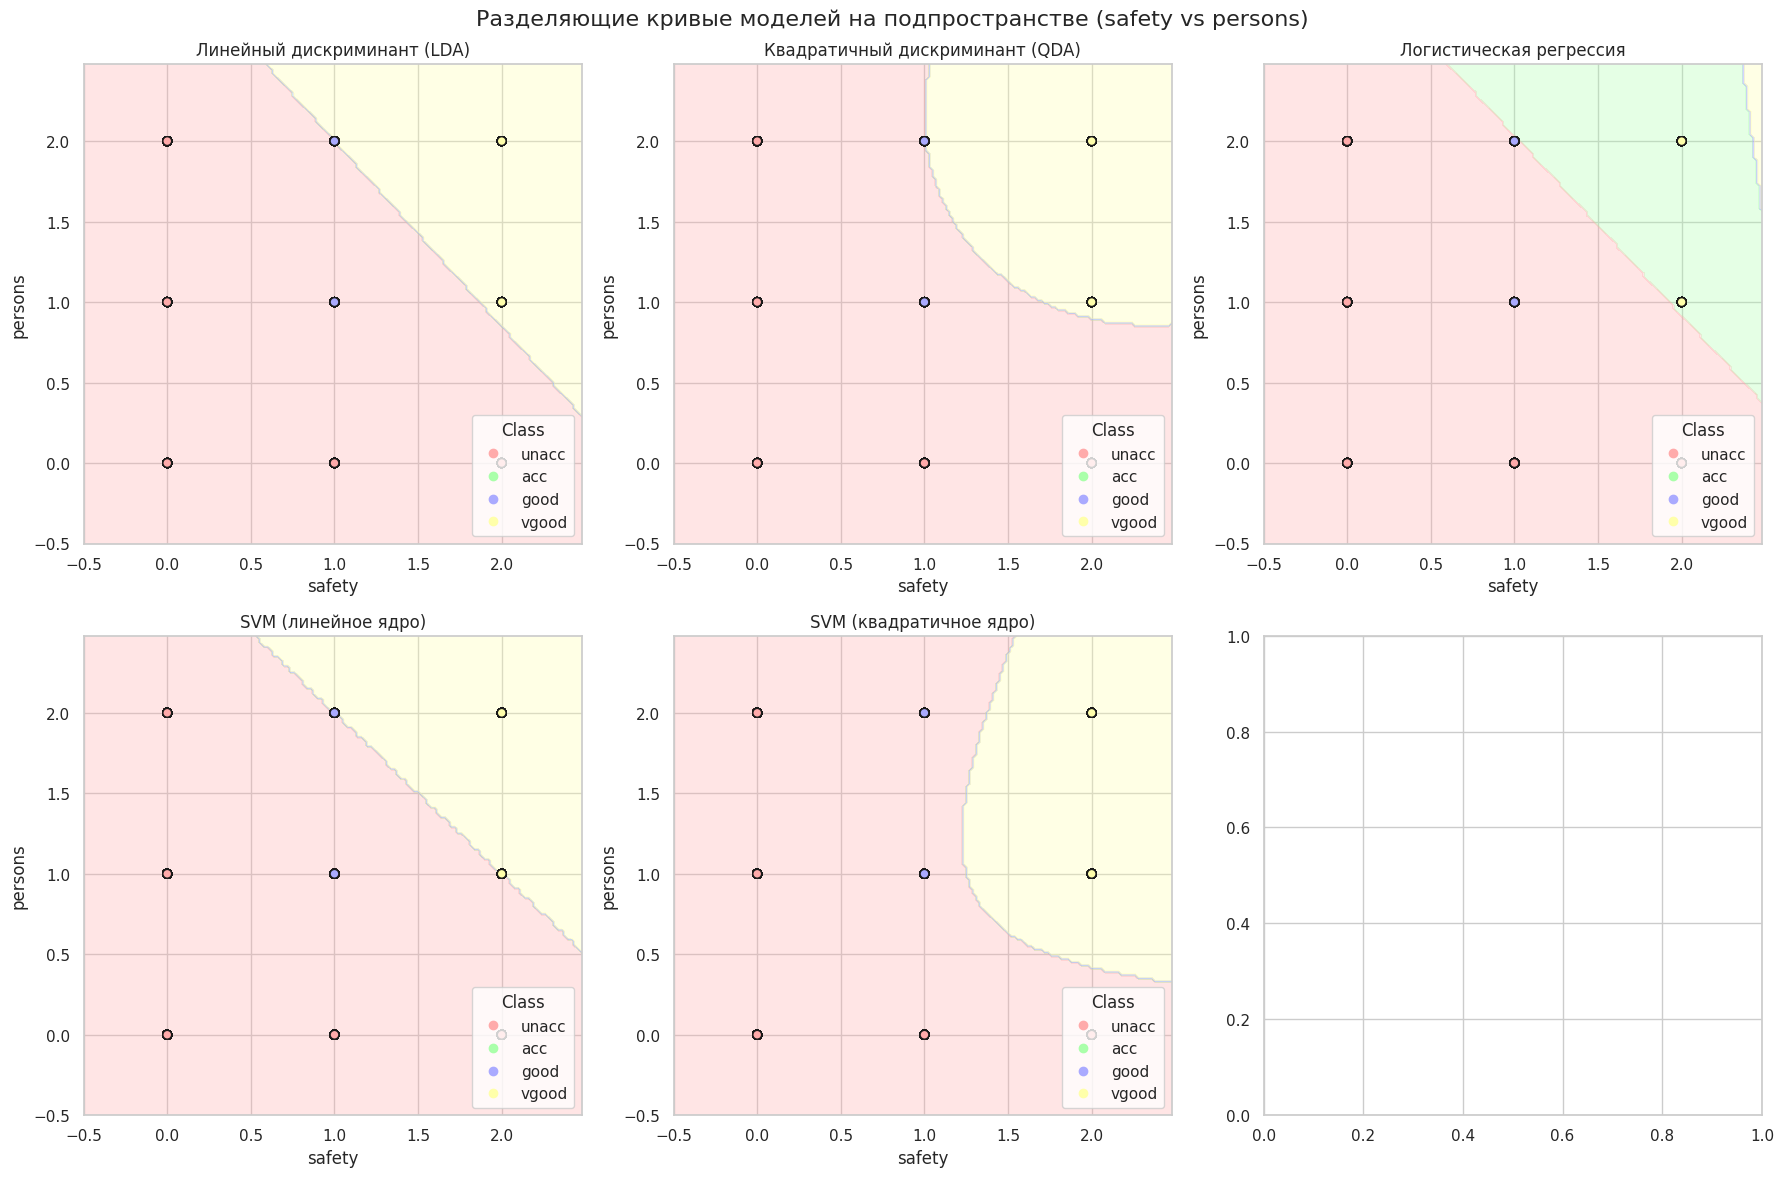

In [58]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_1[feat1_1].min() - 0.5, X_2d_1[feat1_1].max() + 0.5
y_min, y_max = X_2d_1[feat2_1].min() - 0.5, X_2d_1[feat2_1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_1, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_1[feat1_1], X_2d_1[feat2_1], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)

plt.suptitle("Разделяющие кривые моделей на подпространстве (safety vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 2 (по признакам 'buying' и 'maint')

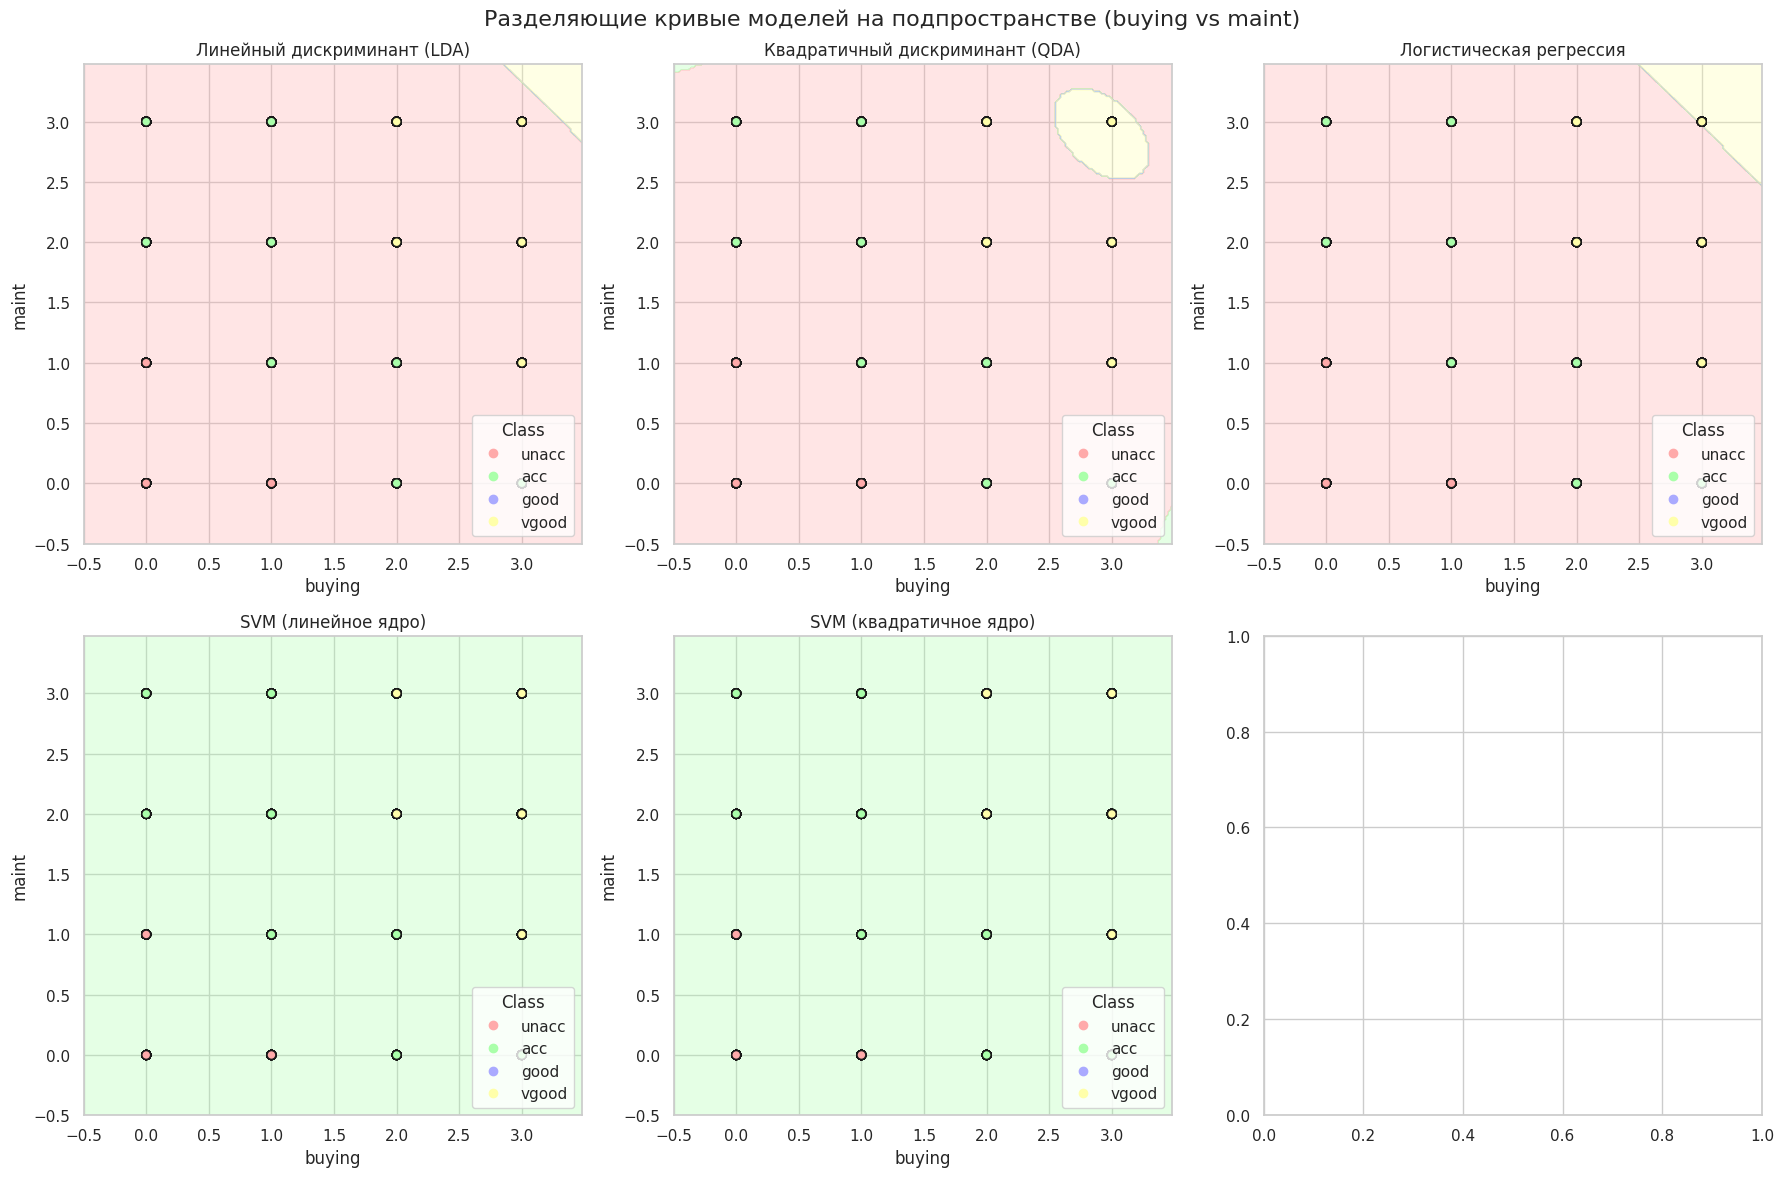

In [59]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_2[feat1_2].min() - 0.5, X_2d_2[feat1_2].max() + 0.5
y_min, y_max = X_2d_2[feat2_2].min() - 0.5, X_2d_2[feat2_2].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_2, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_2[feat1_2], X_2d_2[feat2_2], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs maint)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 3 (по признакам 'buying' и 'doors')

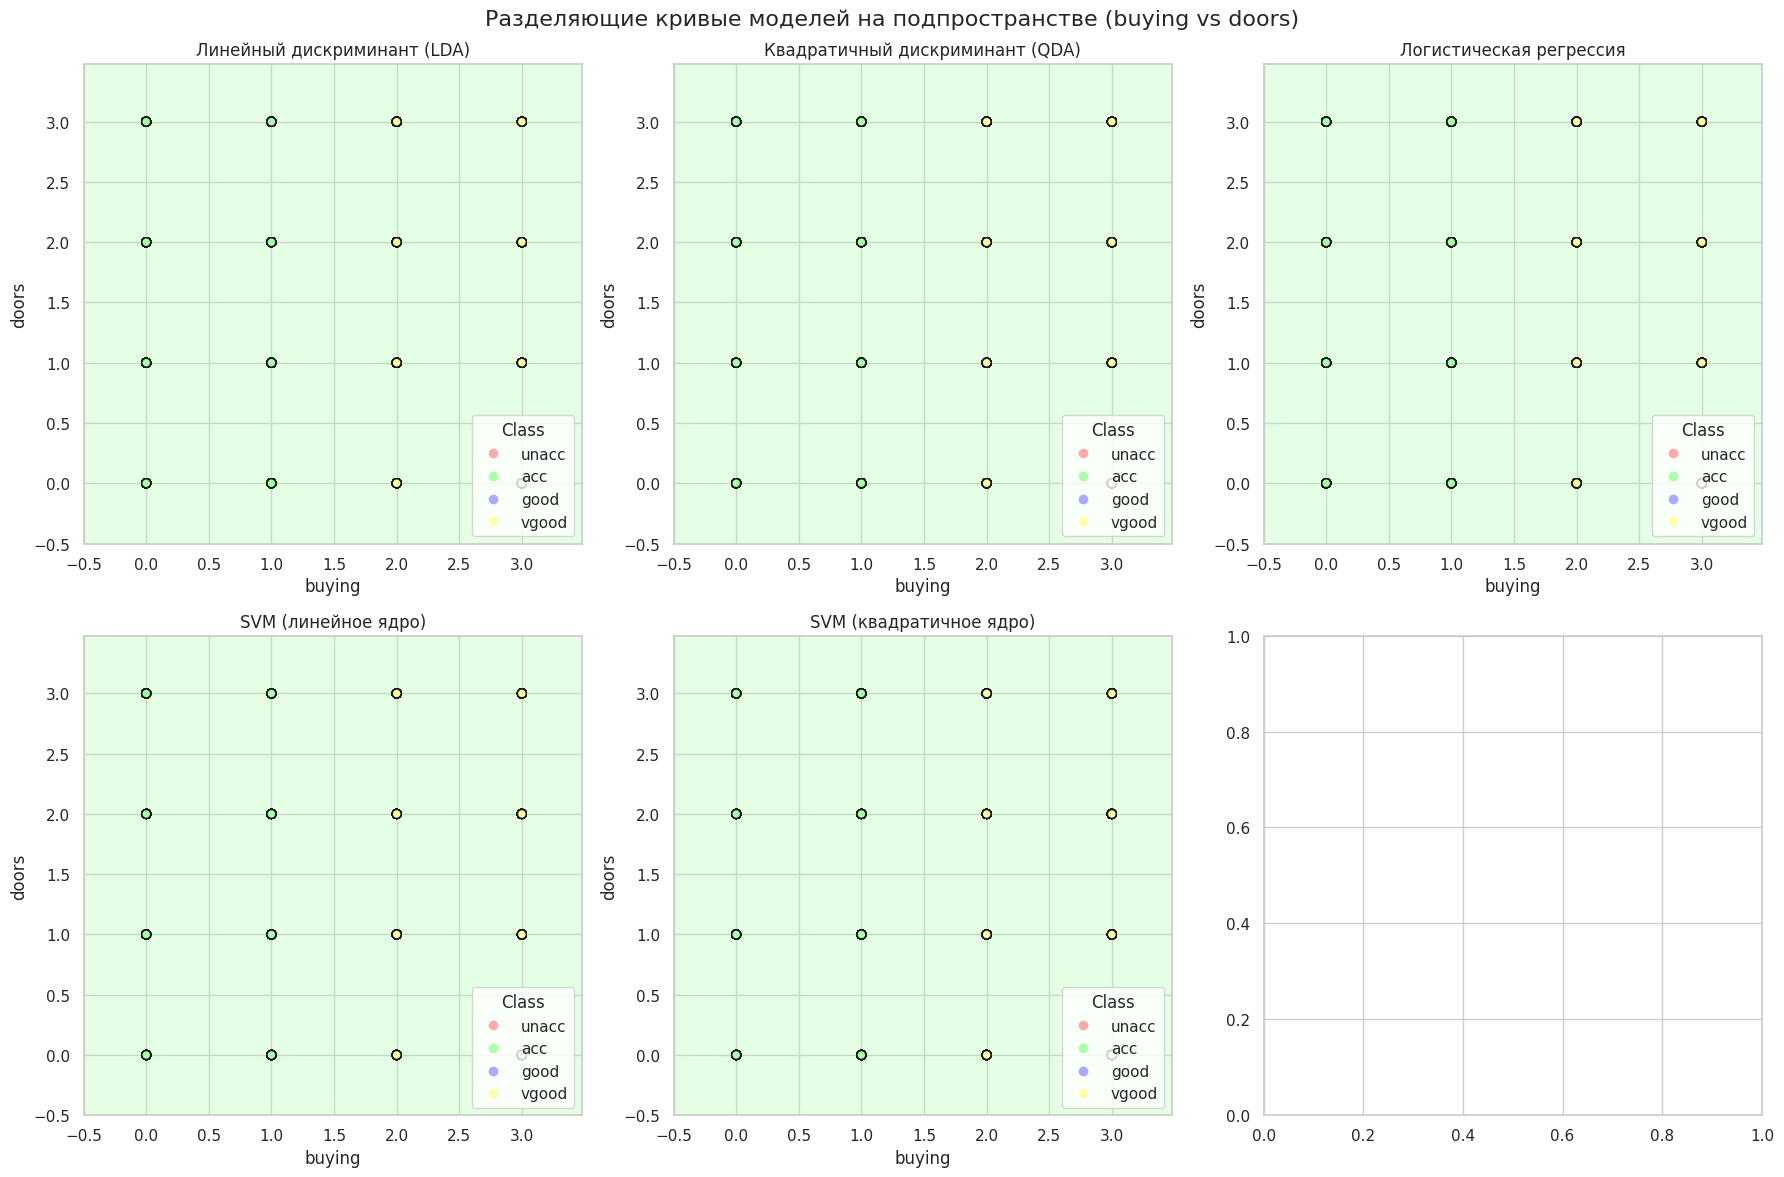

In [73]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_3[feat1_3].min() - 0.5, X_2d_3[feat1_3].max() + 0.5
y_min, y_max = X_2d_3[feat2_3].min() - 0.5, X_2d_3[feat2_3].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_3, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_3[feat1_3], X_2d_3[feat2_3], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_3)
        ax.set_ylabel(feat2_3)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_3)
        ax.set_ylabel(feat2_3)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs doors)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 4 (по признакам 'buying' и 'persons')

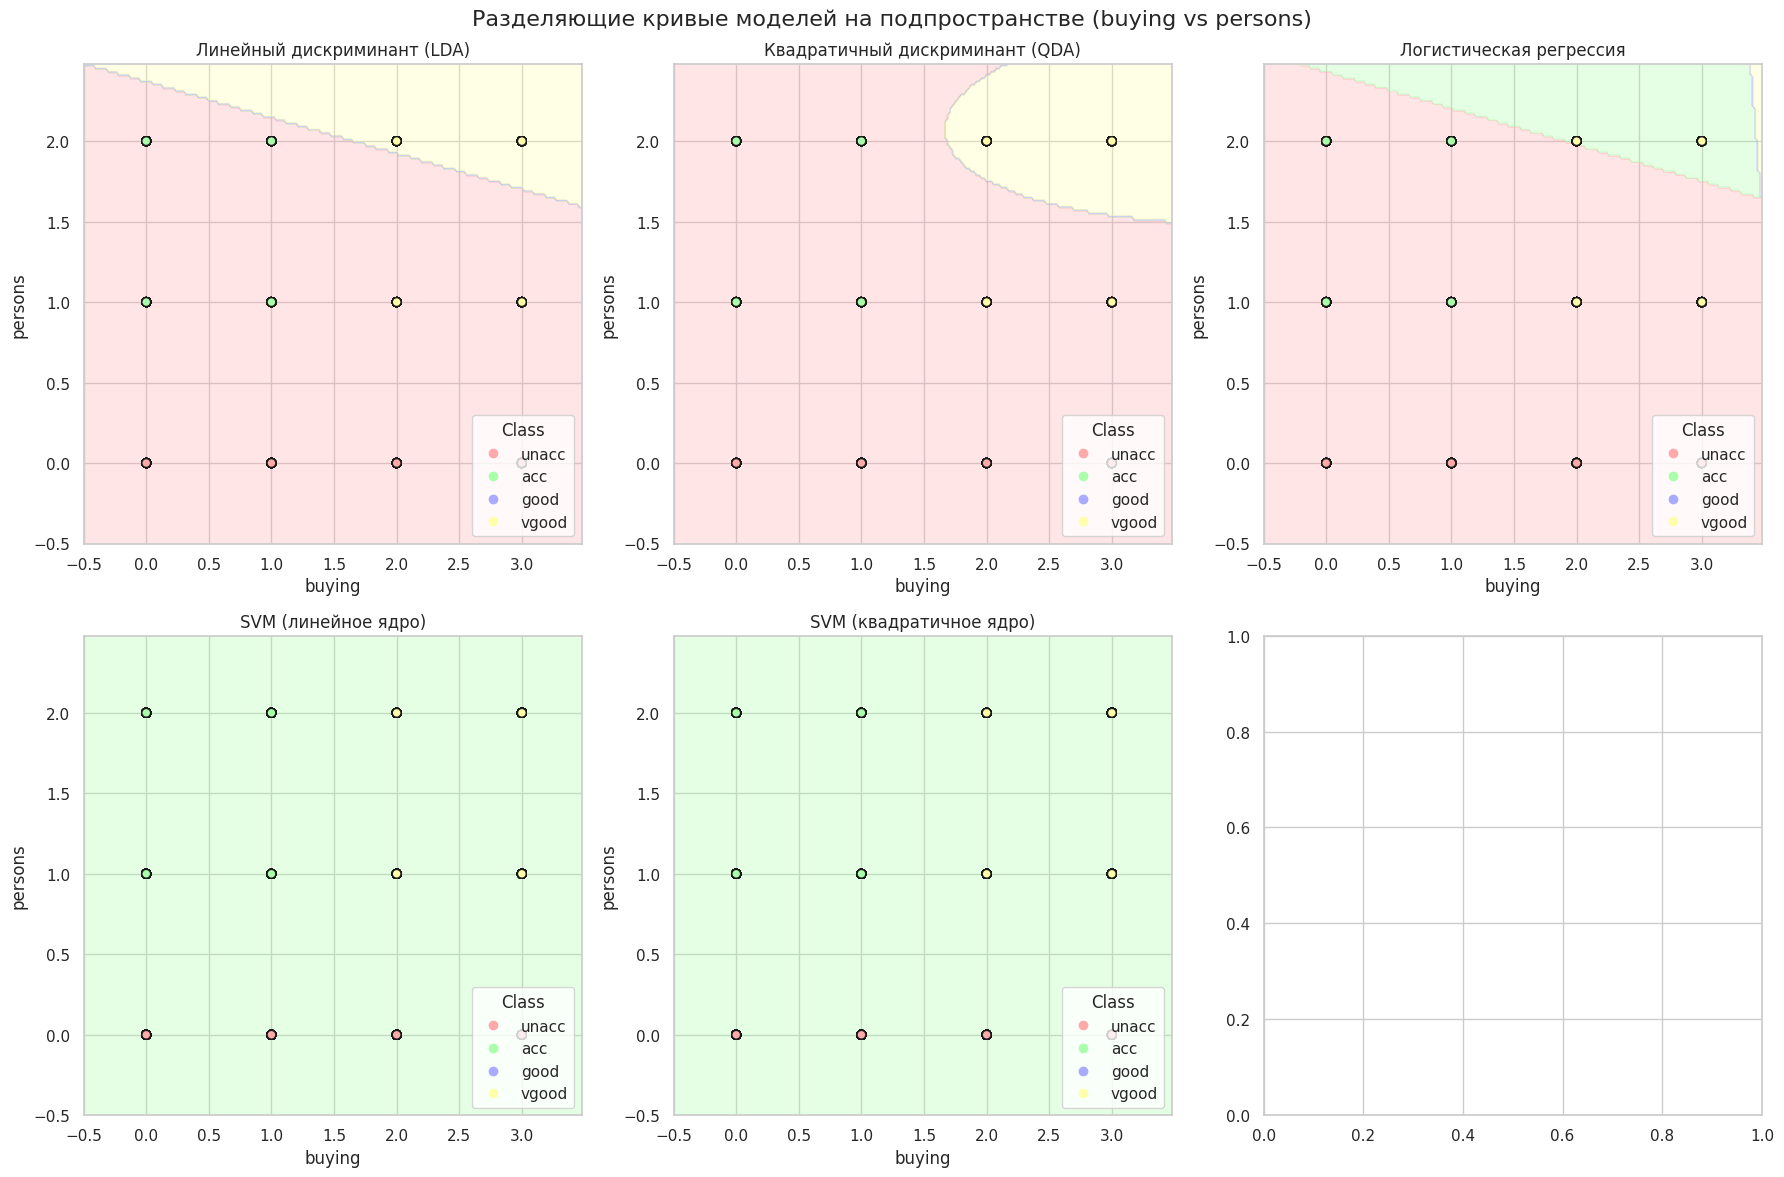

In [74]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_4[feat1_4].min() - 0.5, X_2d_4[feat1_4].max() + 0.5
y_min, y_max = X_2d_4[feat2_4].min() - 0.5, X_2d_4[feat2_4].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_4, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_4[feat1_4], X_2d_4[feat2_4], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_4)
        ax.set_ylabel(feat2_4)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_4)
        ax.set_ylabel(feat2_4)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 5 (по признакам 'buying' и 'lug_boot')

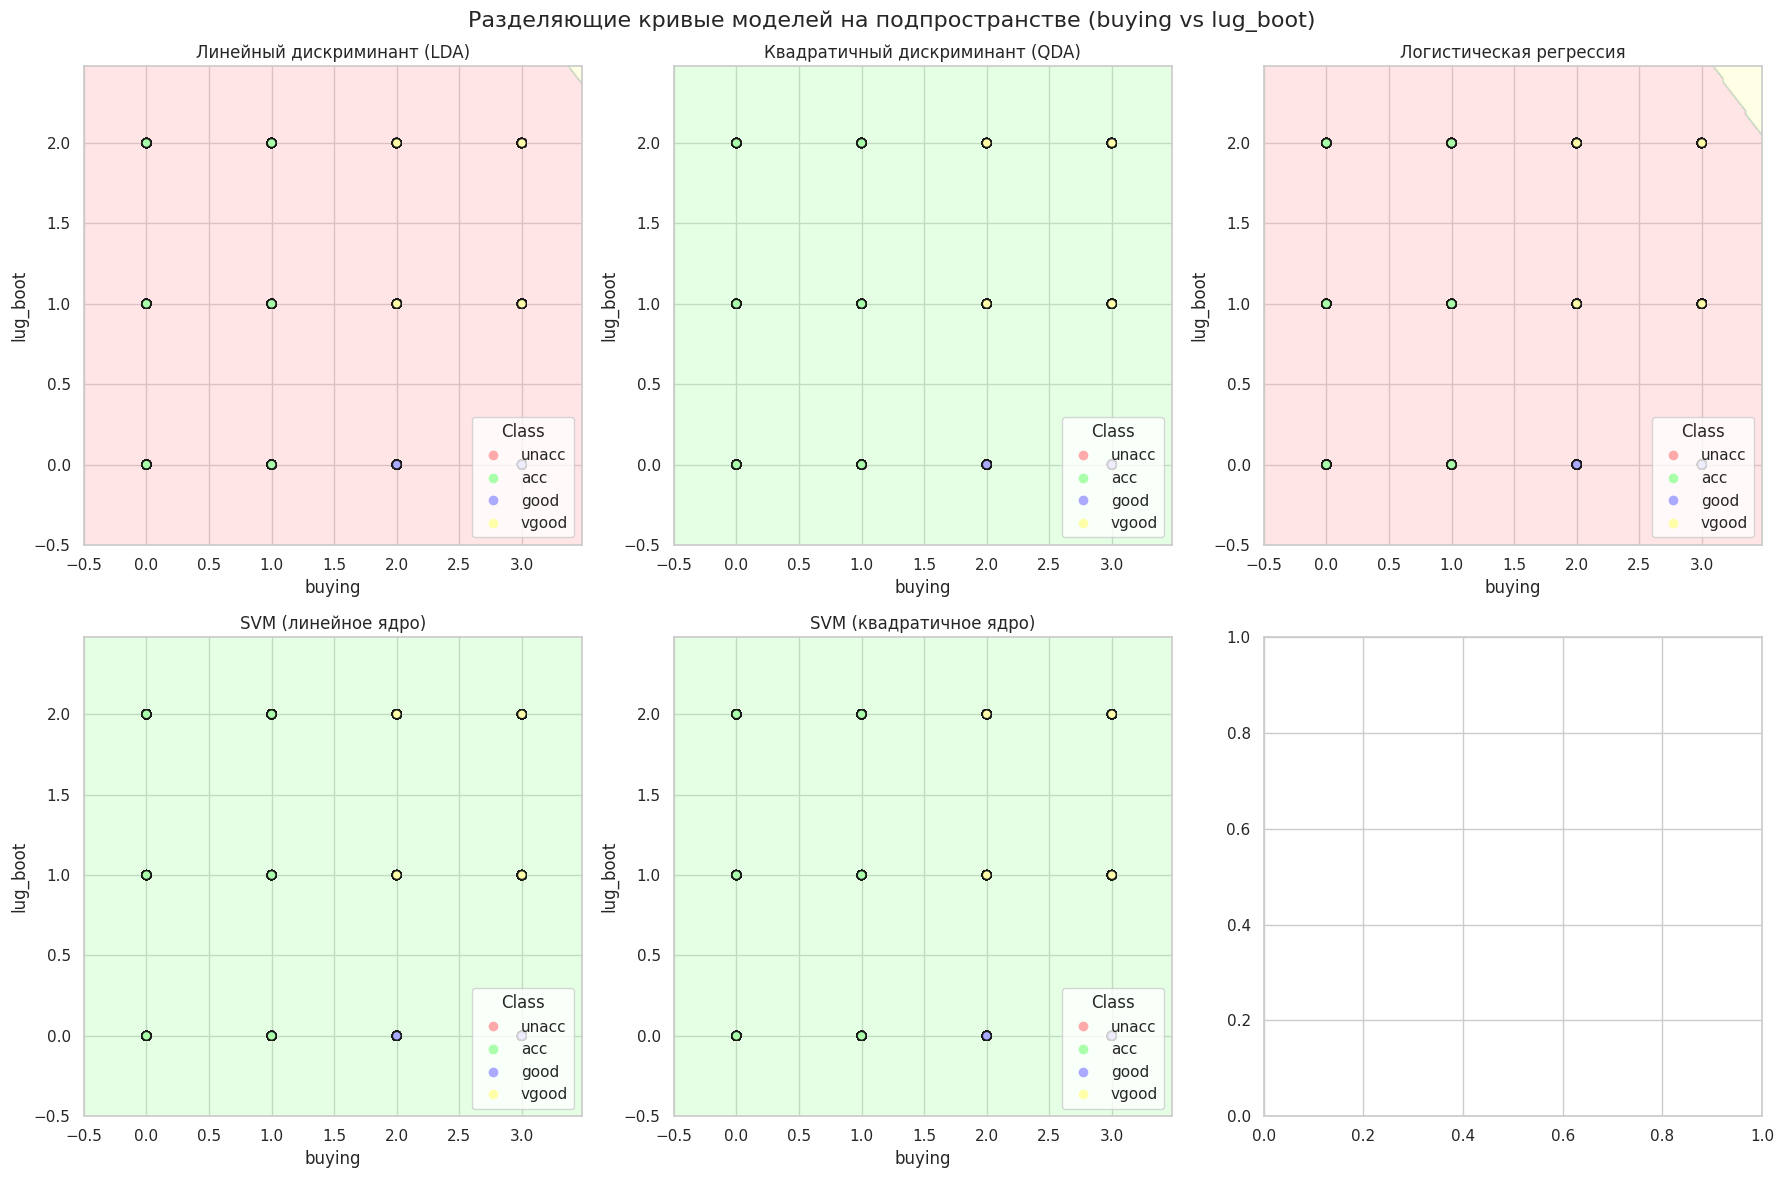

In [75]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_5[feat1_5].min() - 0.5, X_2d_5[feat1_5].max() + 0.5
y_min, y_max = X_2d_5[feat2_5].min() - 0.5, X_2d_5[feat2_5].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_5, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_5[feat1_5], X_2d_5[feat2_5], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_5)
        ax.set_ylabel(feat2_5)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_5)
        ax.set_ylabel(feat2_5)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 6 (по признакам 'buying' и 'safety')

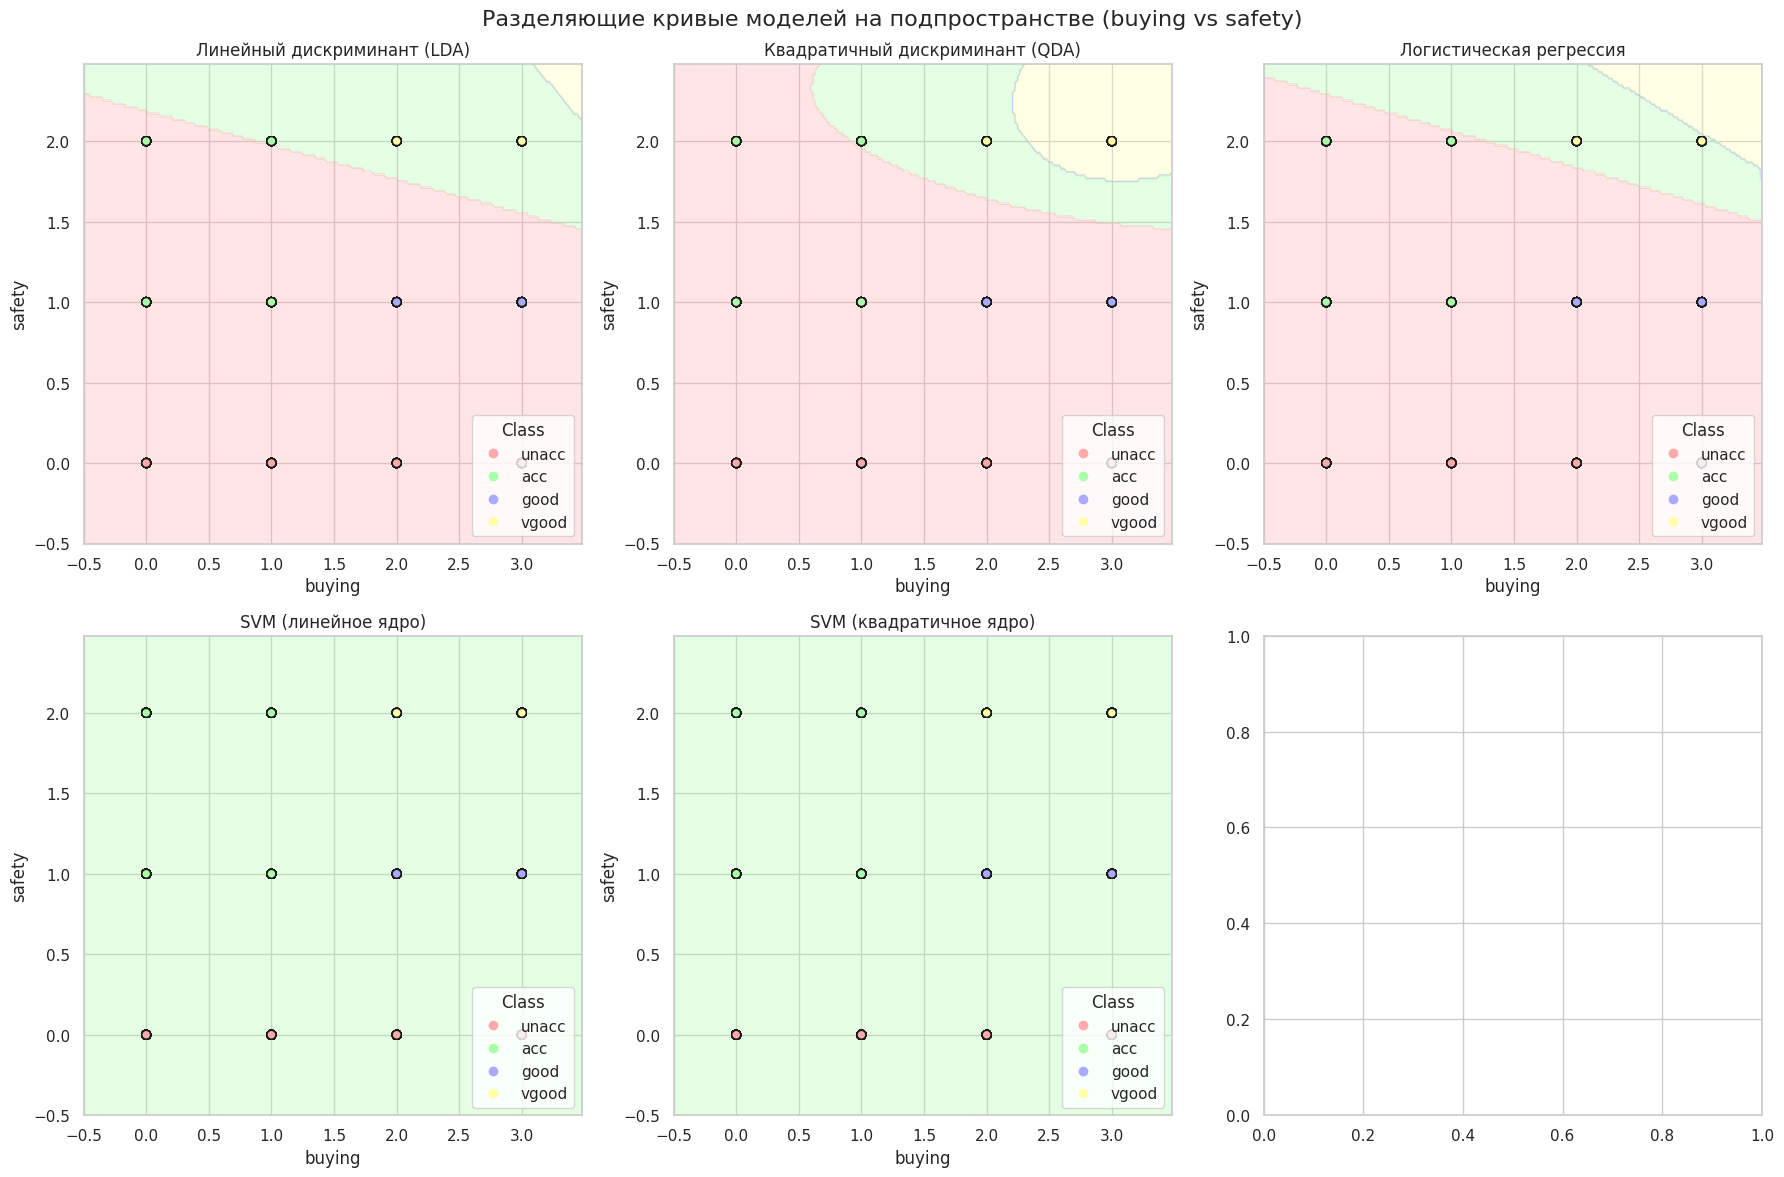

In [76]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_6[feat1_6].min() - 0.5, X_2d_6[feat1_6].max() + 0.5
y_min, y_max = X_2d_6[feat2_6].min() - 0.5, X_2d_6[feat2_6].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_6, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_6[feat1_6], X_2d_6[feat2_6], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_6)
        ax.set_ylabel(feat2_6)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_6)
        ax.set_ylabel(feat2_6)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 7 (по признакам 'maint' и 'doors')

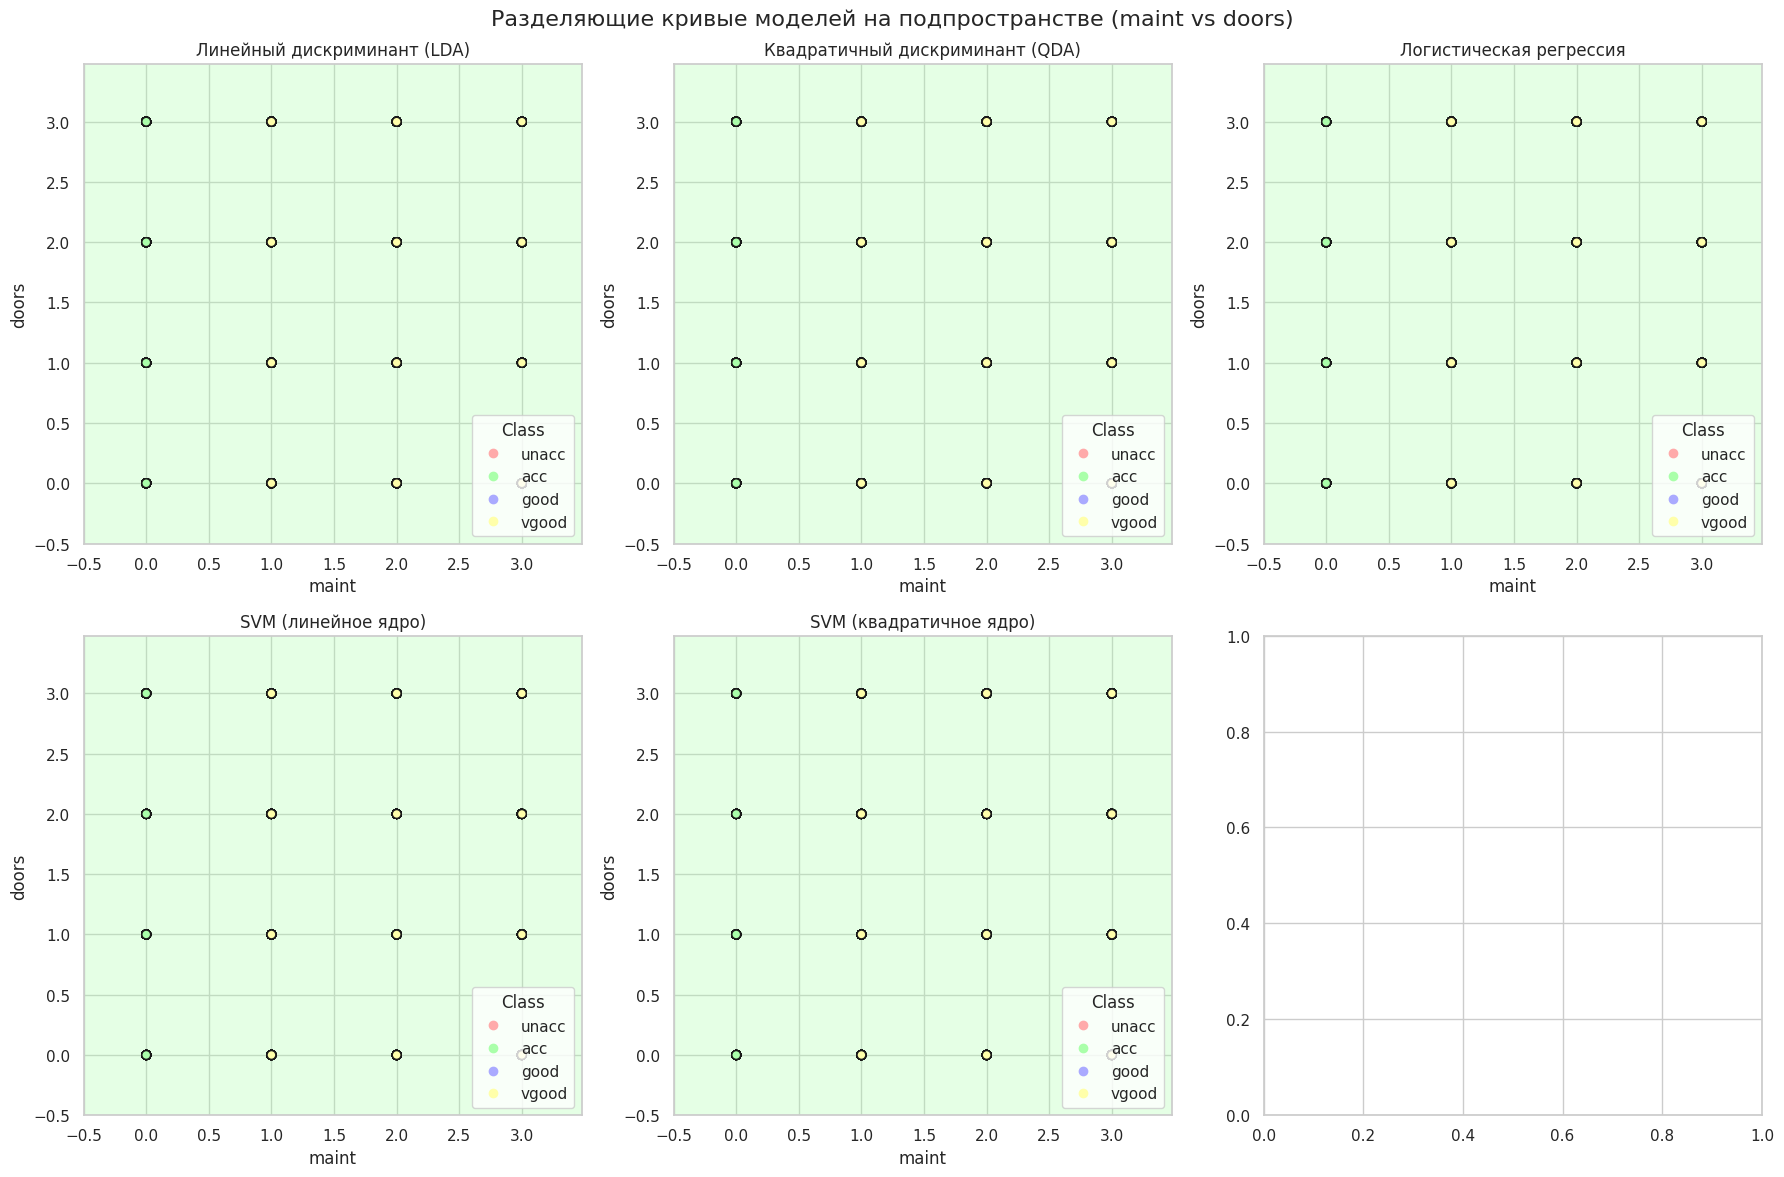

In [77]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_7[feat1_7].min() - 0.5, X_2d_7[feat1_7].max() + 0.5
y_min, y_max = X_2d_7[feat2_7].min() - 0.5, X_2d_7[feat2_7].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_7, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_7[feat1_7], X_2d_7[feat2_7], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_7)
        ax.set_ylabel(feat2_7)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_7)
        ax.set_ylabel(feat2_7)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs doors)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 8 (по признакам 'maint' и 'persons')

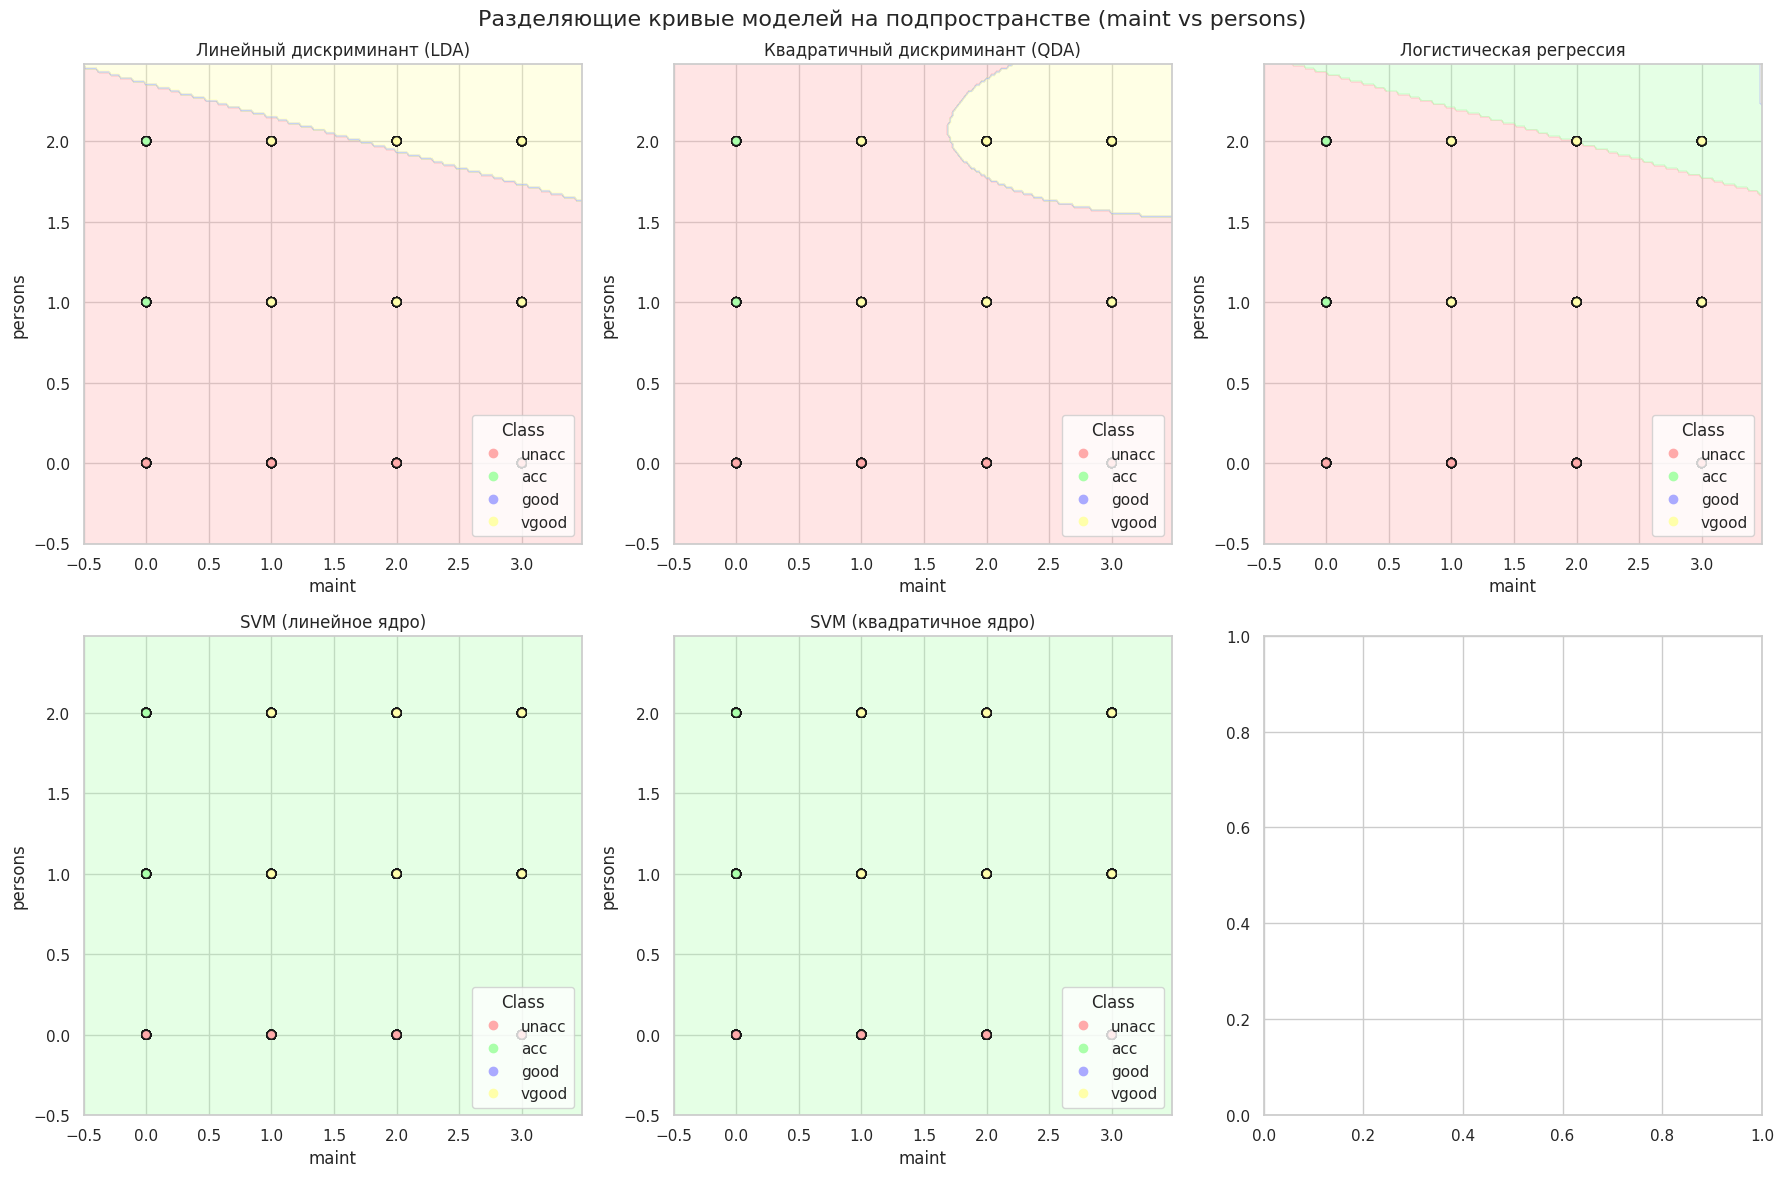

In [78]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_8[feat1_8].min() - 0.5, X_2d_8[feat1_8].max() + 0.5
y_min, y_max = X_2d_8[feat2_8].min() - 0.5, X_2d_8[feat2_8].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_8, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_8[feat1_8], X_2d_8[feat2_8], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_8)
        ax.set_ylabel(feat2_8)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_8)
        ax.set_ylabel(feat2_8)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 9 (по признакам 'maint' и 'lug_boot')

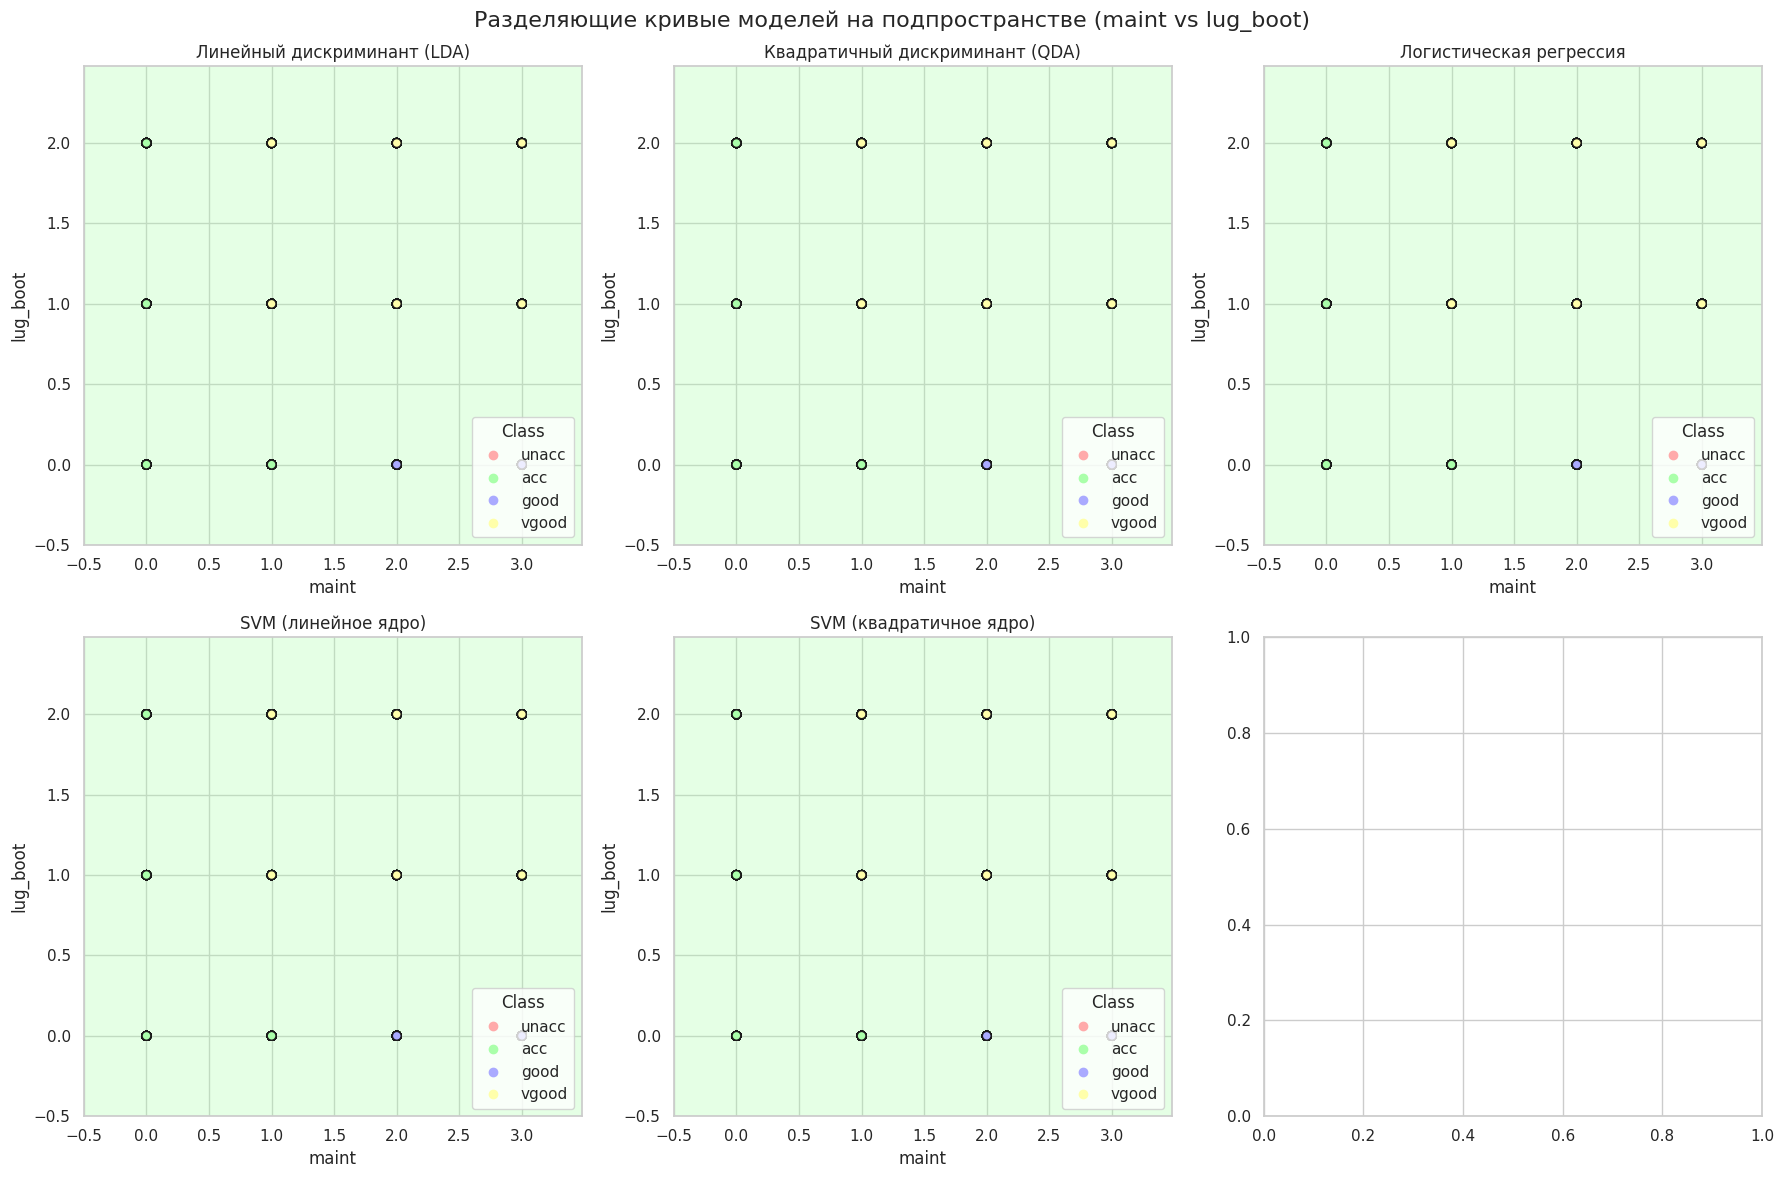

In [79]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_9[feat1_9].min() - 0.5, X_2d_9[feat1_9].max() + 0.5
y_min, y_max = X_2d_9[feat2_9].min() - 0.5, X_2d_9[feat2_9].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_9, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_9[feat1_9], X_2d_9[feat2_9], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_9)
        ax.set_ylabel(feat2_9)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_9)
        ax.set_ylabel(feat2_9)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 10 (по признакам 'maint' и 'safety')

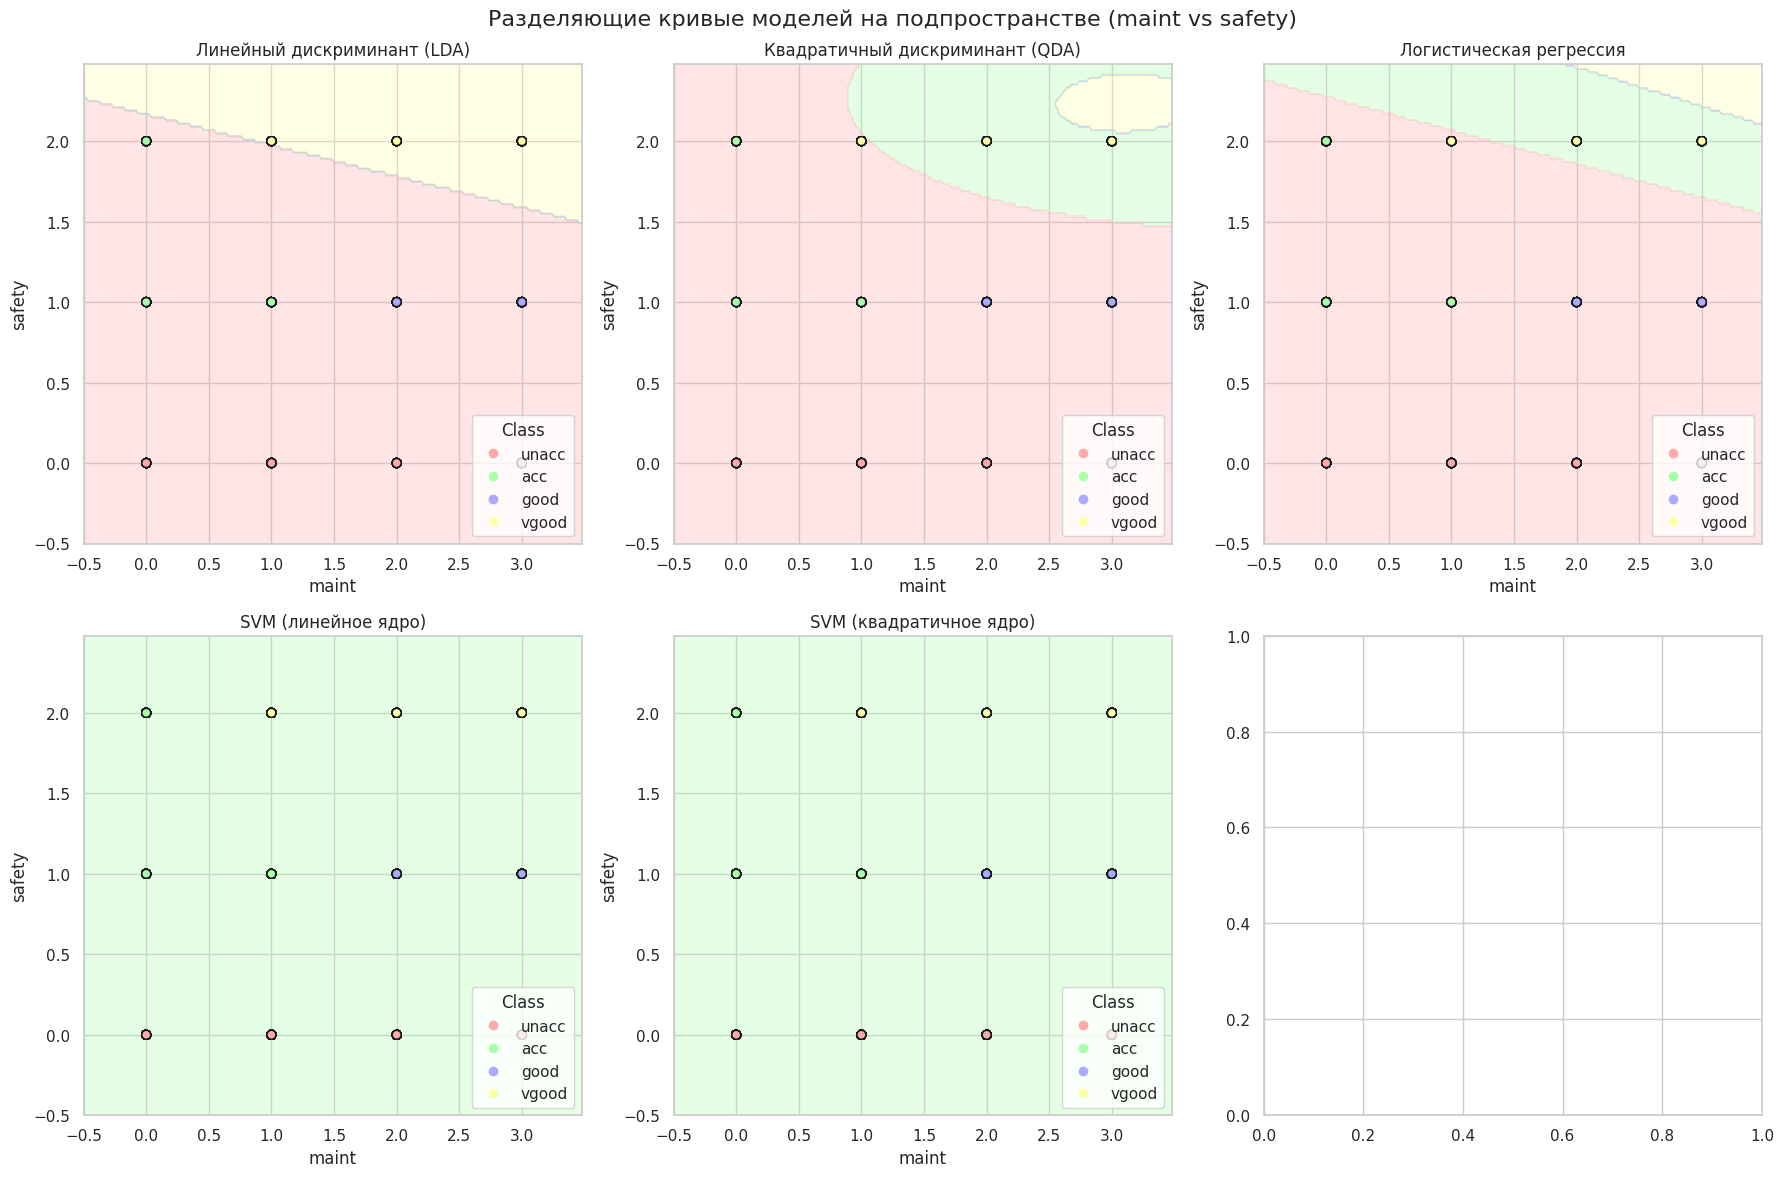

In [80]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_10[feat1_10].min() - 0.5, X_2d_10[feat1_10].max() + 0.5
y_min, y_max = X_2d_10[feat2_10].min() - 0.5, X_2d_10[feat2_10].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_10, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_10[feat1_10], X_2d_10[feat2_10], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_10)
        ax.set_ylabel(feat2_10)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_10)
        ax.set_ylabel(feat2_10)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 11 (по признакам 'doors' и 'persons')

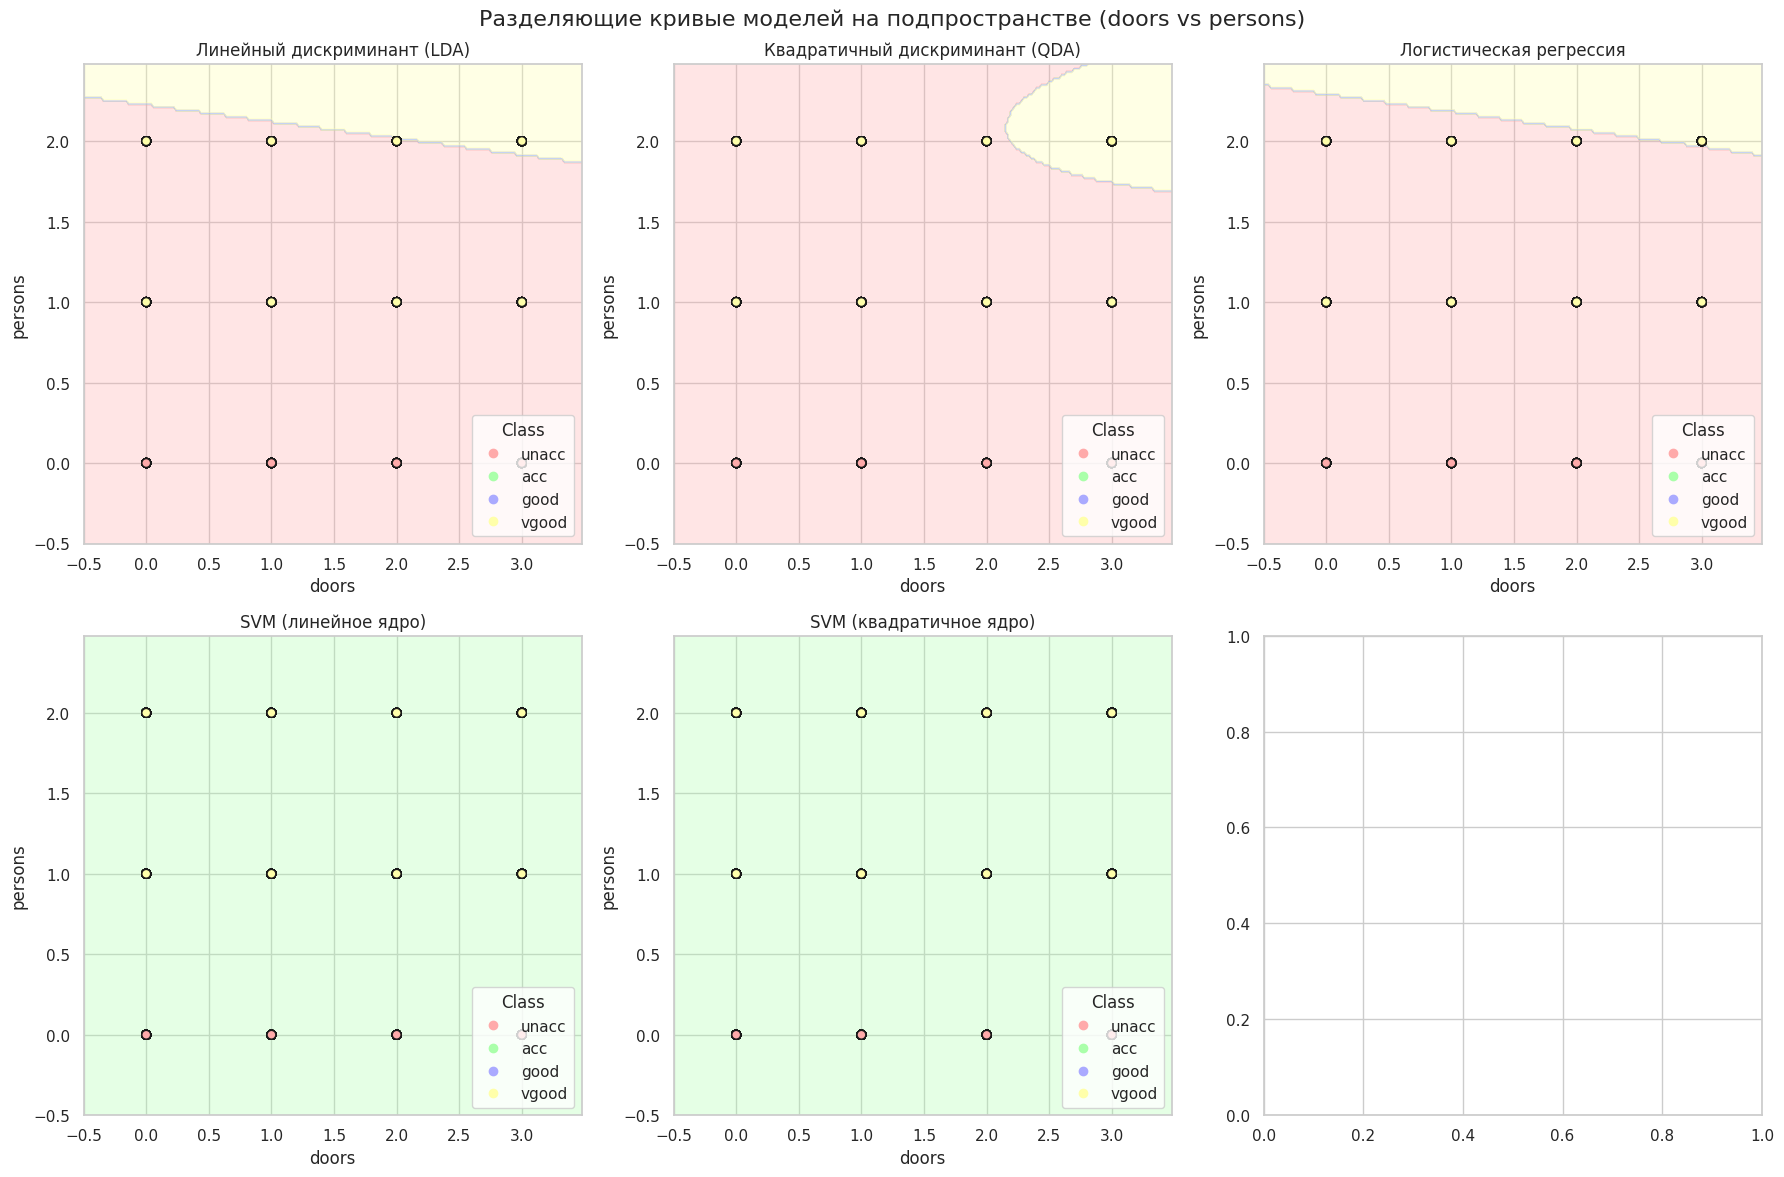

In [81]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_11[feat1_11].min() - 0.5, X_2d_11[feat1_11].max() + 0.5
y_min, y_max = X_2d_11[feat2_11].min() - 0.5, X_2d_11[feat2_11].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_11, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_11[feat1_11], X_2d_11[feat2_11], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_11)
        ax.set_ylabel(feat2_11)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_11)
        ax.set_ylabel(feat2_11)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 12 (по признакам 'doors' и 'lug_boot')

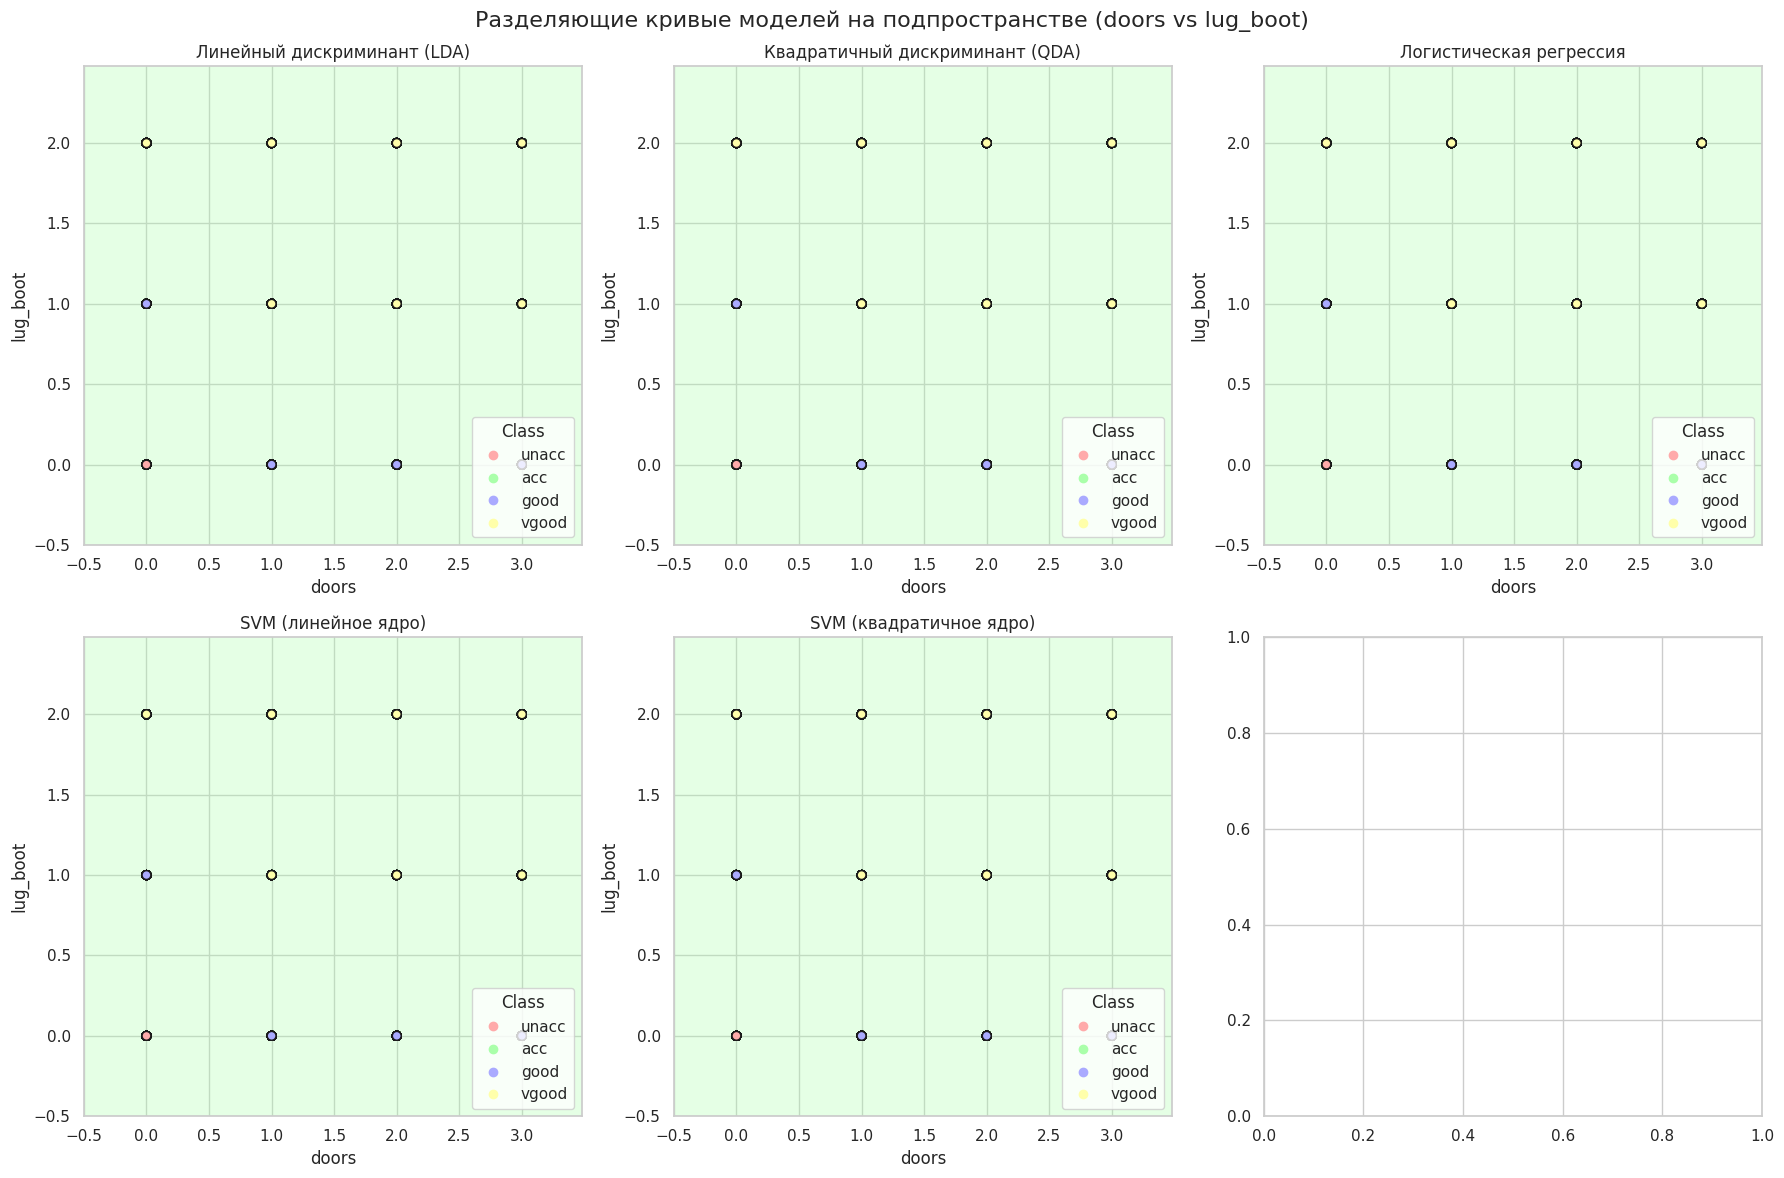

In [82]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_12[feat1_12].min() - 0.5, X_2d_12[feat1_12].max() + 0.5
y_min, y_max = X_2d_12[feat2_12].min() - 0.5, X_2d_12[feat2_12].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_12, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_12[feat1_12], X_2d_12[feat2_12], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_12)
        ax.set_ylabel(feat2_12)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_12)
        ax.set_ylabel(feat2_12)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 13 (по признакам 'doors' и 'safety')

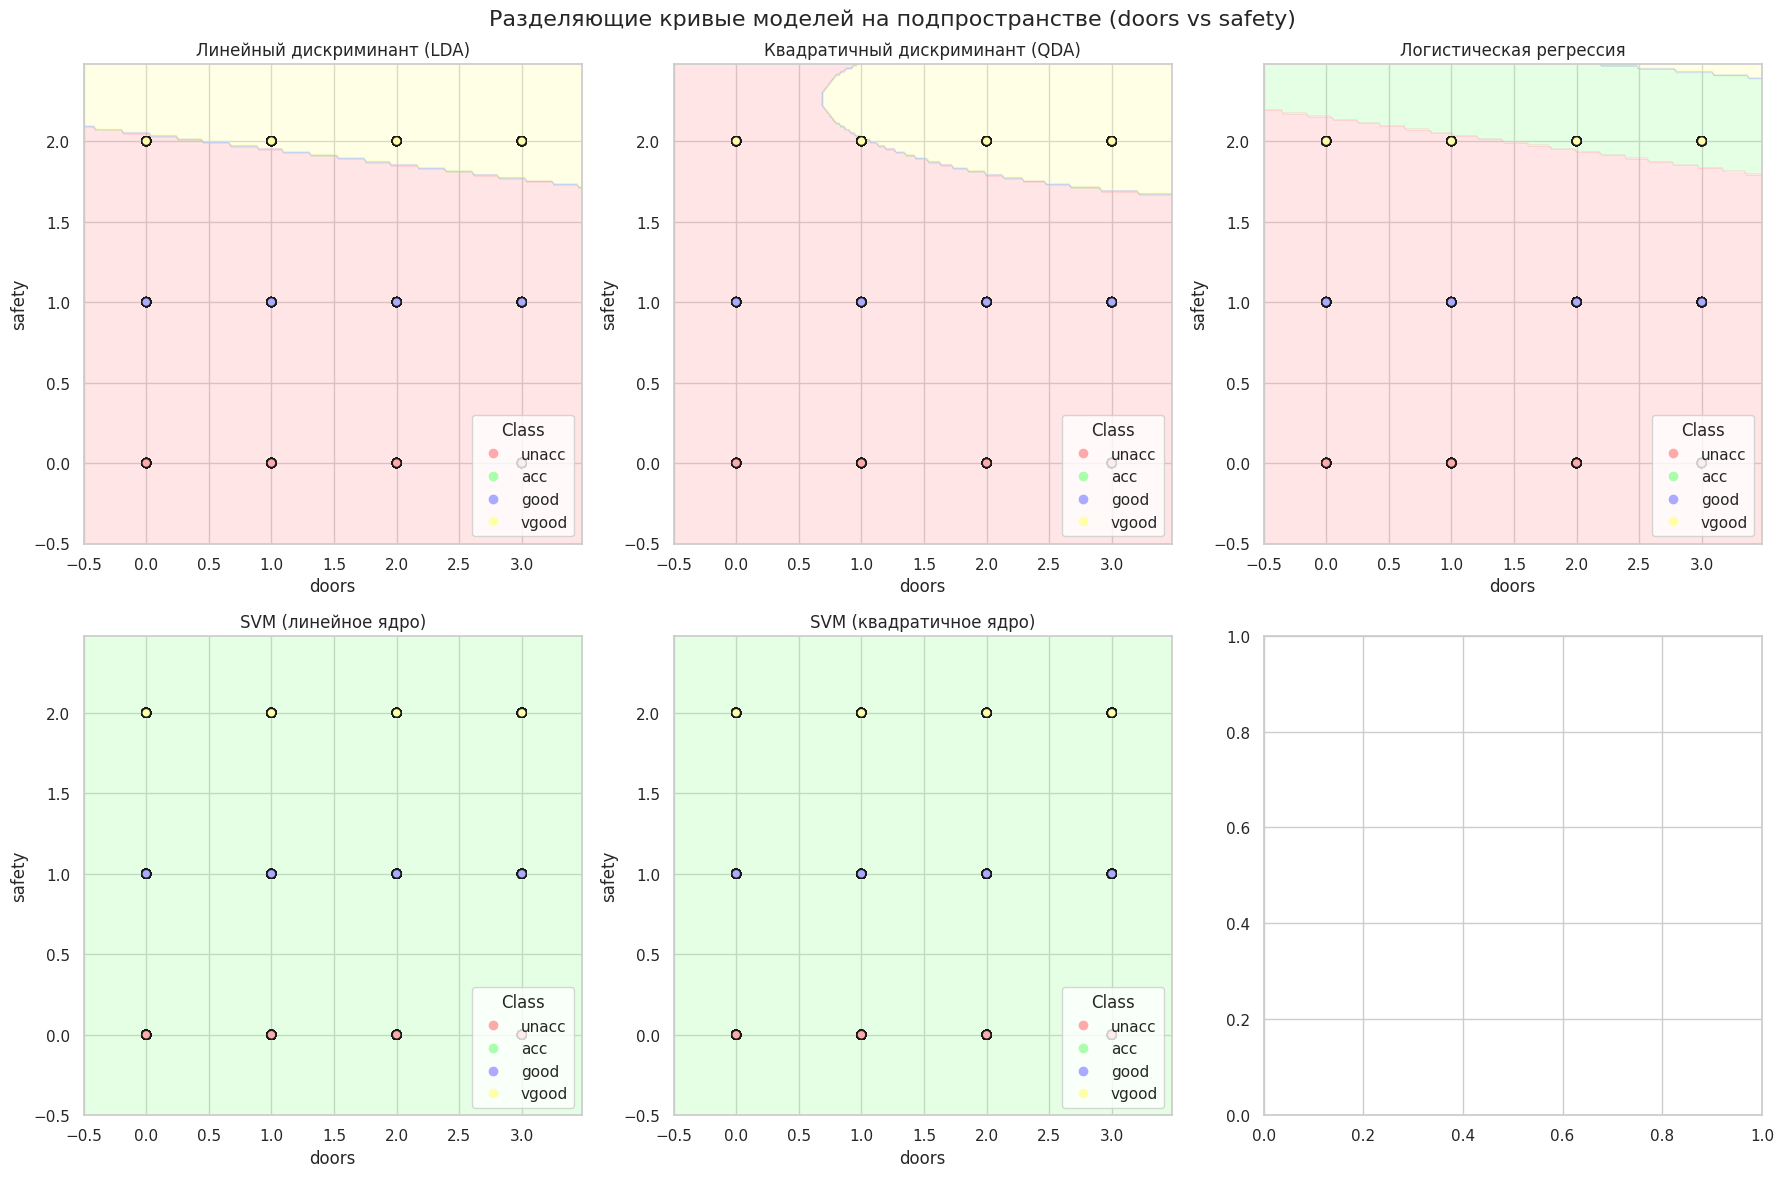

In [83]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_13[feat1_13].min() - 0.5, X_2d_13[feat1_13].max() + 0.5
y_min, y_max = X_2d_13[feat2_13].min() - 0.5, X_2d_13[feat2_13].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_13, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_13[feat1_13], X_2d_13[feat2_13], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_13)
        ax.set_ylabel(feat2_13)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_13)
        ax.set_ylabel(feat2_13)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 14 (по признакам 'persons' и 'lug_boot')

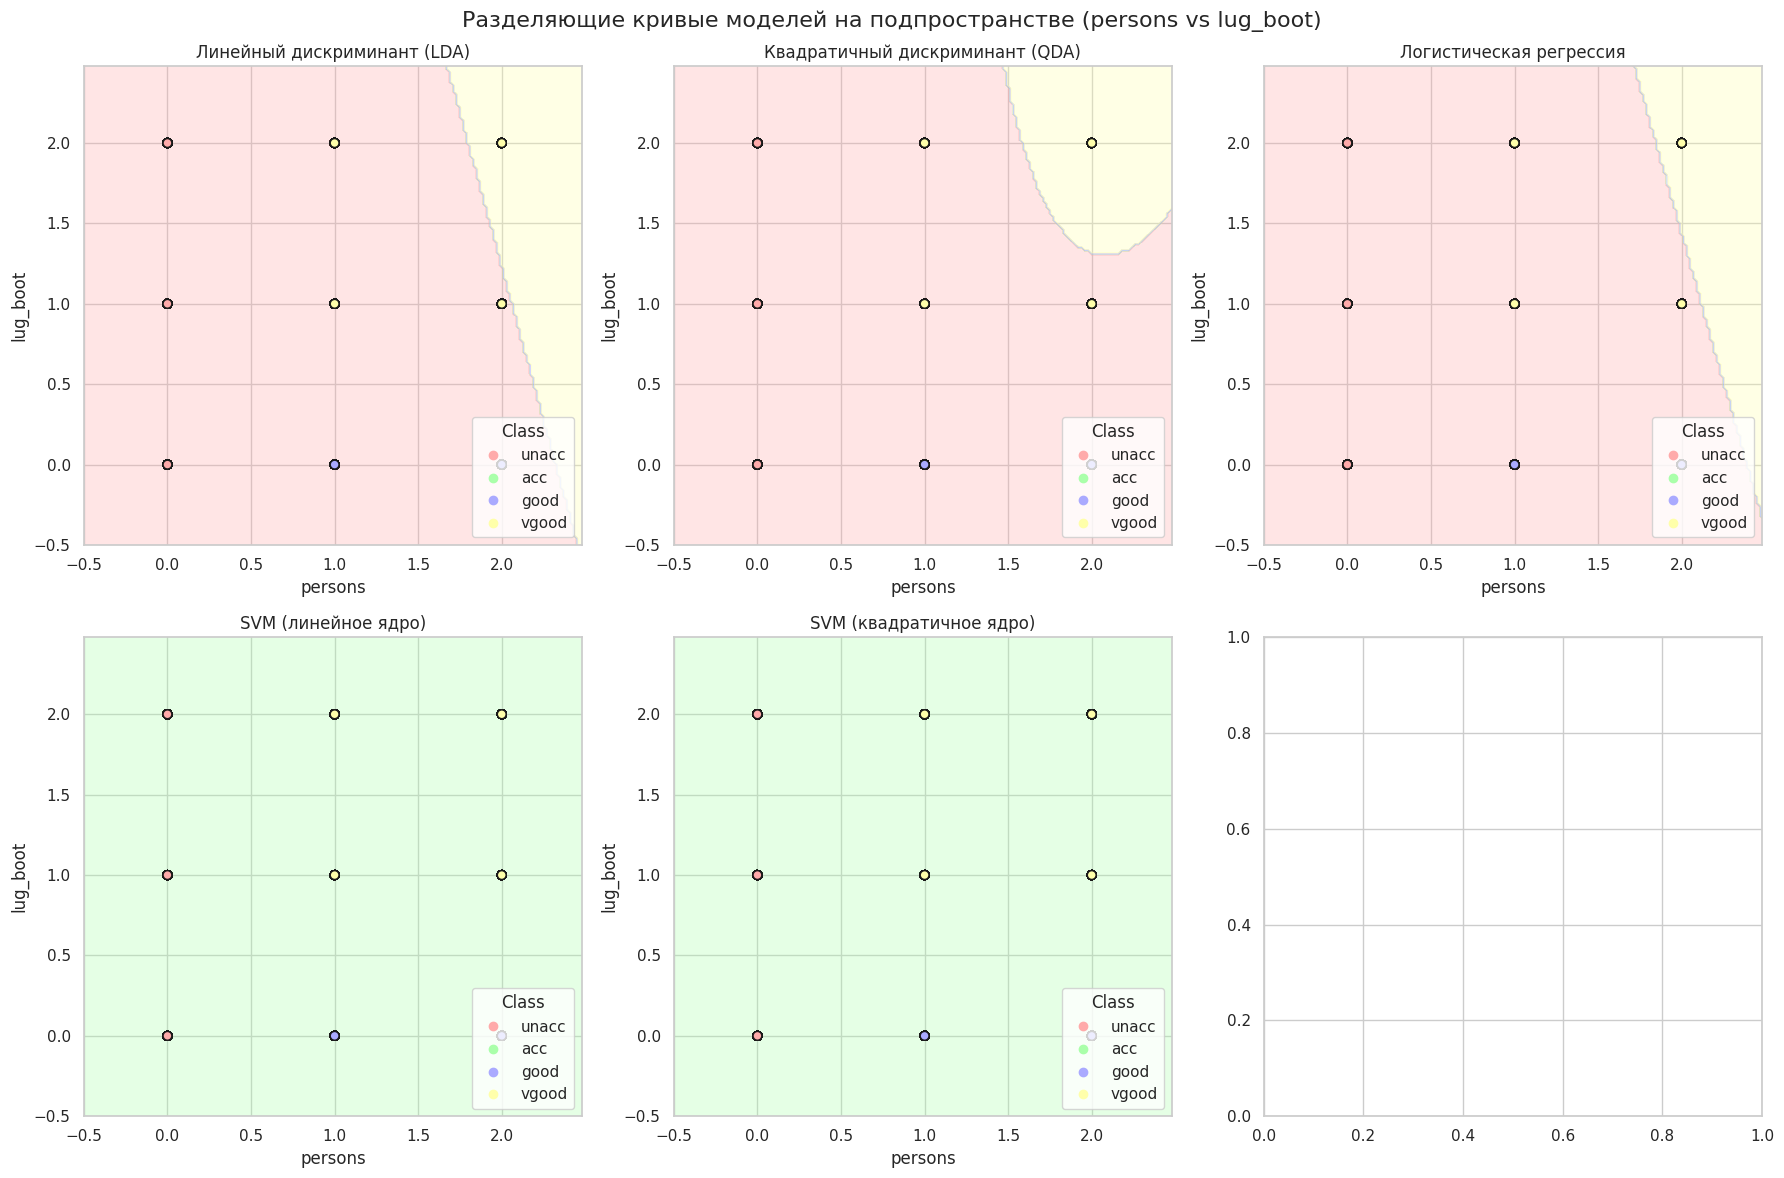

In [84]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_14[feat1_14].min() - 0.5, X_2d_14[feat1_14].max() + 0.5
y_min, y_max = X_2d_14[feat2_14].min() - 0.5, X_2d_14[feat2_14].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_14, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_14[feat1_14], X_2d_14[feat2_14], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_14)
        ax.set_ylabel(feat2_14)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_14)
        ax.set_ylabel(feat2_14)

plt.suptitle("Разделяющие кривые моделей на подпространстве (persons vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 15 (по признакам 'lug_boot' и 'safety')

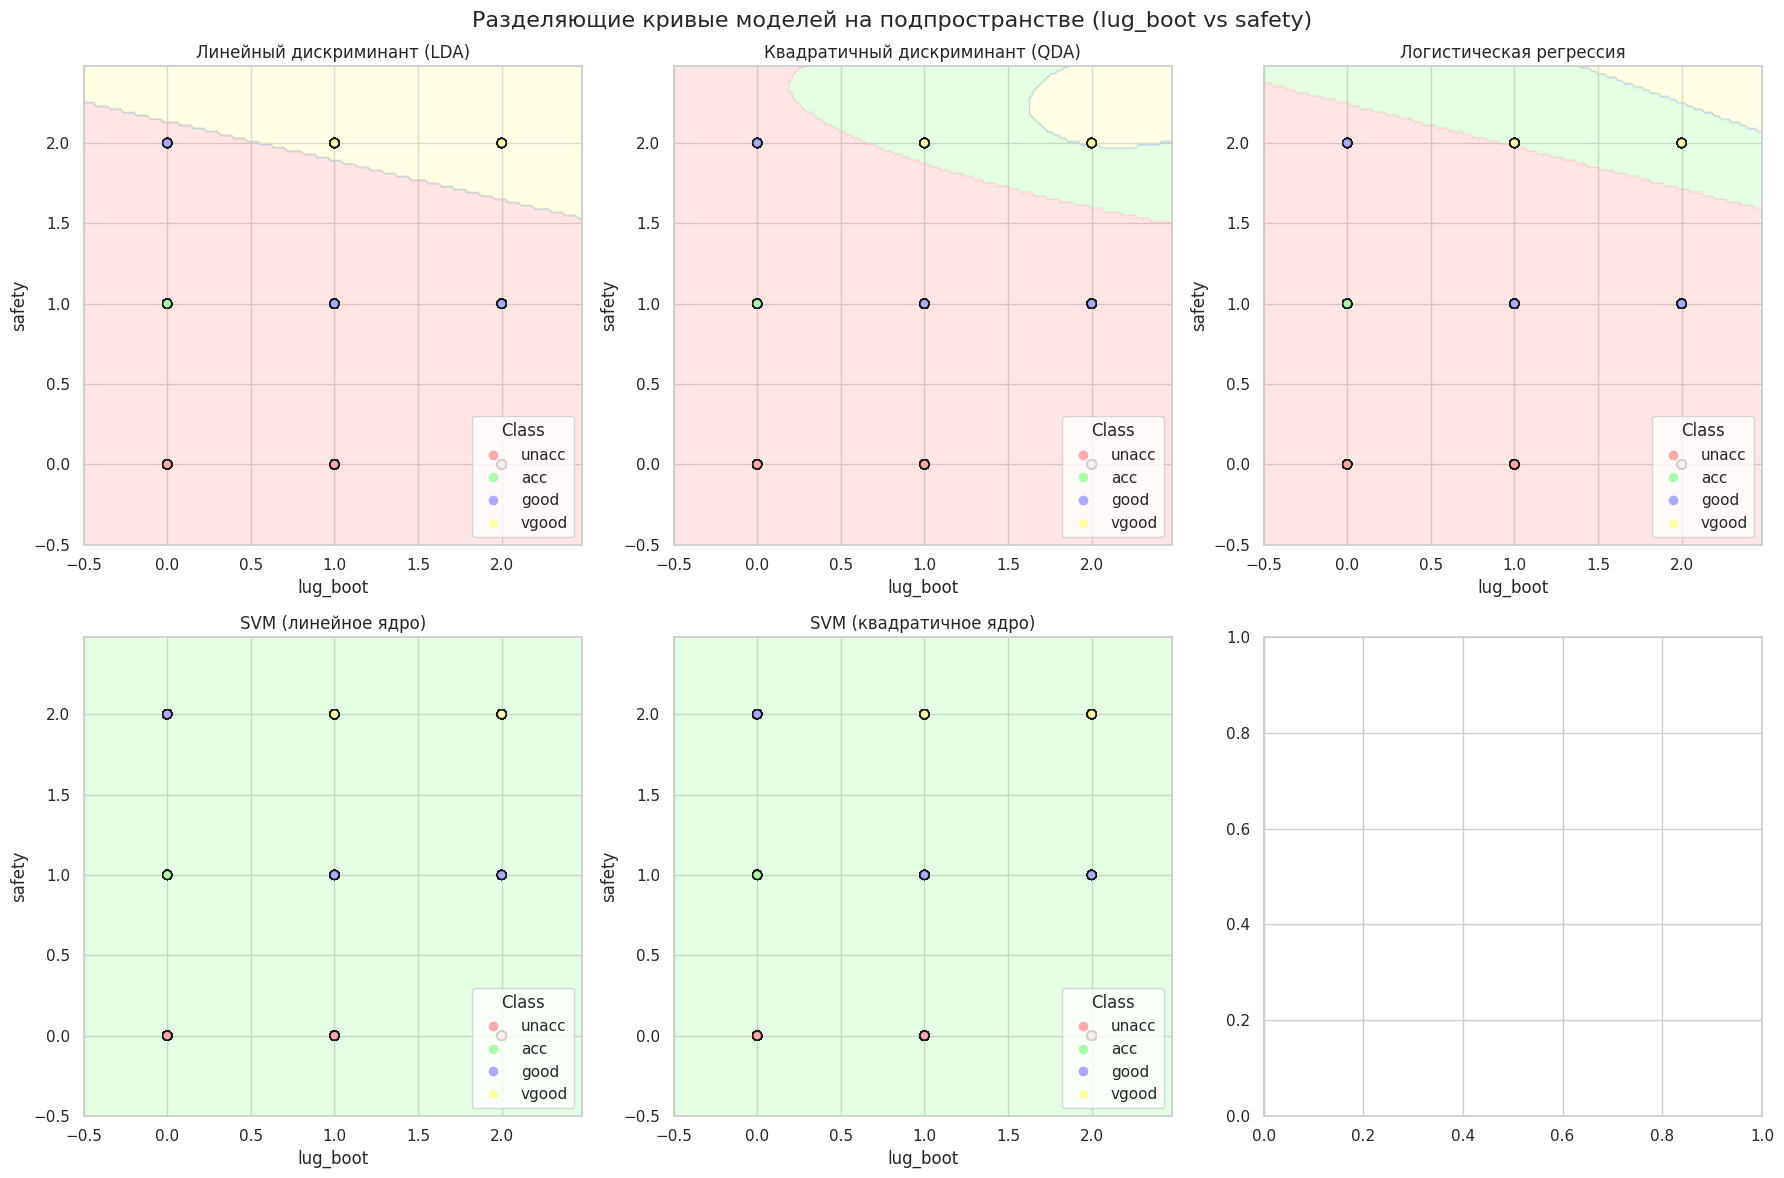

In [85]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_15[feat1_15].min() - 0.5, X_2d_15[feat1_15].max() + 0.5
y_min, y_max = X_2d_15[feat2_15].min() - 0.5, X_2d_15[feat2_15].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_15, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_15[feat1_15], X_2d_15[feat2_15], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_15)
        ax.set_ylabel(feat2_15)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_15)
        ax.set_ylabel(feat2_15)

plt.suptitle("Разделяющие кривые моделей на подпространстве (lug_boot vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

## 3. Оптимизация гиперпараметров (Optuna)
Был проведен поиск оптимальных гиперпараметров для каждой модели (50 итераций на модель). 
**Ключевые наблюдения:**
- **SVM (poly)** показал наибольший прирост качества (+0.0353), достигнув почти идеальной точности благодаря подбору степени полинома (`degree=3`) и коэффициента регуляризации `C`.
- **QDA** также улучшил свои показатели за счет точной настройки параметра регуляризации `reg_param`, что стабилизировало обращение ковариационных матриц для миноритарных классов.
- Линейные модели (LDA, Logistic Regression) достигли своего "потолка" производительности, так как их ограничения связаны с линейной природой данных, а не с гиперпараметрами.

### Вариант 2: Подбор гиперпараметров через Optuna

In [ ]:
def objective_lda(trial: optuna.Trial) -> float:
    """Оптимизация параметров LDA"""
    solver: str = trial.suggest_categorical('solver', ['svd', 'lsqr', 'eigen'])
    
    # shrinkage доступен только для solver='lsqr'
    if solver == 'lsqr':
        shrinkage = trial.suggest_categorical('shrinkage', [None, 'auto'])
        if shrinkage == 'auto':
            model = LinearDiscriminantAnalysis(solver=solver, shrinkage=shrinkage)
        else:
            model = LinearDiscriminantAnalysis(solver=solver)
    else:
        model = LinearDiscriminantAnalysis(solver=solver)
    
    scores = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_qda(trial: optuna.Trial) -> float:
    """Оптимизация параметров QDA"""
    reg_param: float = trial.suggest_float('reg_param', 1e-5, 1.0, log=True)
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    
    model = QuadraticDiscriminantAnalysis(reg_param=reg_param, tol=tol)
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_logistic(trial: optuna.Trial) -> float:
    """Оптимизация параметров Logistic Regression"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    solver: str = trial.suggest_categorical('solver', ['lbfgs', 'newton-cg', 'sag', 'saga'])
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = LogisticRegression(
        C=C, 
        solver=solver, 
        max_iter=1000, 
        tol=tol, 
        class_weight=class_weight,
        random_state=RANDOM_STATE
    )
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_svm_linear(trial: optuna.Trial) -> float:
    """Оптимизация параметров SVM с линейным ядром"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = SVC(
        kernel='linear', 
        C=C, 
        tol=tol,
        class_weight=class_weight,
        probability=True, 
        random_state=RANDOM_STATE
    )
    scores: np.ndarray = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

def objective_svm_poly(trial: optuna.Trial) -> float:
    """Оптимизация параметров SVM с полиномиальным ядром"""
    C: float = trial.suggest_float('C', 1e-4, 100, log=True)
    degree: int = trial.suggest_int('degree', 2, 5)
    gamma: str = trial.suggest_categorical('gamma', ['scale', 'auto'])
    tol: float = trial.suggest_float('tol', 1e-8, 1e-3, log=True)
    class_weight = trial.suggest_categorical('class_weight', [None, 'balanced'])
    
    model = SVC(
        kernel='poly', 
        C=C, 
        degree=degree,
        gamma=gamma,
        tol=tol,
        class_weight=class_weight,
        probability=True, 
        random_state=RANDOM_STATE
    )
    scores = cross_val_score(model, X_all, y, cv=5, scoring='accuracy')
    return scores.mean()

In [ ]:
print("=" * 70)
print("НАЧАЛО ОПТИМИЗАЦИИ ГИПЕРПАРАМЕТРОВ ЧЕРЕЗ OPTUNA")
print("=" * 70)

optimization_results: Dict[str, Dict[str, optuna.Study]] = {}

# LDA
print("\n📊 Оптимизация LDA...")
study_lda: optuna.Study = optuna.create_study(direction='maximize')
study_lda.optimize(objective_lda, n_trials=50, show_progress_bar=True)
optimization_results['LDA'] = {
    'best_params': study_lda.best_params,
    'best_score': study_lda.best_value
}
print(f"   ✅ Лучшая accuracy: {study_lda.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_lda.best_params}")

# QDA
print("\n📊 Оптимизация QDA...")
study_qda: optuna.Study = optuna.create_study(direction='maximize')
study_qda.optimize(objective_qda, n_trials=50, show_progress_bar=True)
optimization_results['QDA'] = {
    'best_params': study_qda.best_params,
    'best_score': study_qda.best_value
}
print(f"   ✅ Лучшая accuracy: {study_qda.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_qda.best_params}")

# Logistic Regression
print("\n📊 Оптимизация Logistic Regression...")
study_lr: optuna.Study = optuna.create_study(direction='maximize')
study_lr.optimize(objective_logistic, n_trials=50, show_progress_bar=True)
optimization_results['Logistic'] = {
    'best_params': study_lr.best_params,
    'best_score': study_lr.best_value
}
print(f"   ✅ Лучшая accuracy: {study_lr.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_lr.best_params}")

# SVM Linear
print("\n📊 Оптимизация SVM (linear)...")
study_svm_lin: optuna.Study = optuna.create_study(direction='maximize')
study_svm_lin.optimize(objective_svm_linear, n_trials=50, show_progress_bar=True)
optimization_results['SVM_linear'] = {
    'best_params': study_svm_lin.best_params,
    'best_score': study_svm_lin.best_value
}
print(f"   ✅ Лучшая accuracy: {study_svm_lin.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_svm_lin.best_params}")

# SVM Poly
print("\n📊 Оптимизация SVM (poly)...")
study_svm_poly: optuna.Study = optuna.create_study(direction='maximize')
study_svm_poly.optimize(objective_svm_poly, n_trials=50, show_progress_bar=True)
optimization_results['SVM_poly'] = {
    'best_params': study_svm_poly.best_params,
    'best_score': study_svm_poly.best_value
}
print(f"   ✅ Лучшая accuracy: {study_svm_poly.best_value:.4f}")
print(f"   ✅ Лучшие параметры: {study_svm_poly.best_params}")

НАЧАЛО ОПТИМИЗАЦИИ ГИПЕРПАРАМЕТРОВ ЧЕРЕЗ OPTUNA

📊 Оптимизация LDA...


Best trial: 10. Best value: 0.767347: 100%|██████████| 50/50 [00:00<00:00, 51.45it/s]


   ✅ Лучшая accuracy: 0.7673
   ✅ Лучшие параметры: {'solver': 'lsqr', 'shrinkage': 'auto'}

📊 Оптимизация QDA...


Best trial: 33. Best value: 0.848984: 100%|██████████| 50/50 [00:00<00:00, 71.09it/s]


   ✅ Лучшая accuracy: 0.8490
   ✅ Лучшие параметры: {'reg_param': 0.04279225889085967, 'tol': 4.772625473438607e-05}

📊 Оптимизация Logistic Regression...


Best trial: 21. Best value: 0.763872: 100%|██████████| 50/50 [00:10<00:00,  4.60it/s]


   ✅ Лучшая accuracy: 0.7639
   ✅ Лучшие параметры: {'C': 0.1636128616124501, 'solver': 'newton-cg', 'tol': 1.6076142270185676e-07, 'class_weight': None}

📊 Оптимизация SVM (linear)...


Best trial: 17. Best value: 0.785318: 100%|██████████| 50/50 [00:31<00:00,  1.59it/s]


   ✅ Лучшая accuracy: 0.7853
   ✅ Лучшие параметры: {'C': 0.021556363409305203, 'tol': 0.0007339255287449307, 'class_weight': None}

📊 Оптимизация SVM (poly)...


Best trial: 42. Best value: 0.883068: 100%|██████████| 50/50 [01:12<00:00,  1.44s/it]

   ✅ Лучшая accuracy: 0.8831
   ✅ Лучшие параметры: {'C': 5.813202252139866, 'degree': 3, 'gamma': 'auto', 'tol': 0.0004910140363342296, 'class_weight': None}


In [ ]:
print("\n" + "=" * 70)
print("СОЗДАНИЕ МОДЕЛЕЙ С ОПТИМАЛЬНЫМИ ПАРАМЕТРАМИ")
print("=" * 70)

models_optimized: Dict[str, Any] = {}

# LDA
lda_params: optuna.Study = optimization_results['LDA']['best_params']
if lda_params.get('solver') == 'lsqr' and lda_params.get('shrinkage') == 'auto':
    models_optimized['Линейный дискриминант (LDA)'] = LinearDiscriminantAnalysis(
        solver=lda_params['solver'],
        shrinkage=lda_params['shrinkage']
    )
else:
    models_optimized['Линейный дискриминант (LDA)'] = LinearDiscriminantAnalysis(
        solver=lda_params.get('solver', 'svd')
    )

# QDA
qda_params: optuna.Study = optimization_results['QDA']['best_params']
models_optimized['Квадратичный дискриминант (QDA)'] = QuadraticDiscriminantAnalysis(
    reg_param=qda_params['reg_param'],
    tol=qda_params['tol']
)

# Logistic Regression
lr_params: optuna.Study = optimization_results['Logistic']['best_params']
models_optimized['Логистическая регрессия'] = LogisticRegression(
    C=lr_params['C'],
    solver=lr_params['solver'],
    max_iter=1000,
    tol=lr_params['tol'],
    class_weight=lr_params['class_weight'],
    random_state=RANDOM_STATE
)

# SVM Linear
svm_lin_params: optuna.Study = optimization_results['SVM_linear']['best_params']
models_optimized['SVM (линейное ядро)'] = SVC(
    kernel='linear',
    C=svm_lin_params['C'],
    tol=svm_lin_params['tol'],
    class_weight=svm_lin_params['class_weight'],
    probability=True,
    random_state=RANDOM_STATE
)

# SVM Poly
svm_poly_params: optuna.Study = optimization_results['SVM_poly']['best_params']
models_optimized['SVM (квадратичное ядро)'] = SVC(
    kernel='poly',
    C=svm_poly_params['C'],
    degree=svm_poly_params['degree'],
    gamma=svm_poly_params['gamma'],
    tol=svm_poly_params['tol'],
    class_weight=svm_poly_params['class_weight'],
    probability=True,
    random_state=RANDOM_STATE
)


СОЗДАНИЕ МОДЕЛЕЙ С ОПТИМАЛЬНЫМИ ПАРАМЕТРАМИ


## Визуализация разделяющих кривых для 2D подпространства (Случай с Optuna)

### Сравнение 1 (по признакам 'safety' и 'persons')

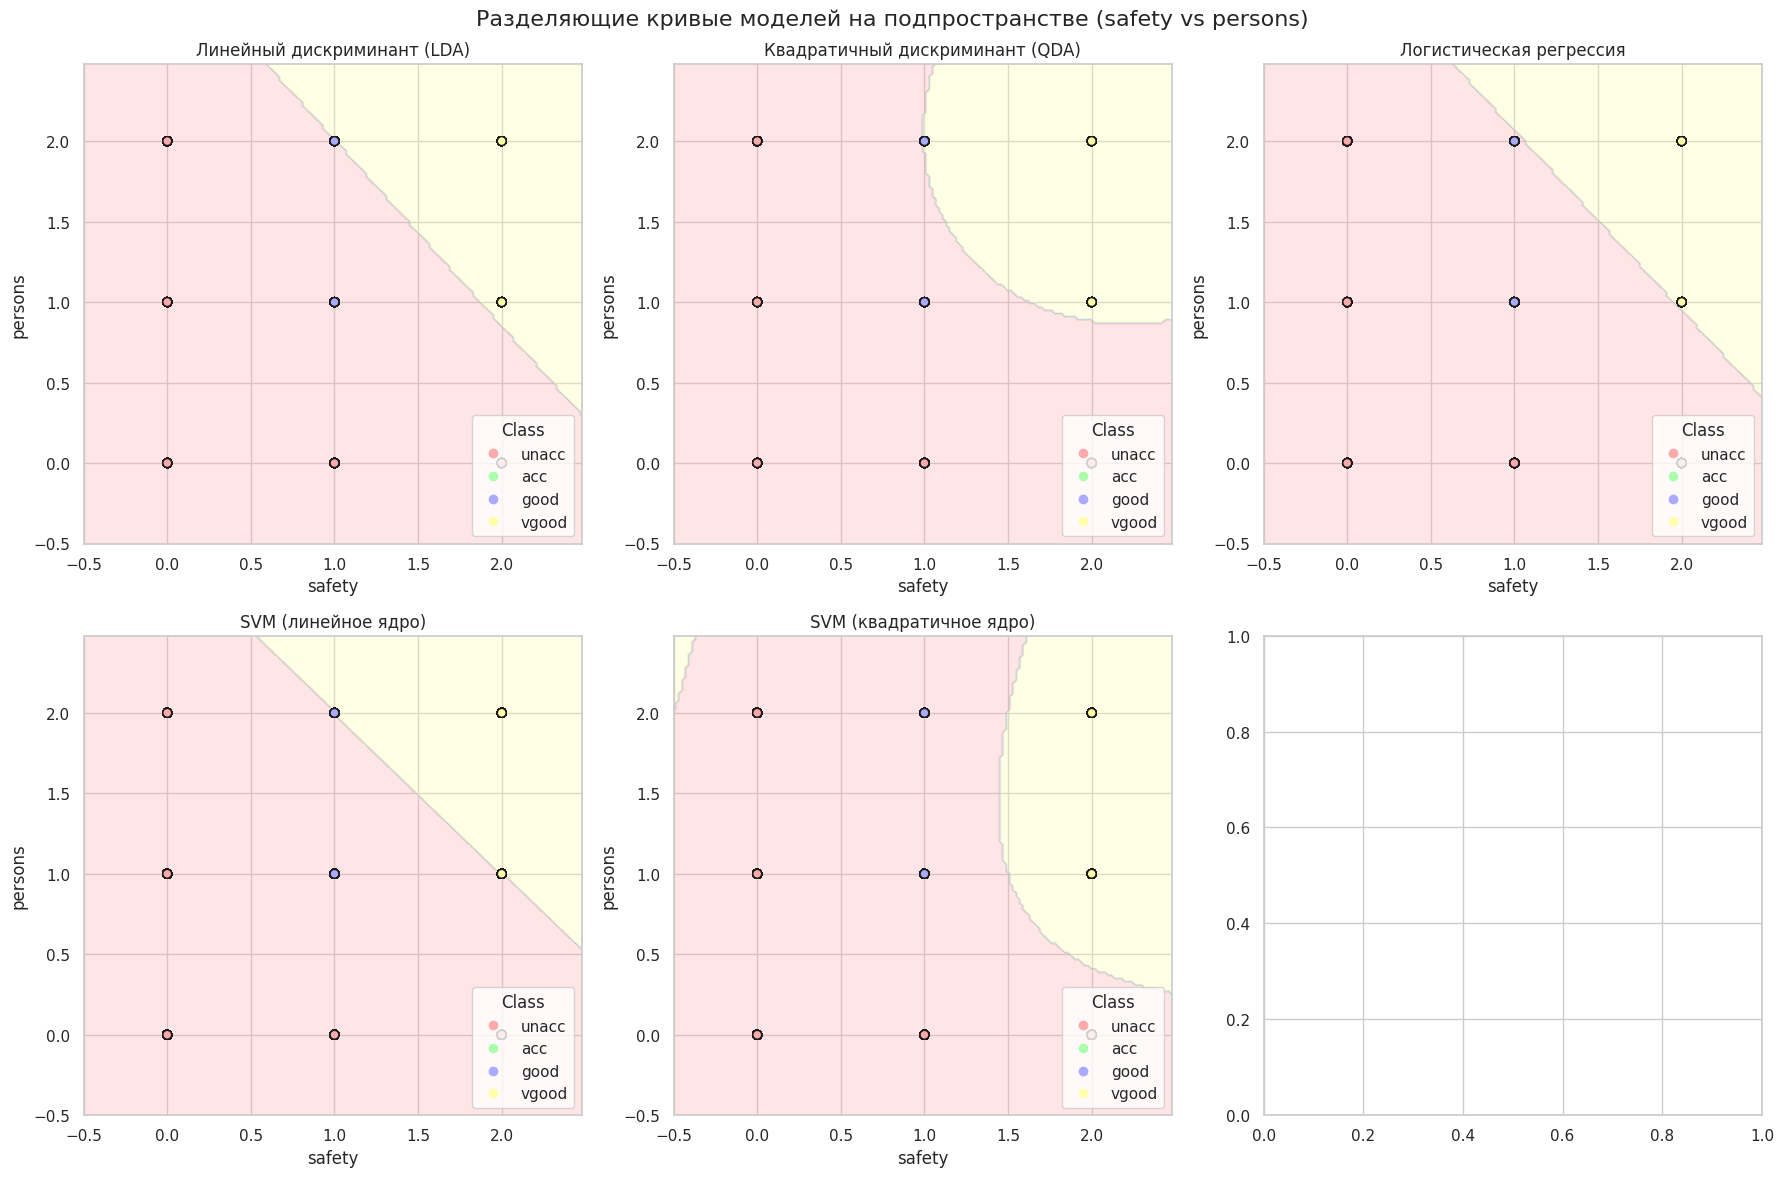

In [91]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_1[feat1_1].min() - 0.5, X_2d_1[feat1_1].max() + 0.5
y_min, y_max = X_2d_1[feat2_1].min() - 0.5, X_2d_1[feat2_1].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_1, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_1[feat1_1], X_2d_1[feat2_1], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_1)
        ax.set_ylabel(feat2_1)

plt.suptitle("Разделяющие кривые моделей на подпространстве (safety vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 2 (по признакам 'buying' и 'maint')

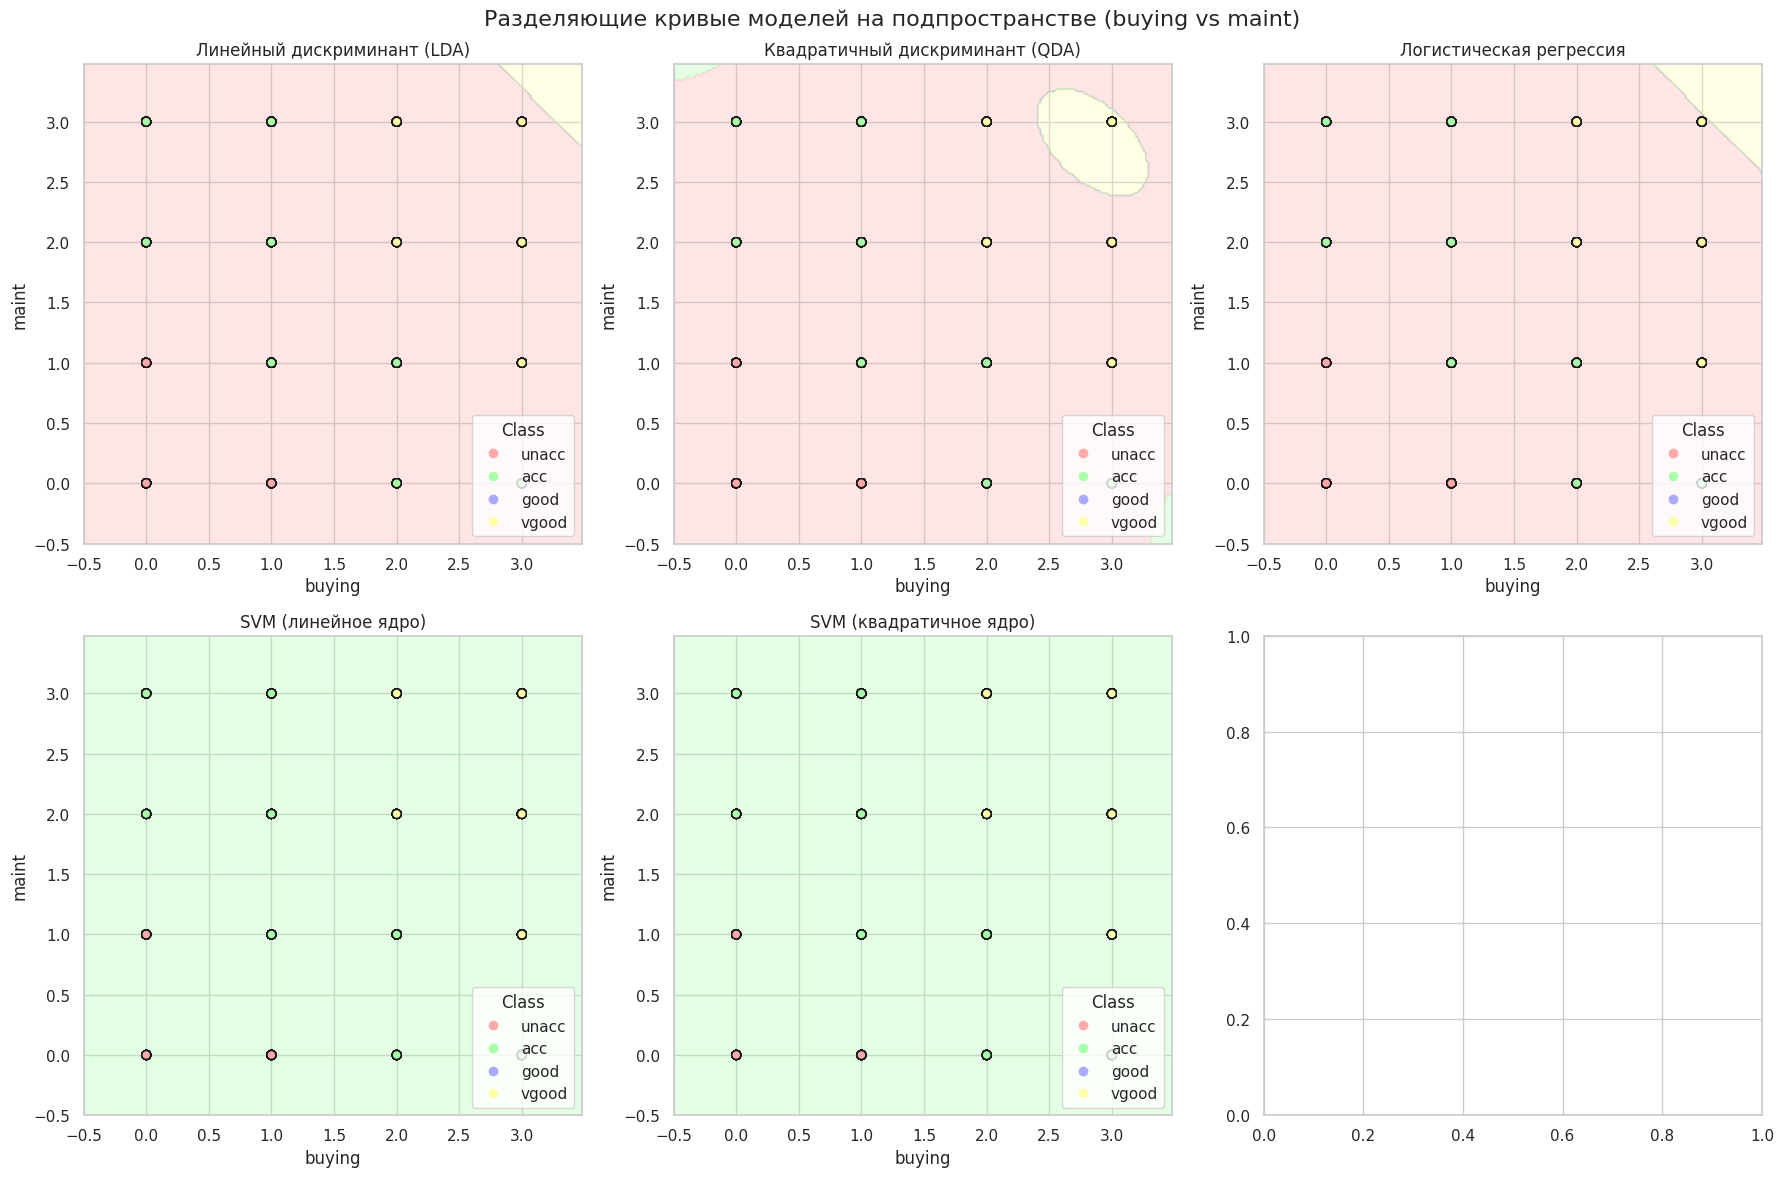

In [92]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_2[feat1_2].min() - 0.5, X_2d_2[feat1_2].max() + 0.5
y_min, y_max = X_2d_2[feat2_2].min() - 0.5, X_2d_2[feat2_2].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_2, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_2[feat1_2], X_2d_2[feat2_2], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_2)
        ax.set_ylabel(feat2_2)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs maint)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 3 (по признакам 'buying' и 'doors')

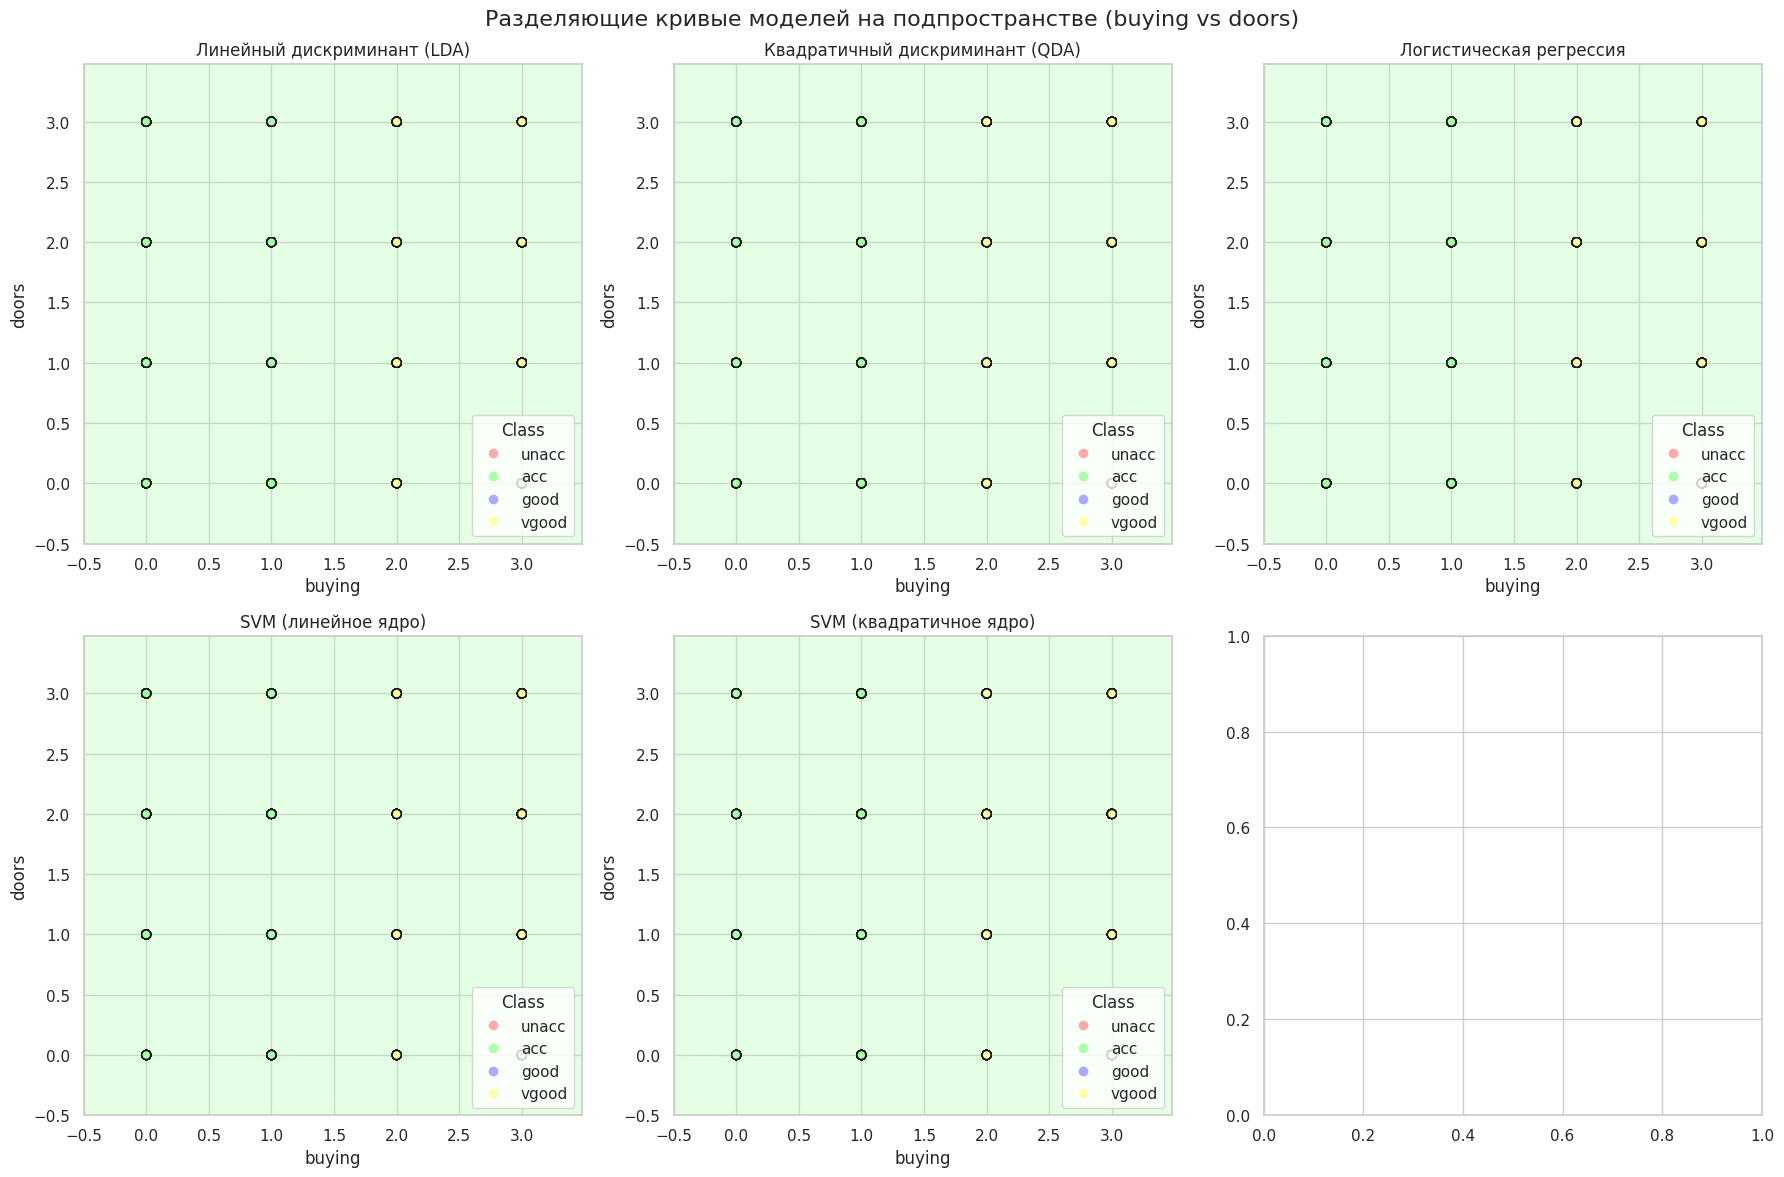

In [93]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_3[feat1_3].min() - 0.5, X_2d_3[feat1_3].max() + 0.5
y_min, y_max = X_2d_3[feat2_3].min() - 0.5, X_2d_3[feat2_3].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_3, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_3[feat1_3], X_2d_3[feat2_3], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_3)
        ax.set_ylabel(feat2_3)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_3)
        ax.set_ylabel(feat2_3)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs doors)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 4 (по признакам 'buying' и 'persons')

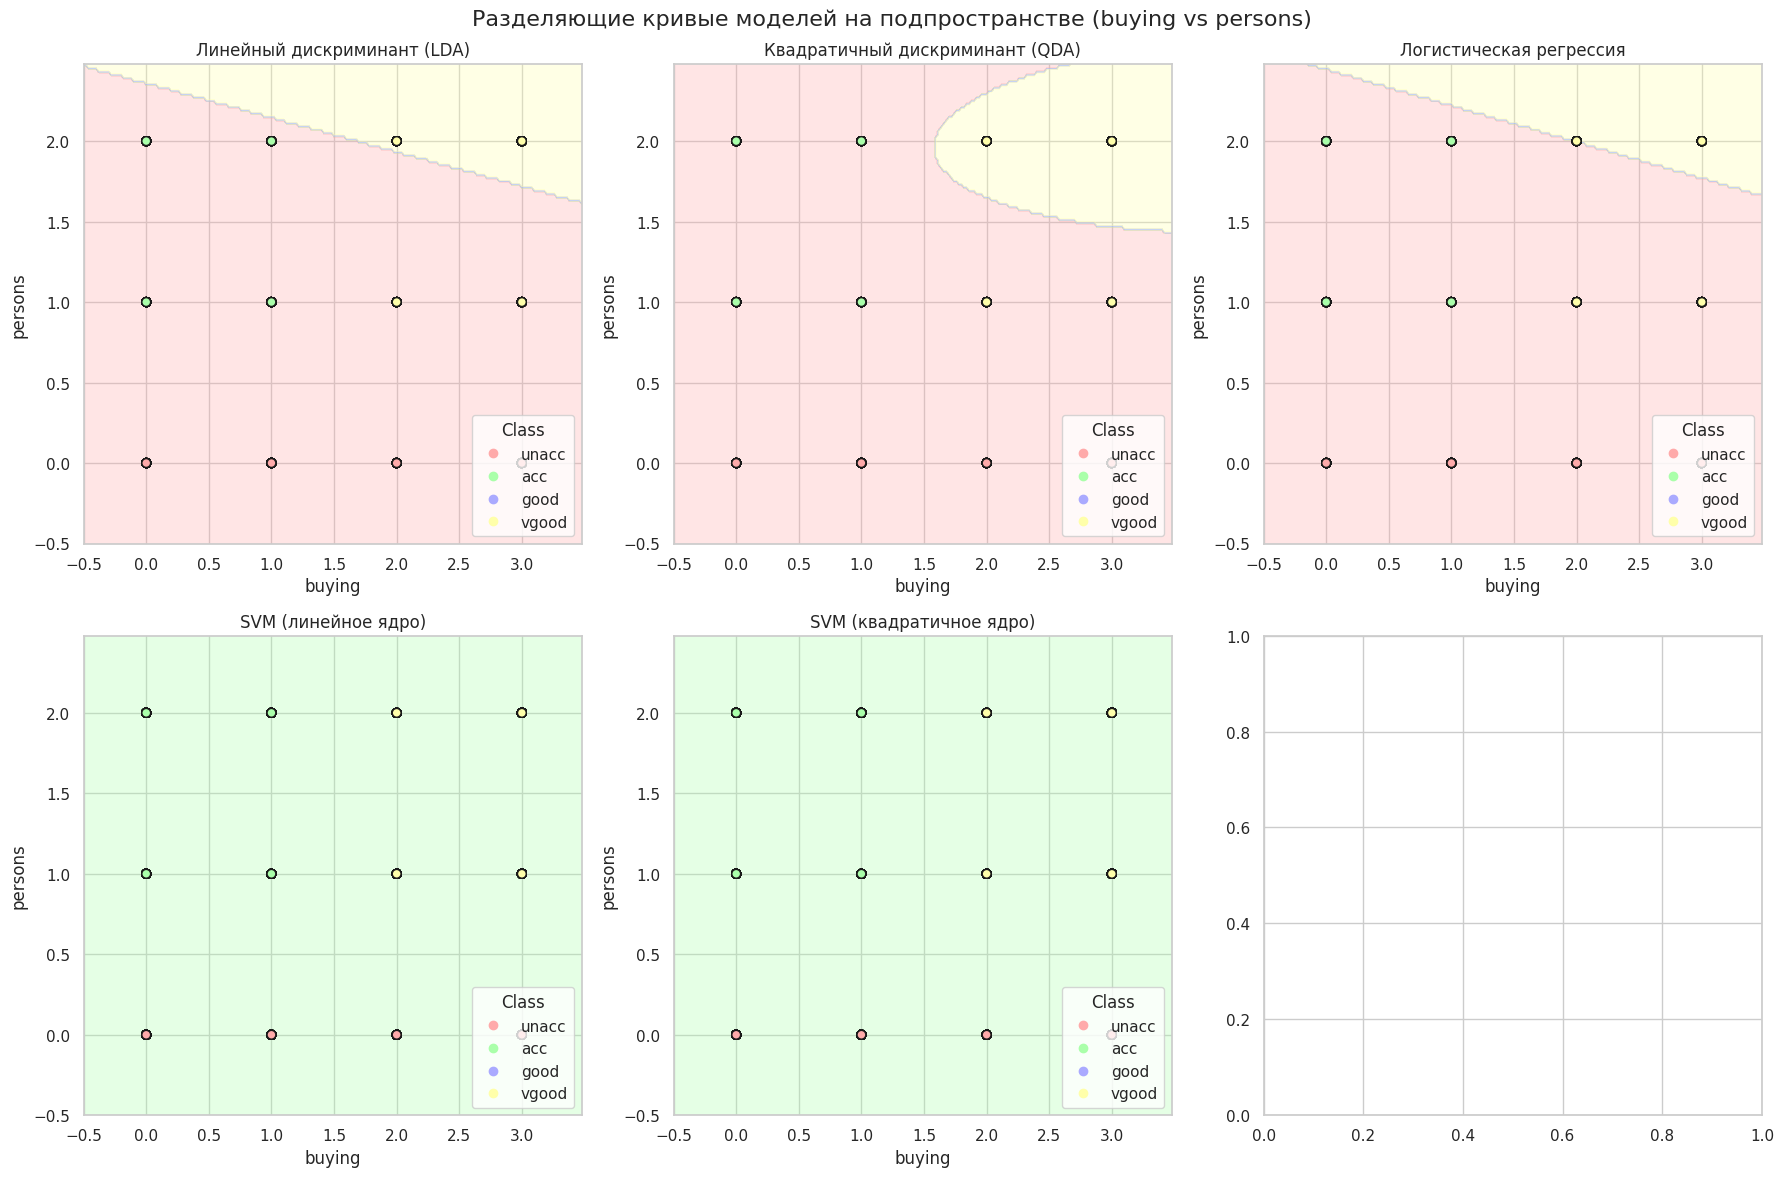

In [94]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_4[feat1_4].min() - 0.5, X_2d_4[feat1_4].max() + 0.5
y_min, y_max = X_2d_4[feat2_4].min() - 0.5, X_2d_4[feat2_4].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_4, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_4[feat1_4], X_2d_4[feat2_4], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_4)
        ax.set_ylabel(feat2_4)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_4)
        ax.set_ylabel(feat2_4)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 5 (по признакам 'buying' и 'lug_boot')

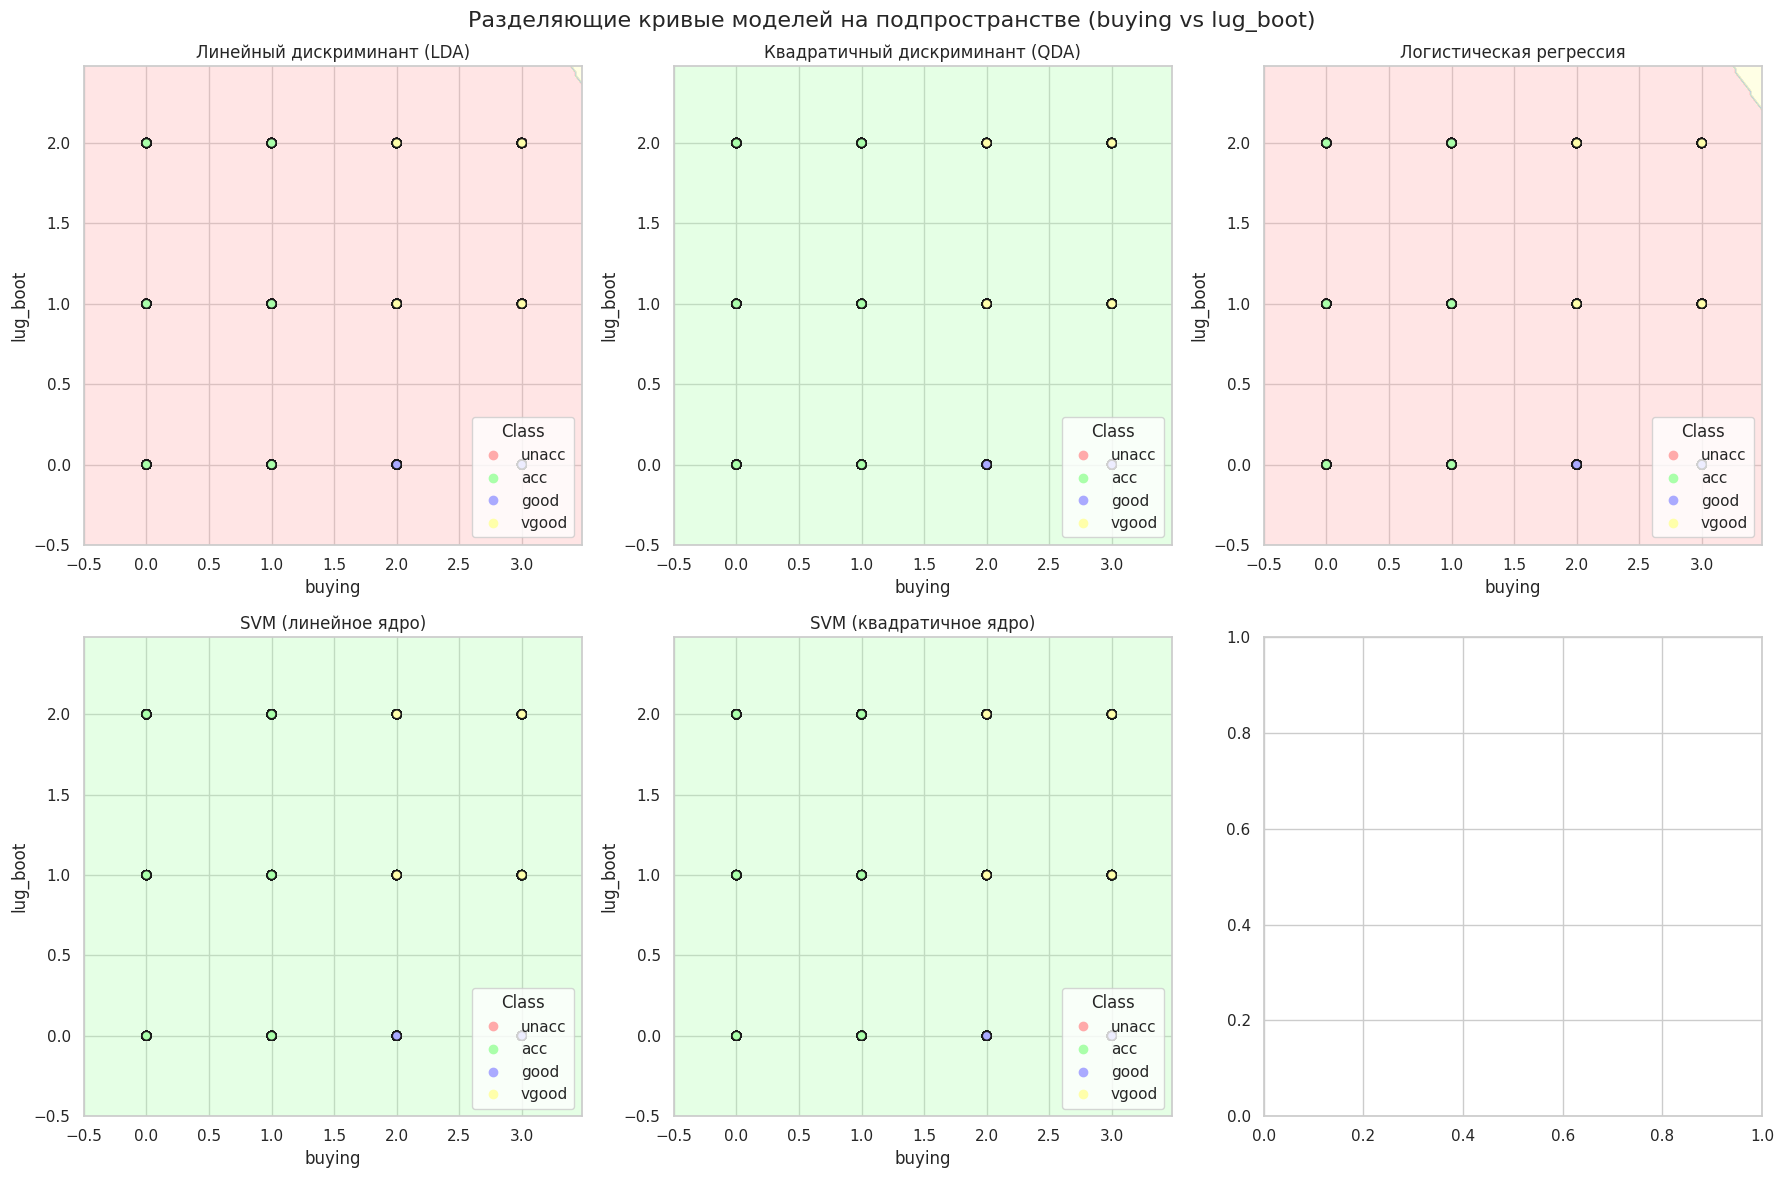

In [95]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_5[feat1_5].min() - 0.5, X_2d_5[feat1_5].max() + 0.5
y_min, y_max = X_2d_5[feat2_5].min() - 0.5, X_2d_5[feat2_5].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_5, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_5[feat1_5], X_2d_5[feat2_5], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_5)
        ax.set_ylabel(feat2_5)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_5)
        ax.set_ylabel(feat2_5)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 6 (по признакам 'buying' и 'safety')

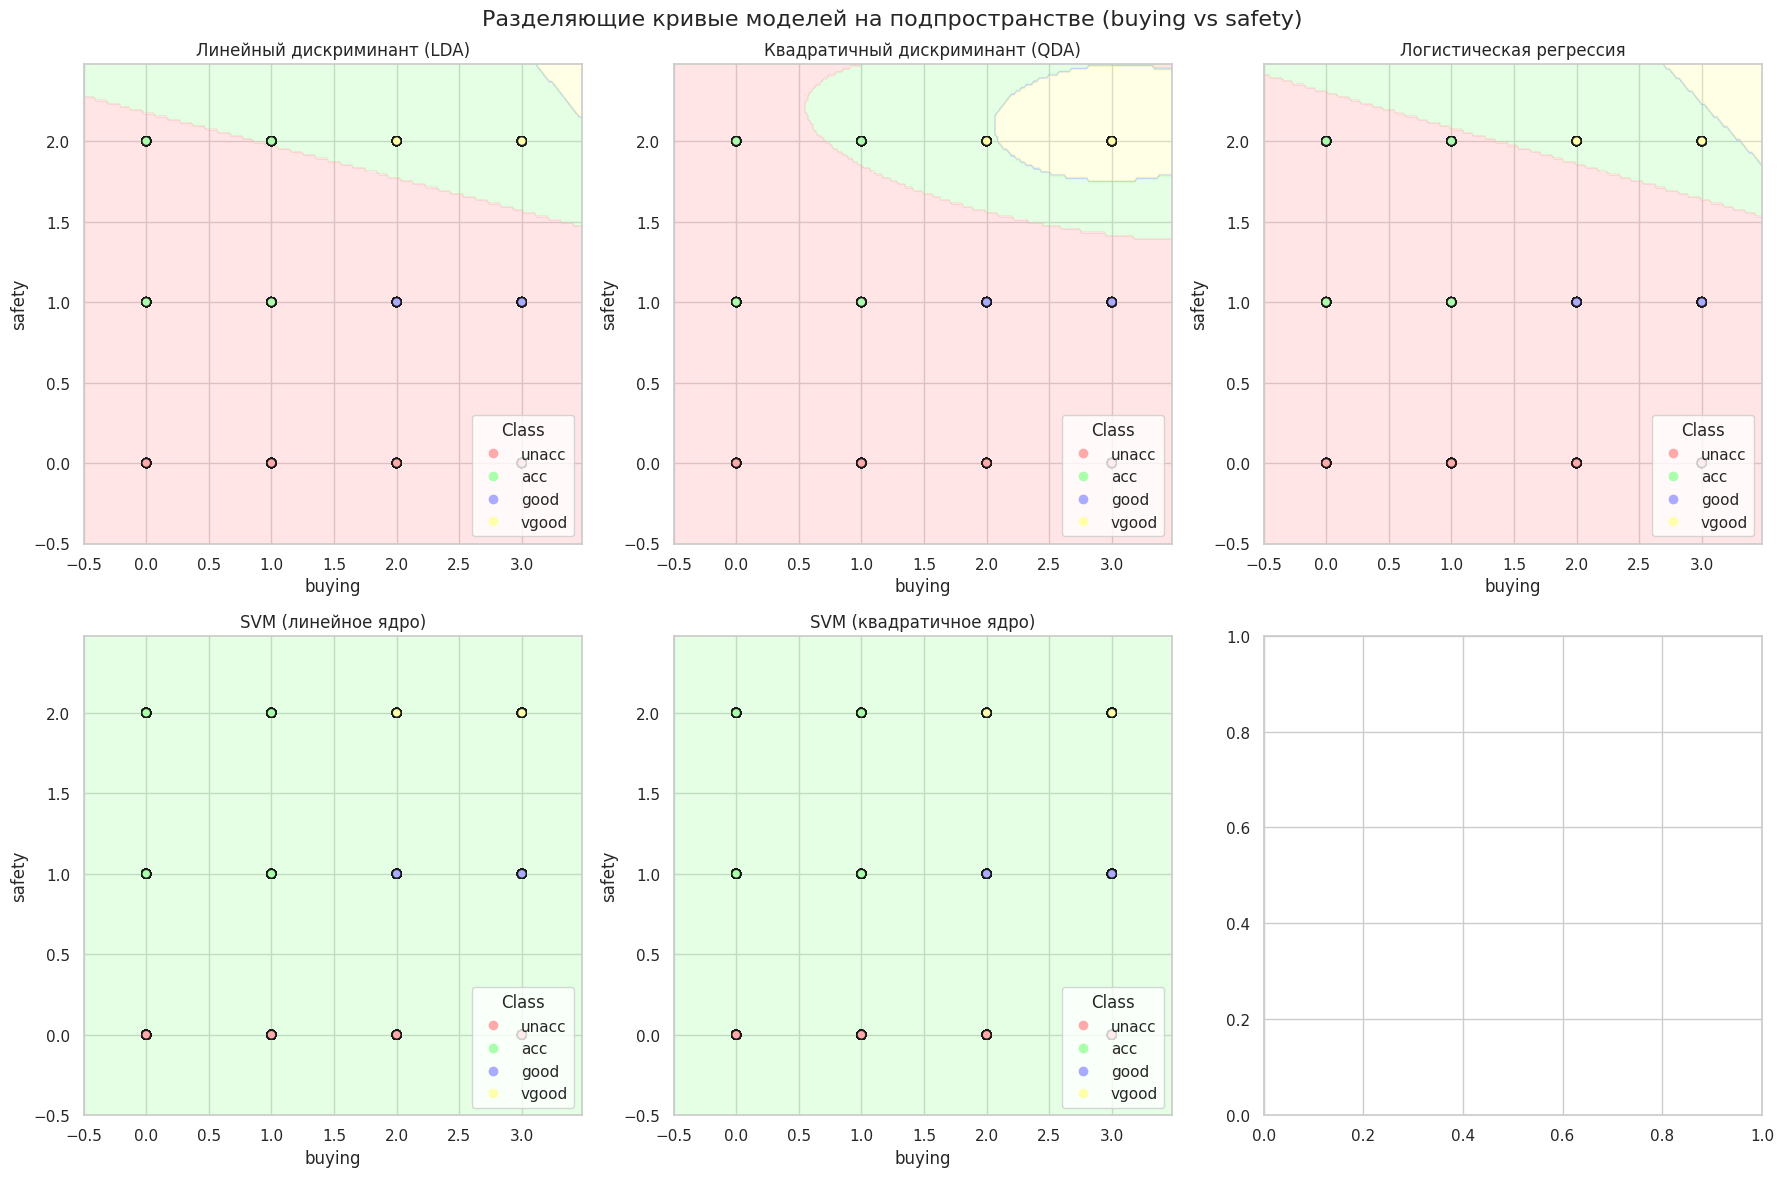

In [96]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_6[feat1_6].min() - 0.5, X_2d_6[feat1_6].max() + 0.5
y_min, y_max = X_2d_6[feat2_6].min() - 0.5, X_2d_6[feat2_6].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_6, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_6[feat1_6], X_2d_6[feat2_6], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_6)
        ax.set_ylabel(feat2_6)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_6)
        ax.set_ylabel(feat2_6)

plt.suptitle("Разделяющие кривые моделей на подпространстве (buying vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 7 (по признакам 'maint' и 'doors')

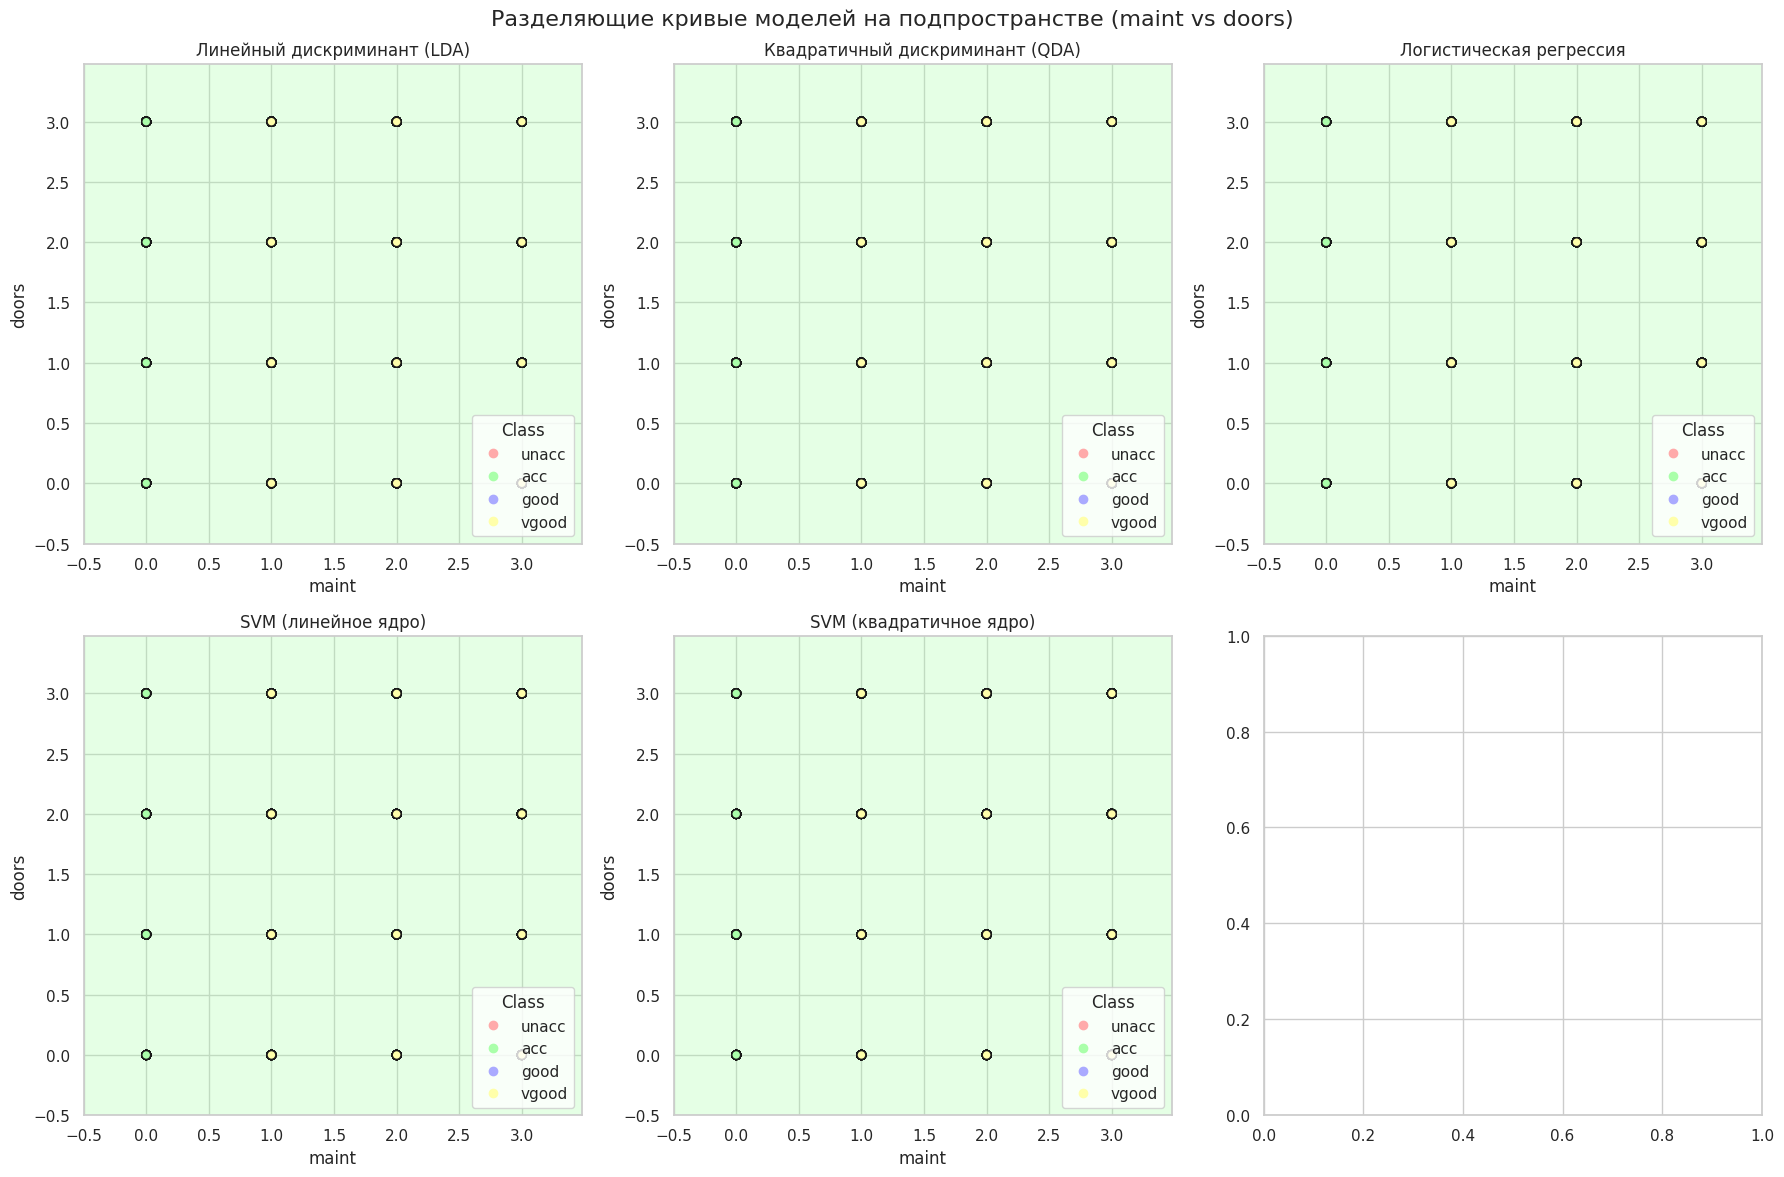

In [97]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_7[feat1_7].min() - 0.5, X_2d_7[feat1_7].max() + 0.5
y_min, y_max = X_2d_7[feat2_7].min() - 0.5, X_2d_7[feat2_7].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_7, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_7[feat1_7], X_2d_7[feat2_7], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_7)
        ax.set_ylabel(feat2_7)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_7)
        ax.set_ylabel(feat2_7)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs doors)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 8 (по признакам 'maint' и 'persons')

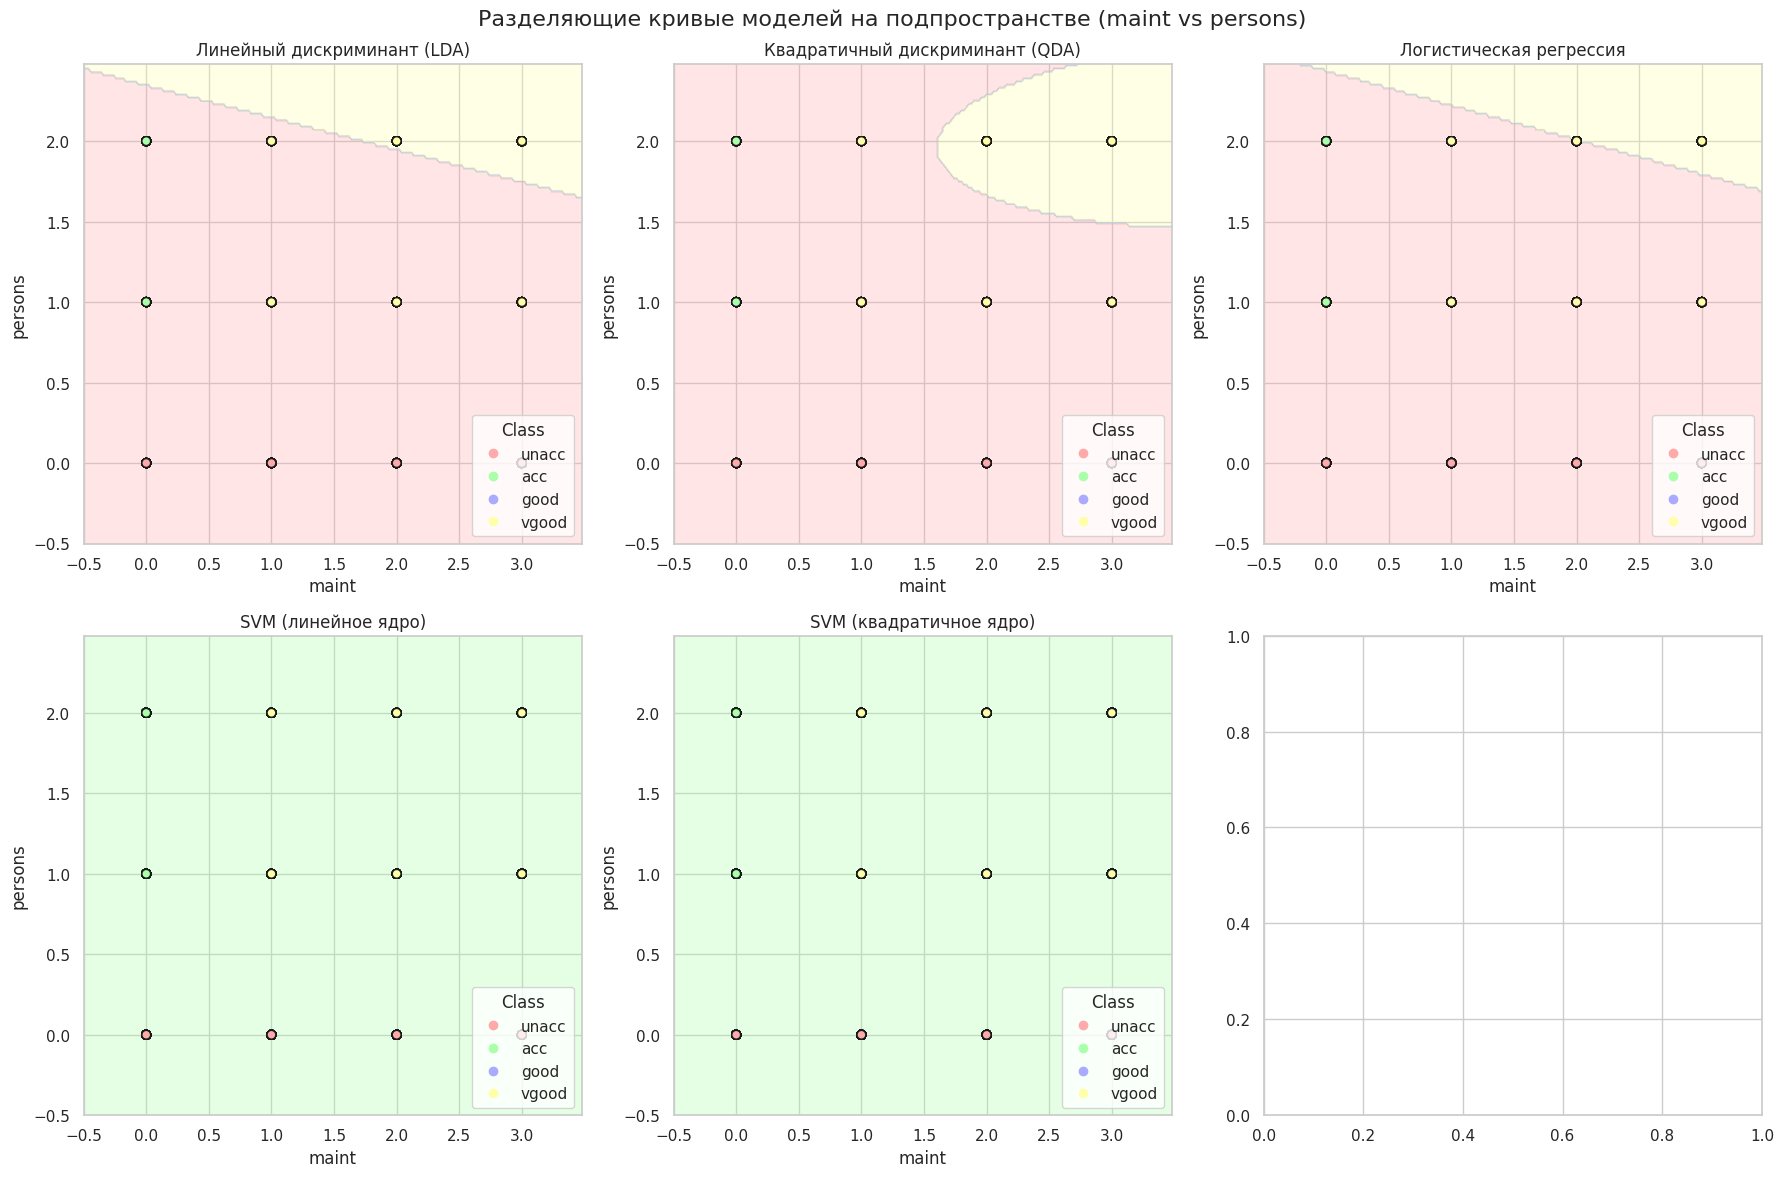

In [98]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_8[feat1_8].min() - 0.5, X_2d_8[feat1_8].max() + 0.5
y_min, y_max = X_2d_8[feat2_8].min() - 0.5, X_2d_8[feat2_8].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_8, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_8[feat1_8], X_2d_8[feat2_8], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_8)
        ax.set_ylabel(feat2_8)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_8)
        ax.set_ylabel(feat2_8)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 9 (по признакам 'maint' и 'lug_boot')

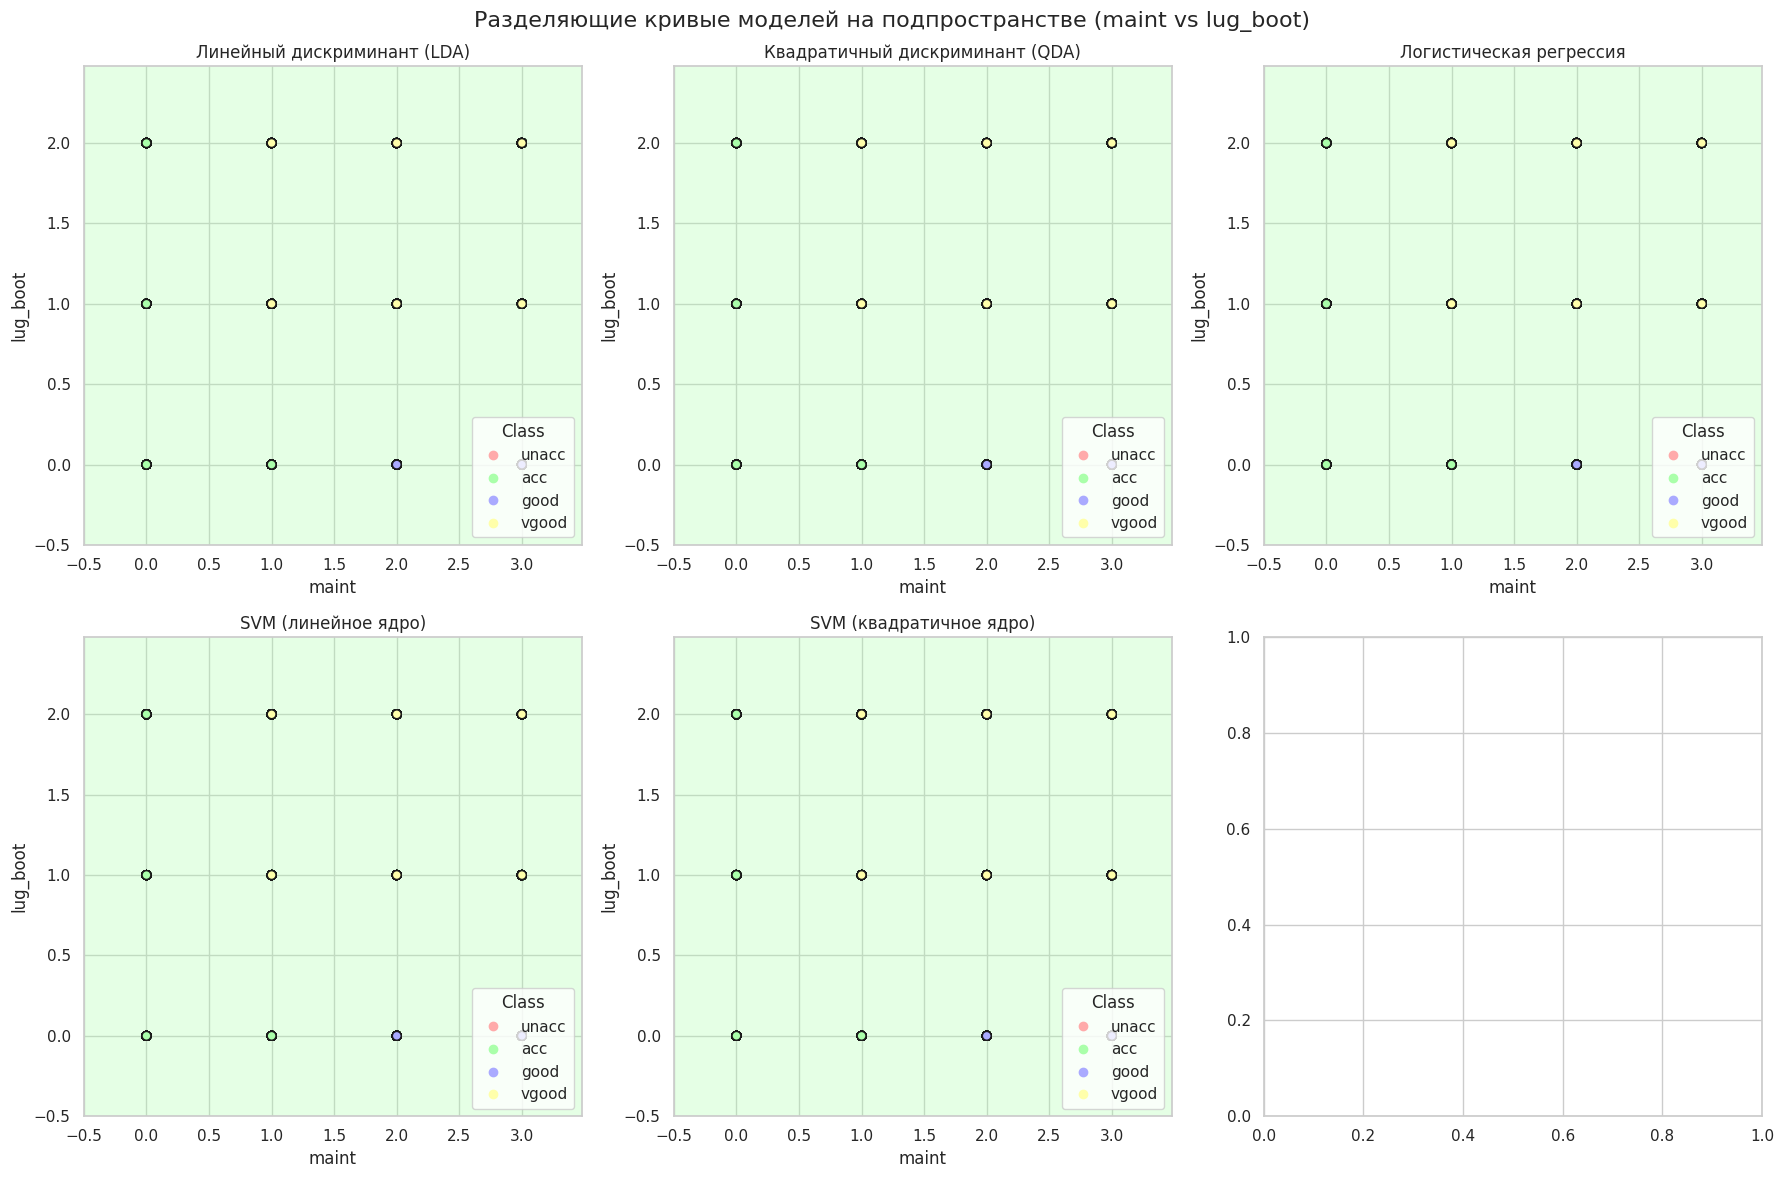

In [99]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_9[feat1_9].min() - 0.5, X_2d_9[feat1_9].max() + 0.5
y_min, y_max = X_2d_9[feat2_9].min() - 0.5, X_2d_9[feat2_9].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_9, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_9[feat1_9], X_2d_9[feat2_9], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_9)
        ax.set_ylabel(feat2_9)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_9)
        ax.set_ylabel(feat2_9)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 10 (по признакам 'maint' и 'safety')

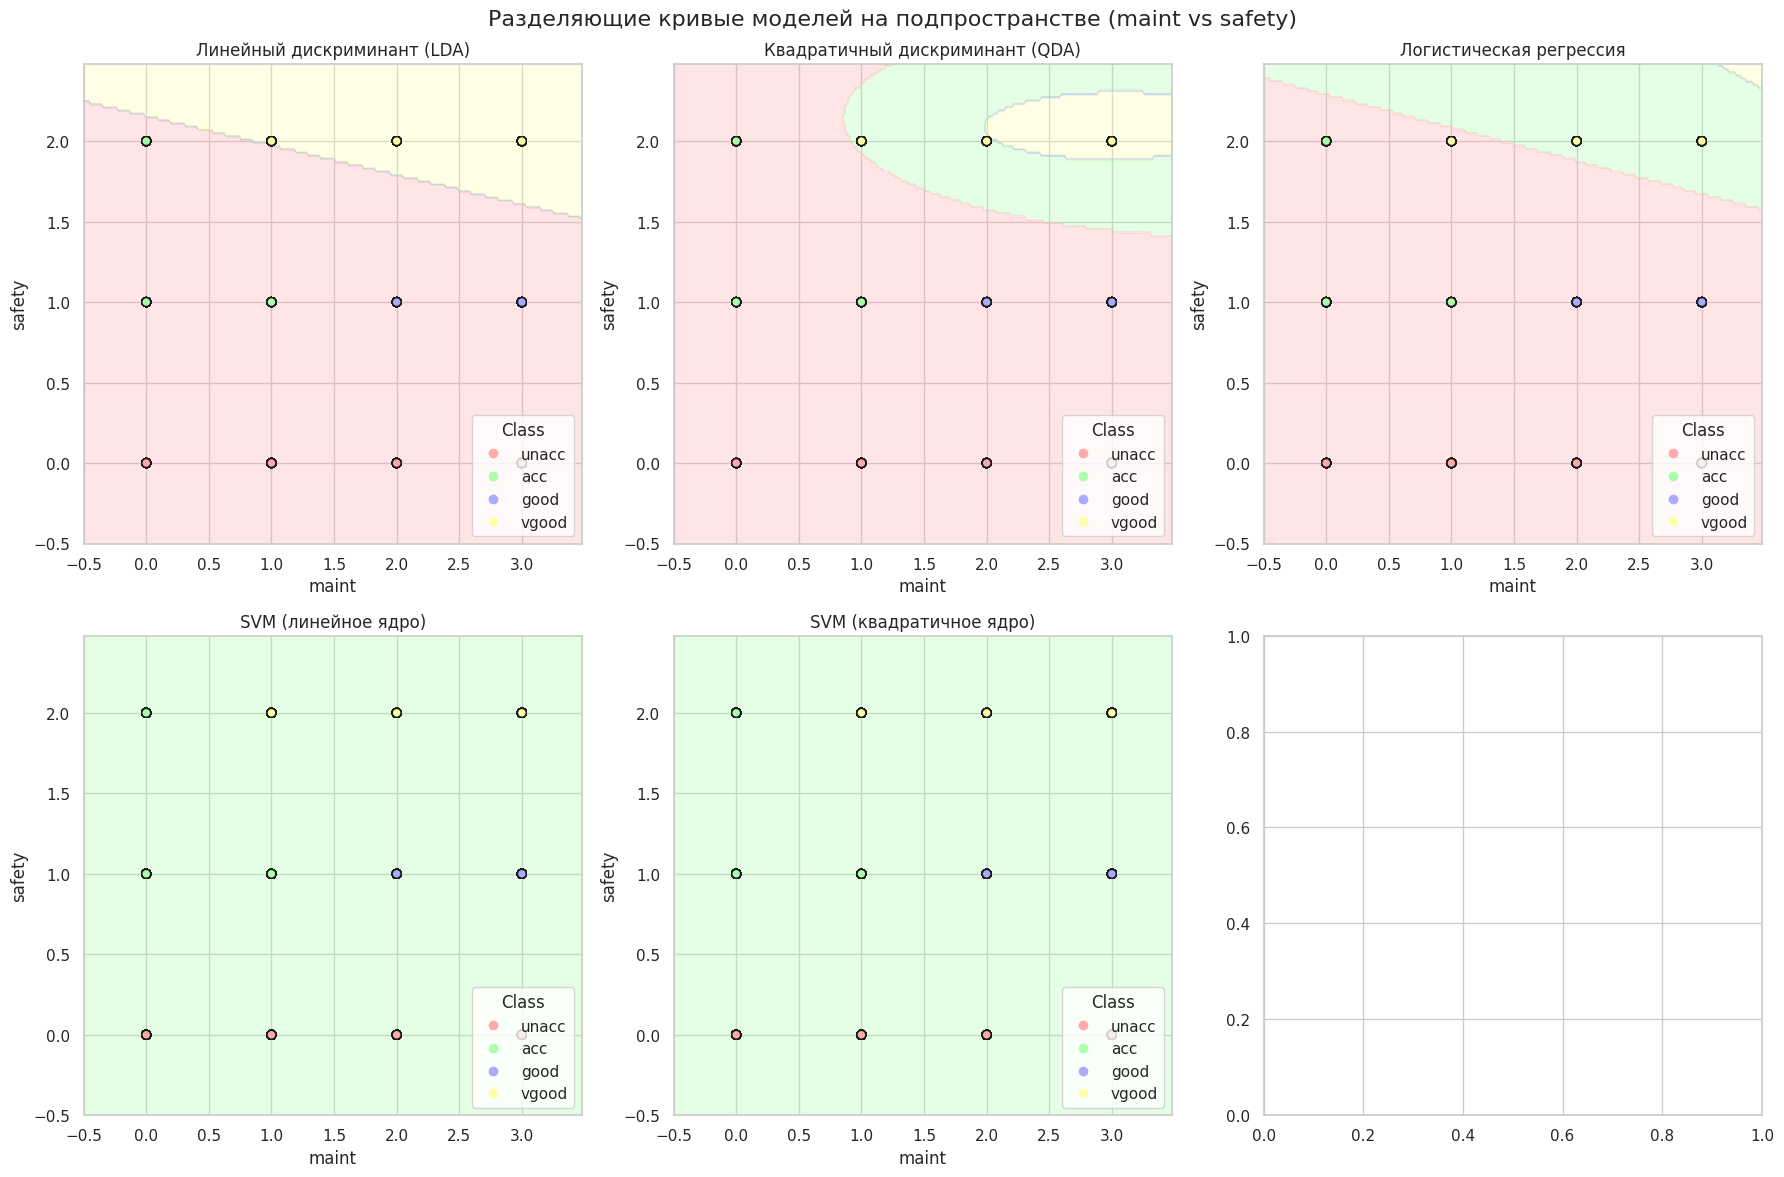

In [100]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_10[feat1_10].min() - 0.5, X_2d_10[feat1_10].max() + 0.5
y_min, y_max = X_2d_10[feat2_10].min() - 0.5, X_2d_10[feat2_10].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_10, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_10[feat1_10], X_2d_10[feat2_10], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_10)
        ax.set_ylabel(feat2_10)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_10)
        ax.set_ylabel(feat2_10)

plt.suptitle("Разделяющие кривые моделей на подпространстве (maint vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 11 (по признакам 'doors' и 'persons')

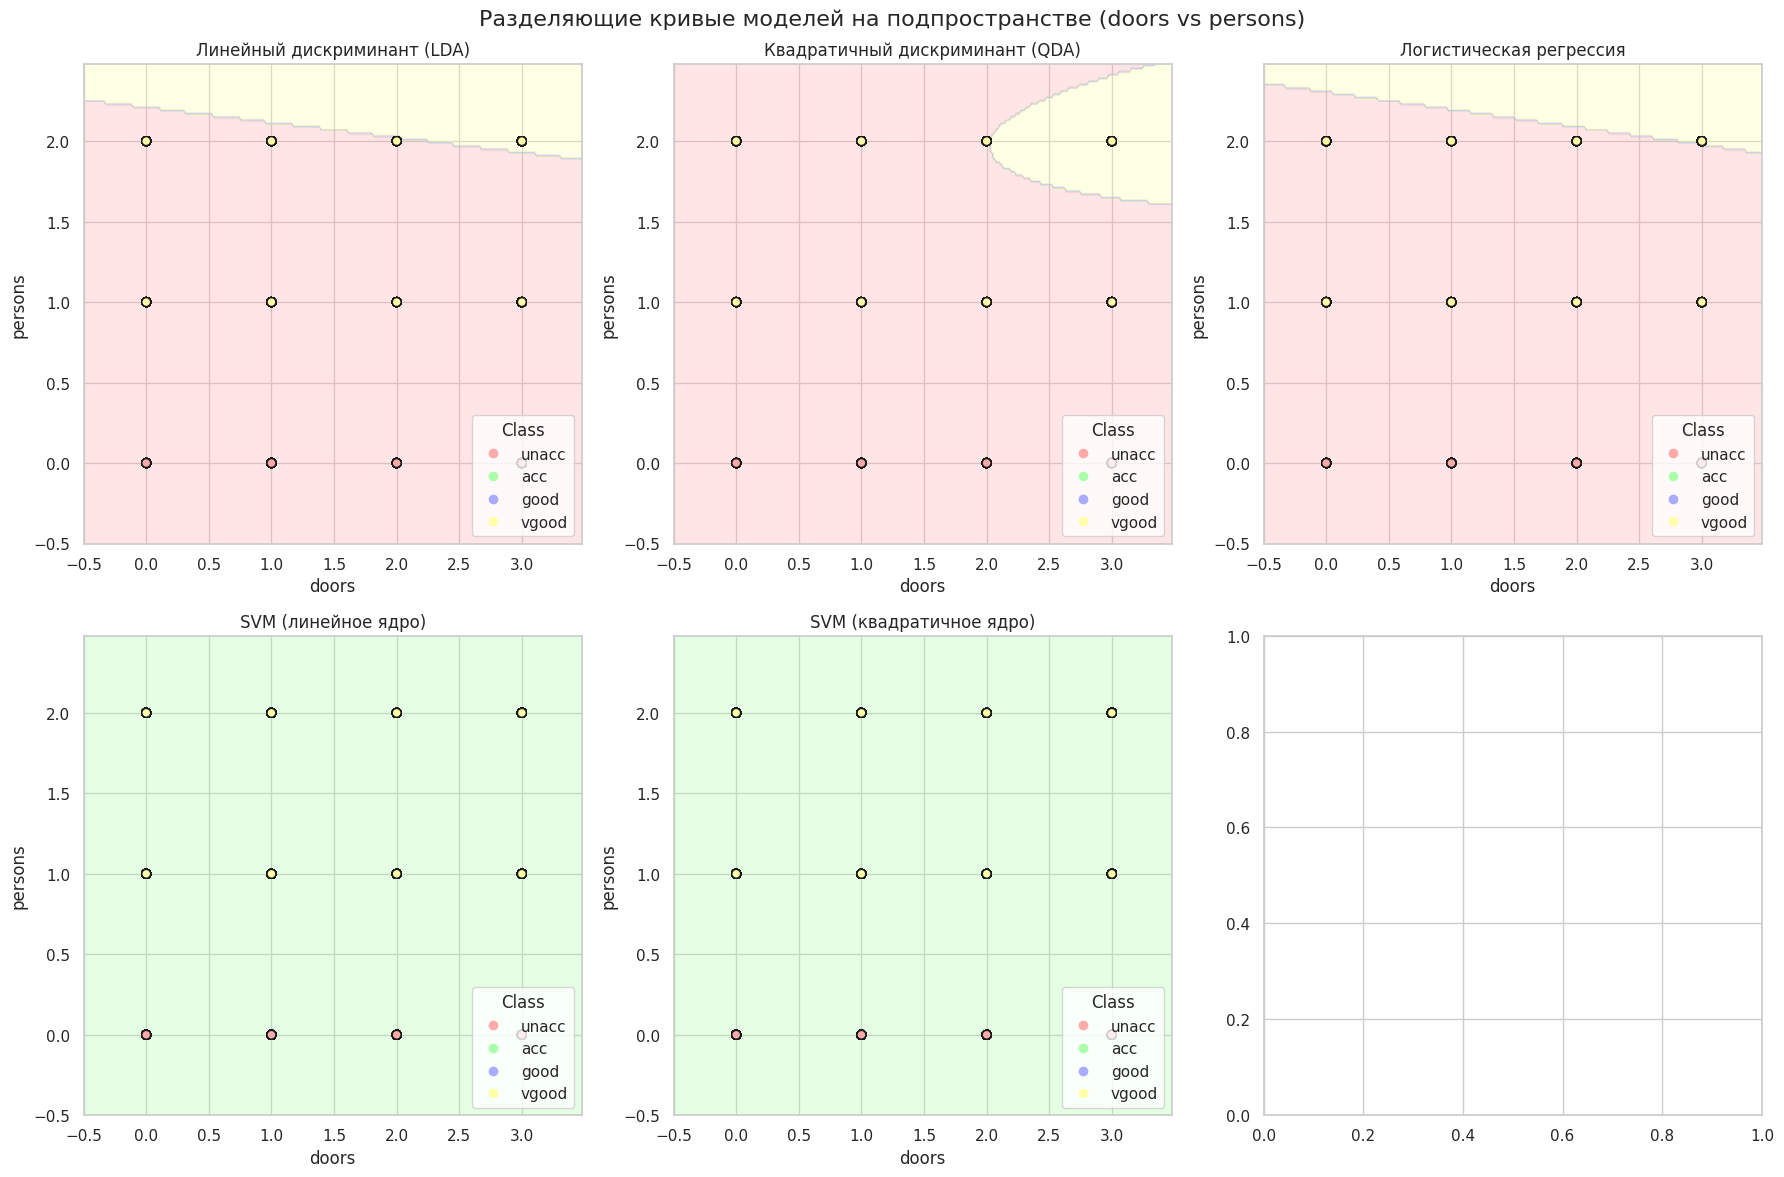

In [101]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_11[feat1_11].min() - 0.5, X_2d_11[feat1_11].max() + 0.5
y_min, y_max = X_2d_11[feat2_11].min() - 0.5, X_2d_11[feat2_11].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_11, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_11[feat1_11], X_2d_11[feat2_11], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_11)
        ax.set_ylabel(feat2_11)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_11)
        ax.set_ylabel(feat2_11)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs persons)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 12 (по признакам 'doors' и 'lug_boot')

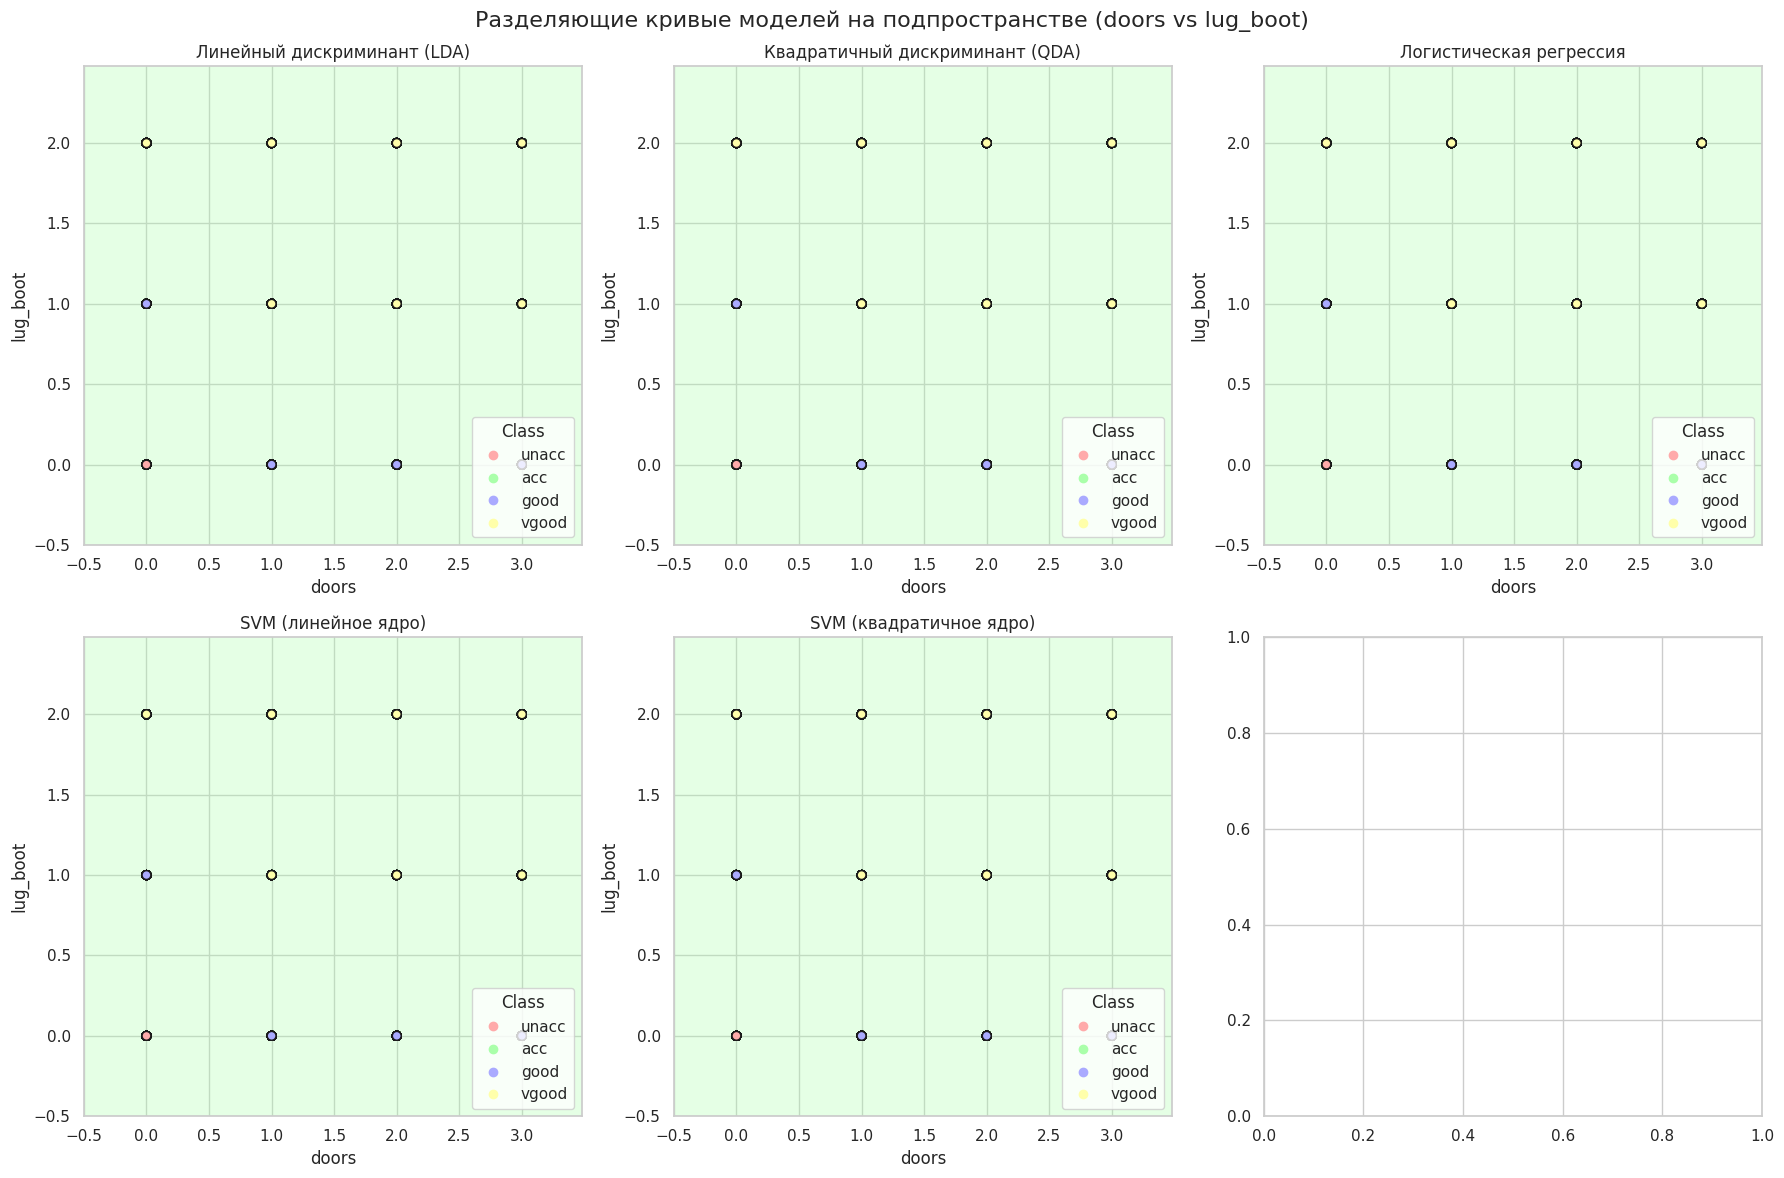

In [102]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_12[feat1_12].min() - 0.5, X_2d_12[feat1_12].max() + 0.5
y_min, y_max = X_2d_12[feat2_12].min() - 0.5, X_2d_12[feat2_12].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_12, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_12[feat1_12], X_2d_12[feat2_12], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_12)
        ax.set_ylabel(feat2_12)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_12)
        ax.set_ylabel(feat2_12)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 13 (по признакам 'doors' и 'safety')

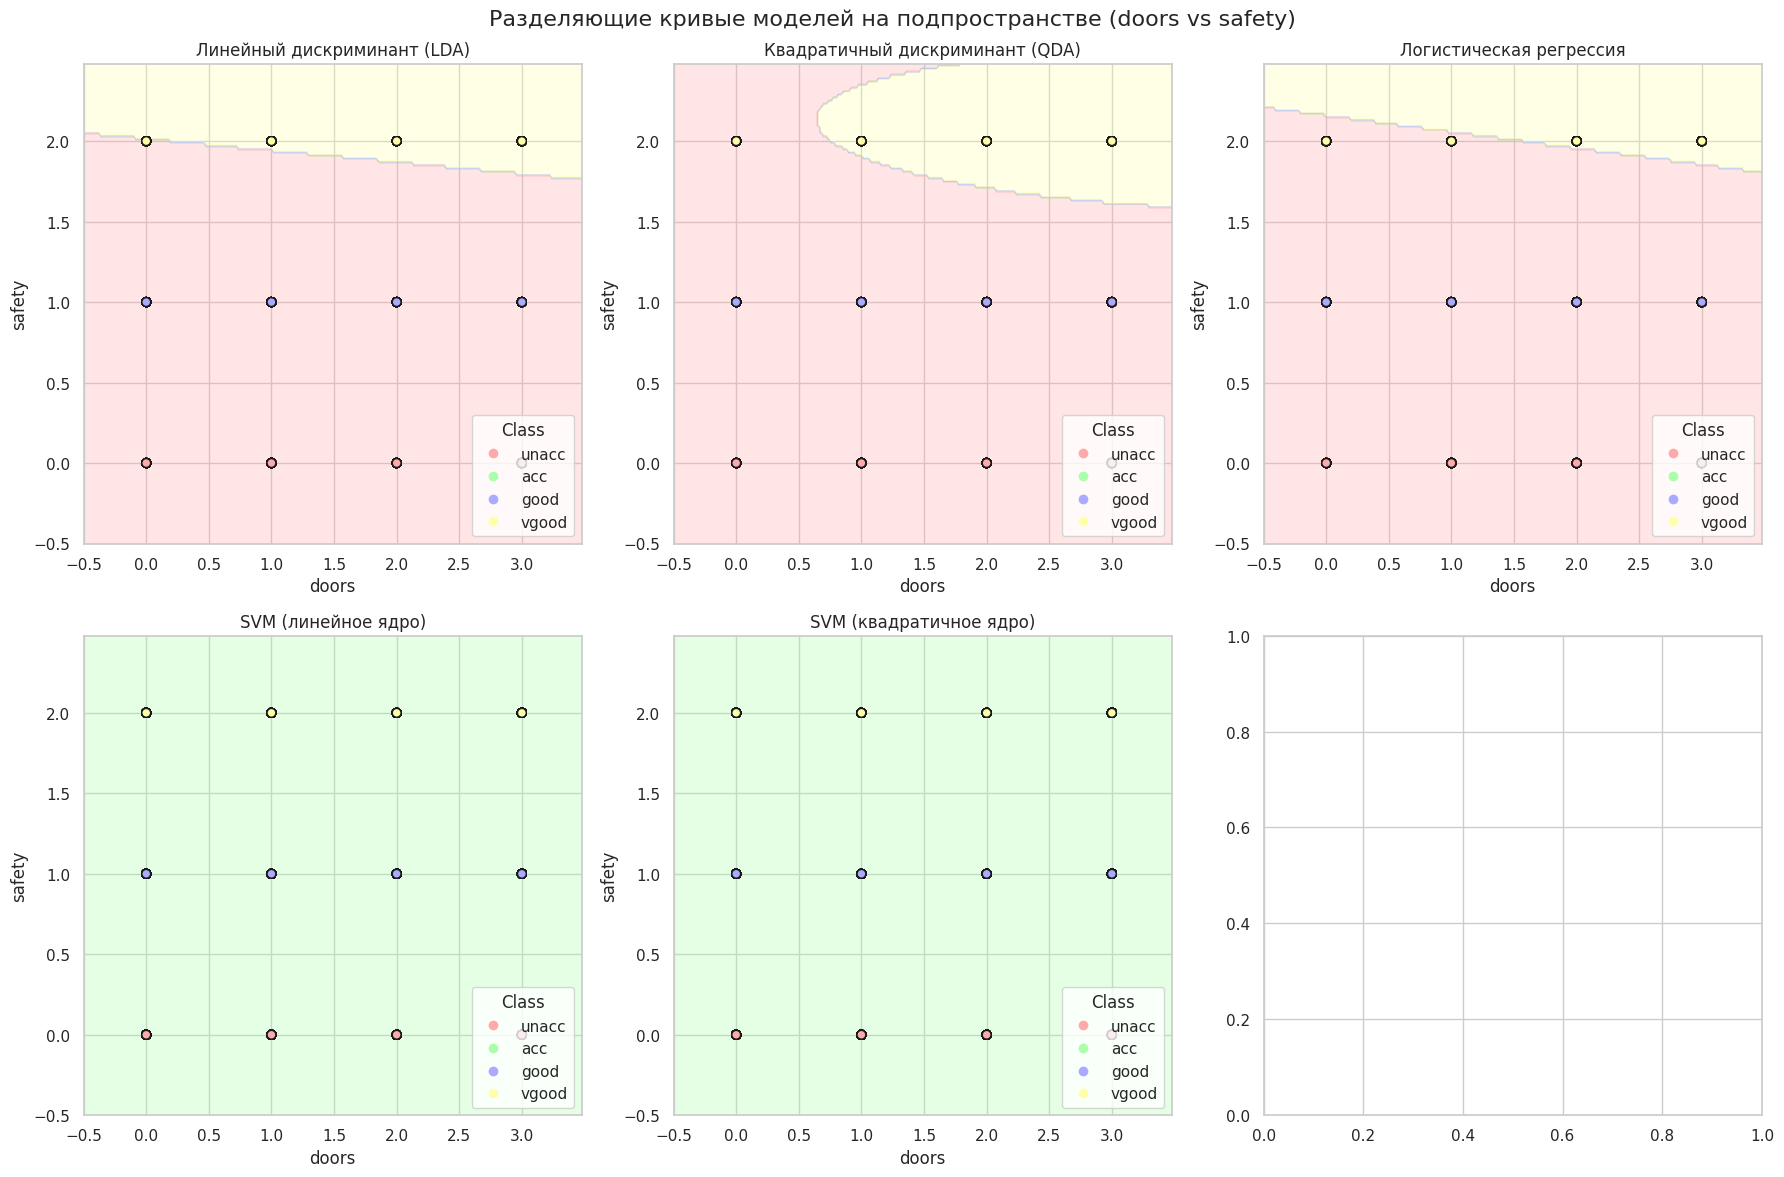

In [103]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_13[feat1_13].min() - 0.5, X_2d_13[feat1_13].max() + 0.5
y_min, y_max = X_2d_13[feat2_13].min() - 0.5, X_2d_13[feat2_13].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_13, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_13[feat1_13], X_2d_13[feat2_13], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_13)
        ax.set_ylabel(feat2_13)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_13)
        ax.set_ylabel(feat2_13)

plt.suptitle("Разделяющие кривые моделей на подпространстве (doors vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 14 (по признакам 'persons' и 'lug_boot')

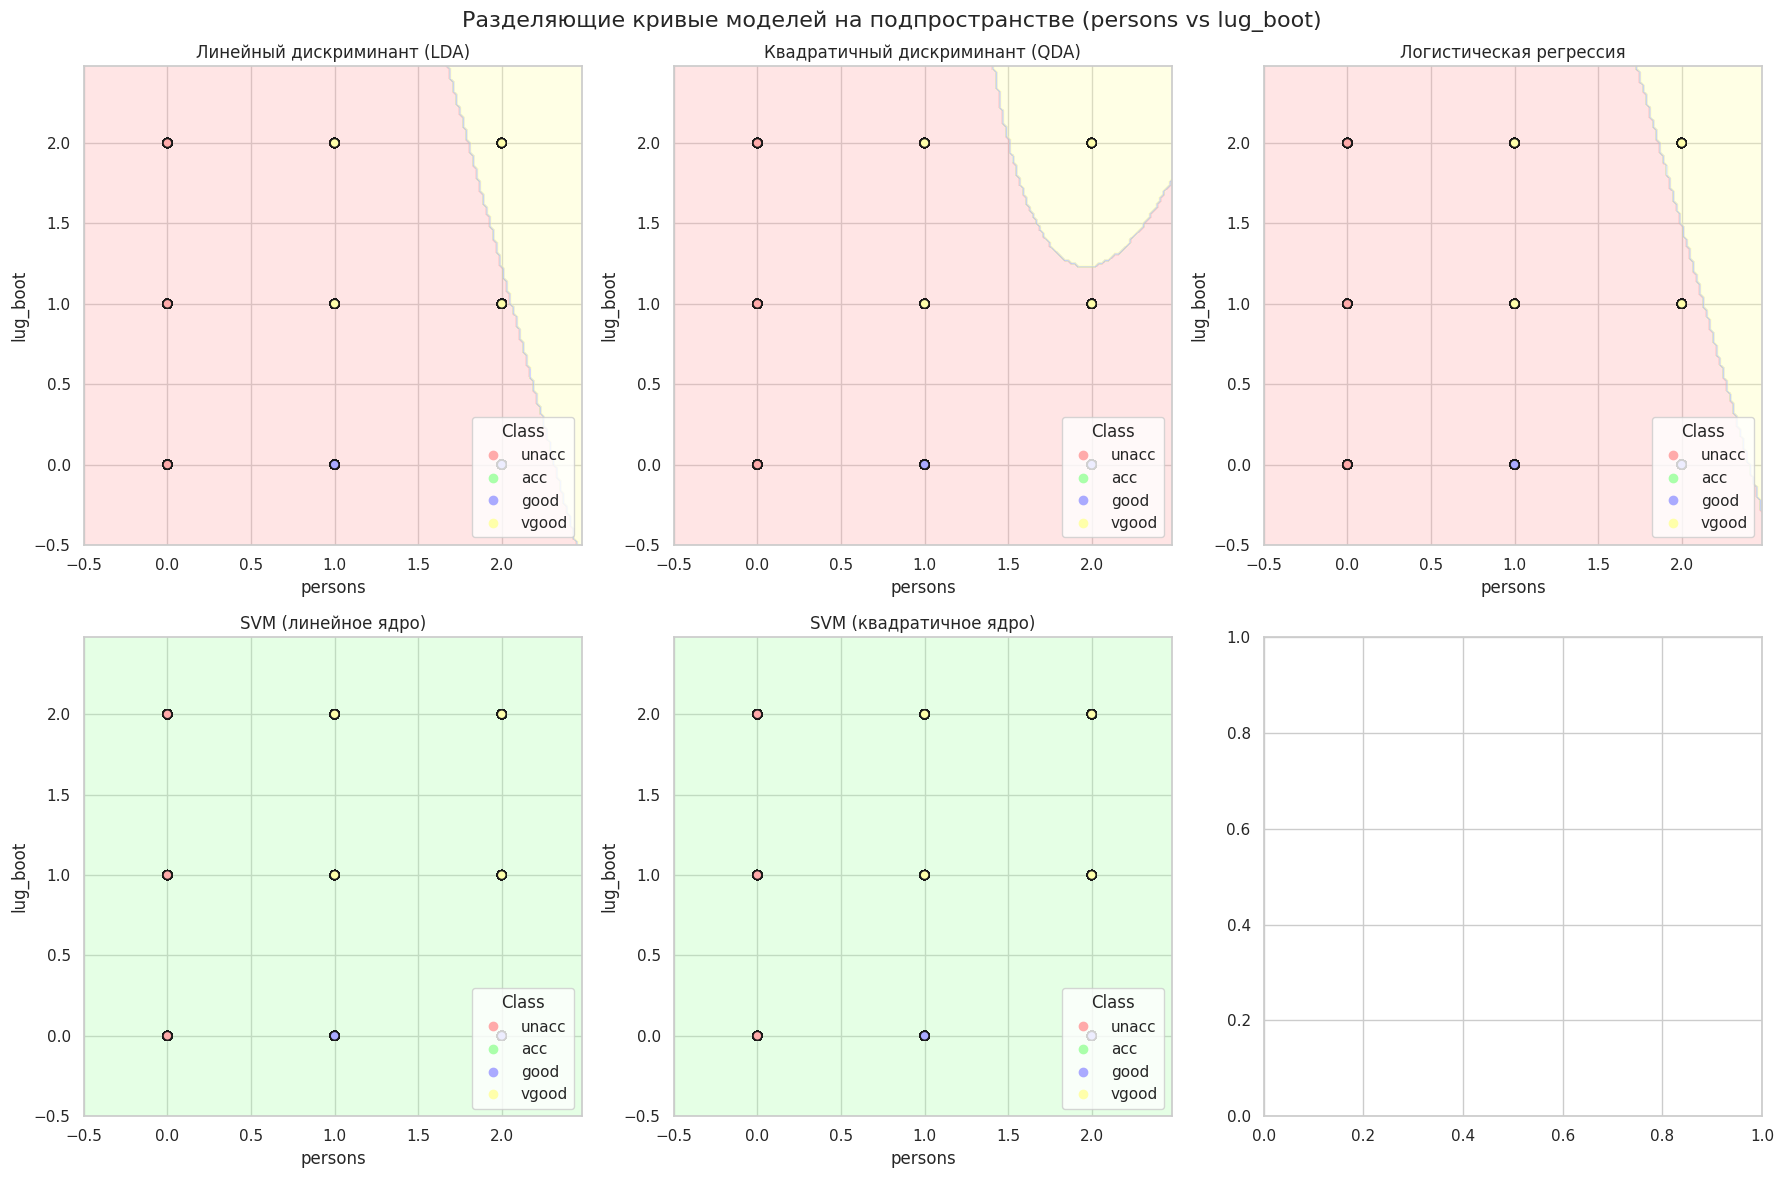

In [104]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_14[feat1_14].min() - 0.5, X_2d_14[feat1_14].max() + 0.5
y_min, y_max = X_2d_14[feat2_14].min() - 0.5, X_2d_14[feat2_14].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_14, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_14[feat1_14], X_2d_14[feat2_14], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_14)
        ax.set_ylabel(feat2_14)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_14)
        ax.set_ylabel(feat2_14)

plt.suptitle("Разделяющие кривые моделей на подпространстве (persons vs lug_boot)", fontsize=16)
plt.tight_layout()
plt.show()

### Сравнение 15 (по признакам 'lug_boot' и 'safety')

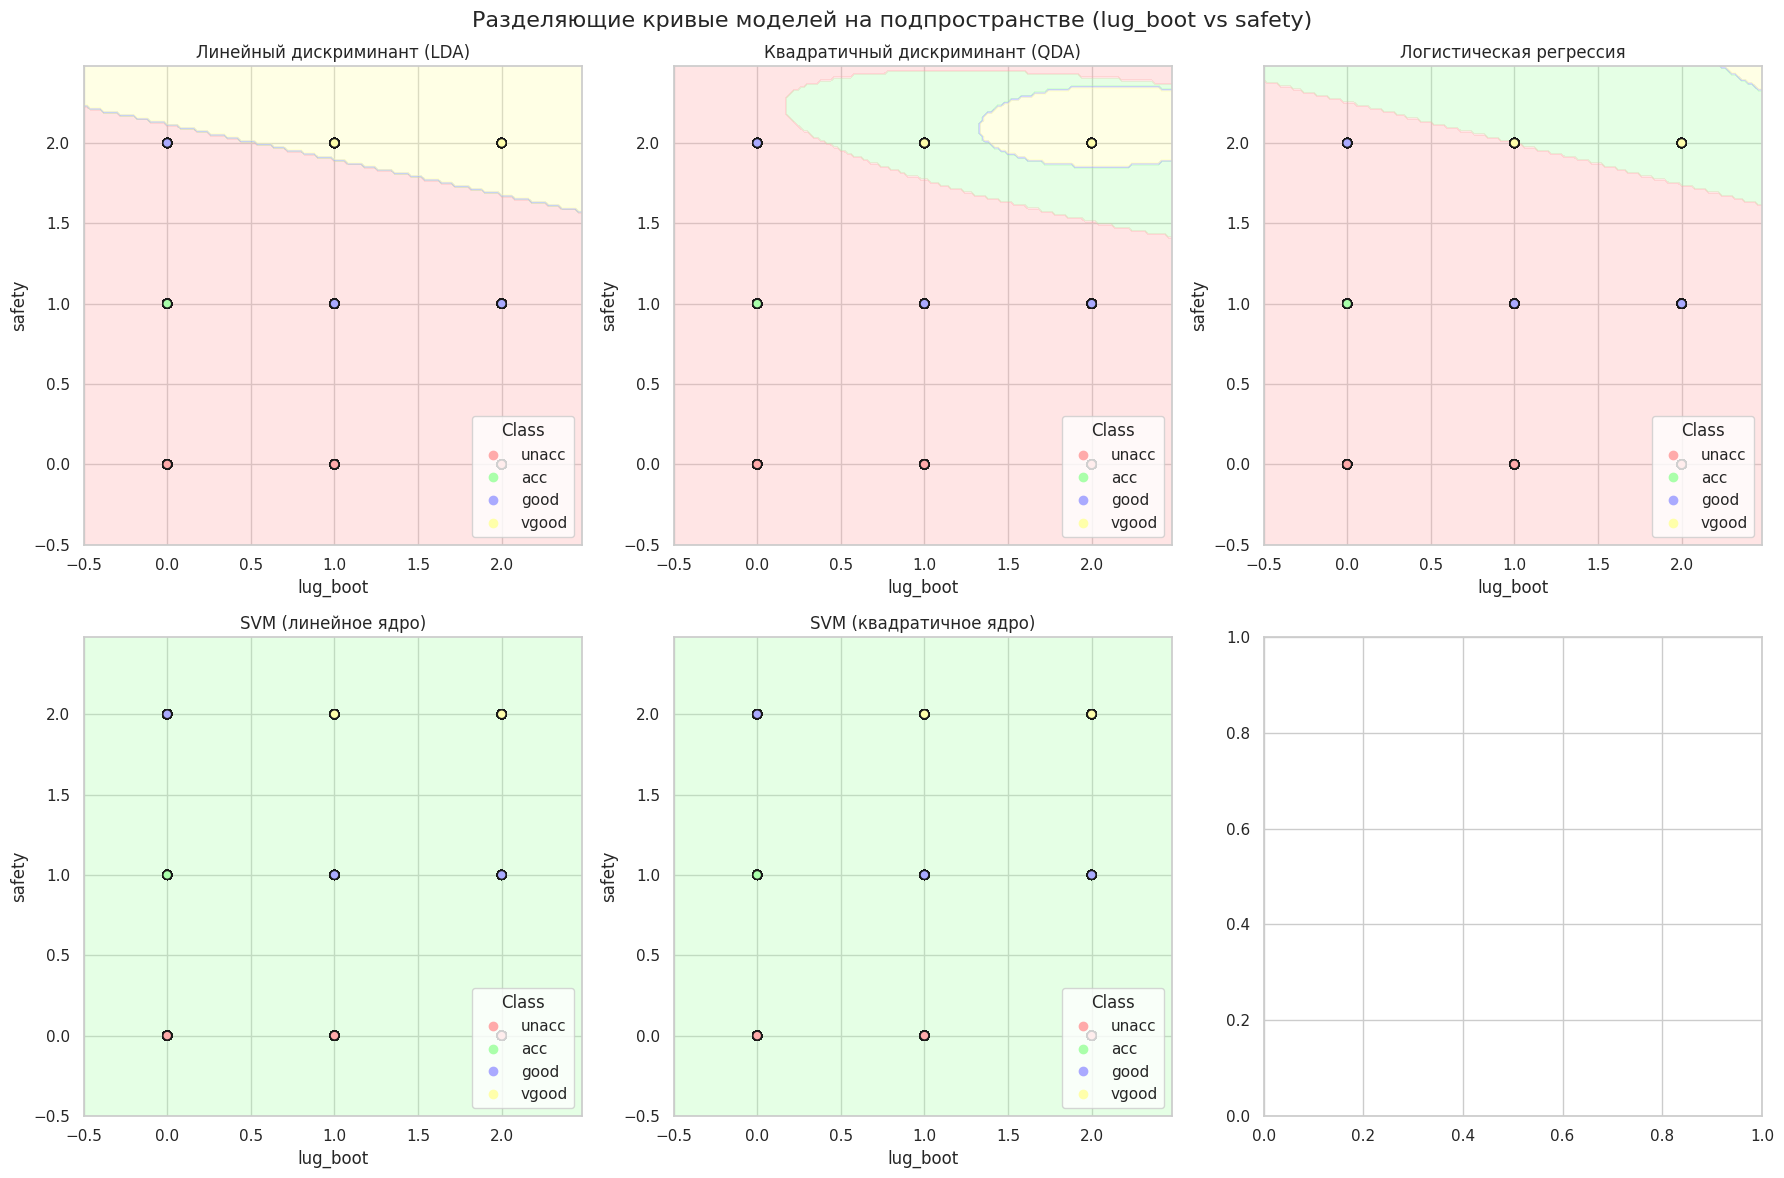

In [105]:
h: float = 0.02  # шаг сетки
x_min, x_max = X_2d_15[feat1_15].min() - 0.5, X_2d_15[feat1_15].max() + 0.5
y_min, y_max = X_2d_15[feat2_15].min() - 0.5, X_2d_15[feat2_15].max() + 0.5
xx, yy = np.meshgrid(np.arange(x_min, x_max, h), np.arange(y_min, y_max, h))

fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()
cmap_bold: ListedColormap = ListedColormap(['#FFAAAA', '#AAFFAA', '#AAAAFF', '#FFFFAA'])

for i, (name, model) in enumerate(models_optimized.items()):
    ax = axes[i]

    try:
        model.fit(X_2d_15, y)
        
        # Предсказание на сетке для границы решений
        Z = model.predict(np.c_[xx.ravel(), yy.ravel()])
        Z = Z.reshape(xx.shape)
        
        ax.contourf(xx, yy, Z, alpha=0.3, cmap=cmap_bold)
        
        # Точки исходных данных
        scatter = ax.scatter(X_2d_15[feat1_15], X_2d_15[feat2_15], c=y, cmap=cmap_bold, edgecolor='k', s=40)
        ax.set_xlabel(feat1_15)
        ax.set_ylabel(feat2_15)
        ax.set_title(name)
        
        # Добавим легенду с названиями классов
        handles, _ = scatter.legend_elements()
        ax.legend(handles, ['unacc', 'acc', 'good', 'vgood'], title="Class", loc='lower right')
    except Exception as e:
        ax.text(0.5, 0.5, f"Ошибка обучения:\n{str(e)}", 
                ha='center', va='center', fontsize=10, 
                transform=ax.transAxes, color='red')
        ax.set_title(name)
        ax.set_xlabel(feat1_15)
        ax.set_ylabel(feat2_15)

plt.suptitle("Разделяющие кривые моделей на подпространстве (lug_boot vs safety)", fontsize=16)
plt.tight_layout()
plt.show()

## 4. Глубокий анализ качества моделей
- **Матрицы ошибок** показывают, что линейные модели (LDA, Logistic) склонны путать классы `good` и `vgood` с классом `acc` из-за несбалансированности данных (всего 69 и 65 объектов соответственно). 
- **SVM с полиномиальным ядром** после оптимизации решил эту проблему, показав F1-score > 0.97 для всех классов.
- **Кривые обучения** подтверждают отсутствие переобучения (gap между train и validation кривыми минимален), что говорит о хорошей обобщающей способности настроенных моделей.

## Оценка качества (Cross-Validation)

## Вариант 1: Проведём кросс-валидацию для всех X_2d_1, ..., X_2d_15 при использовании models без Optuna

In [106]:
cv: StratifiedKFold = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
cv

StratifiedKFold(n_splits=5, random_state=42, shuffle=True)

In [107]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_1: np.ndarray = cross_val_score(model, X_2d_1, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_1: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_1.mean():.4f} (+/- {scores_2d_1.std()*2:.4f})     | {scores_all_1.mean():.4f} (+/- {scores_all_1.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7674 (+/- 0.0258)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7691 (+/- 0.0202)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7691 (+/- 0.0202)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7743 (+/- 0.0243)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7691 (+/- 0.0202)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [108]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_2: np.ndarray = cross_val_score(model, X_2d_2, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_2: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_2.mean():.4f} (+/- {scores_2d_2.std()*2:.4f})     | {scores_all_2.mean():.4f} (+/- {scores_all_2.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6777 (+/- 0.0137)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6840 (+/- 0.0264)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [109]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_3: np.ndarray = cross_val_score(model, X_2d_3, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_3: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_3.mean():.4f} (+/- {scores_2d_3.std()*2:.4f})     | {scores_all_3.mean():.4f} (+/- {scores_all_3.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7002 (+/- 0.0020)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7002 (+/- 0.0020)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [110]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_4: np.ndarray = cross_val_score(model, X_2d_4, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_4: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_4.mean():.4f} (+/- {scores_2d_4.std()*2:.4f})     | {scores_all_4.mean():.4f} (+/- {scores_all_4.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6840 (+/- 0.0448)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6840 (+/- 0.0448)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6834 (+/- 0.0440)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [111]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_5: np.ndarray = cross_val_score(model, X_2d_5, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_5: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_5.mean():.4f} (+/- {scores_2d_5.std()*2:.4f})     | {scores_all_5.mean():.4f} (+/- {scores_all_5.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7002 (+/- 0.0020)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7002 (+/- 0.0020)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [112]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_6: np.ndarray = cross_val_score(model, X_2d_6, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_6: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_6.mean():.4f} (+/- {scores_2d_6.std()*2:.4f})     | {scores_all_6.mean():.4f} (+/- {scores_all_6.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6846 (+/- 0.0494)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6881 (+/- 0.0463)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6915 (+/- 0.0412)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [113]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_7: np.ndarray = cross_val_score(model, X_2d_7, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_7: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_7.mean():.4f} (+/- {scores_2d_7.std()*2:.4f})     | {scores_all_7.mean():.4f} (+/- {scores_all_7.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7002 (+/- 0.0020)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7002 (+/- 0.0020)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [114]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_8: np.ndarray = cross_val_score(model, X_2d_8, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_8: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_8.mean():.4f} (+/- {scores_2d_8.std()*2:.4f})     | {scores_all_8.mean():.4f} (+/- {scores_all_8.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6834 (+/- 0.0313)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6834 (+/- 0.0313)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6834 (+/- 0.0330)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [115]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_9: np.ndarray = cross_val_score(model, X_2d_9, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_9: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_9.mean():.4f} (+/- {scores_2d_9.std()*2:.4f})     | {scores_all_9.mean():.4f} (+/- {scores_all_9.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7002 (+/- 0.0020)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7002 (+/- 0.0020)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [116]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_10: np.ndarray = cross_val_score(model, X_2d_10, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_10: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_10.mean():.4f} (+/- {scores_2d_10.std()*2:.4f})     | {scores_all_10.mean():.4f} (+/- {scores_all_10.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6869 (+/- 0.0390)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6875 (+/- 0.0356)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6991 (+/- 0.0297)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [117]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_11: np.ndarray = cross_val_score(model, X_2d_11, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_11: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_11.mean():.4f} (+/- {scores_2d_11.std()*2:.4f})     | {scores_all_11.mean():.4f} (+/- {scores_all_11.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6765 (+/- 0.0580)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6834 (+/- 0.0548)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6875 (+/- 0.0418)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [118]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_12: np.ndarray = cross_val_score(model, X_2d_12, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_12: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_12.mean():.4f} (+/- {scores_2d_12.std()*2:.4f})     | {scores_all_12.mean():.4f} (+/- {scores_all_12.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.7002 (+/- 0.0020)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.7002 (+/- 0.0020)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.7002 (+/- 0.0020)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [119]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_13: np.ndarray = cross_val_score(model, X_2d_13, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_13: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_13.mean():.4f} (+/- {scores_2d_13.std()*2:.4f})     | {scores_all_13.mean():.4f} (+/- {scores_all_13.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6701 (+/- 0.0353)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6806 (+/- 0.0486)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6840 (+/- 0.0474)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [120]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_14: np.ndarray = cross_val_score(model, X_2d_14, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_14: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_14.mean():.4f} (+/- {scores_2d_14.std()*2:.4f})     | {scores_all_14.mean():.4f} (+/- {scores_all_14.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6910 (+/- 0.0285)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6910 (+/- 0.0285)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6910 (+/- 0.0285)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


In [121]:
print("-" * 60)
print(f"{'Модель':<30} | {'CV Accuracy (2 признака)':<22} | {'CV Accuracy (все признаки)'}")
print("-" * 60)

for name, model in models.items():
    # На 2 признаках
    scores_2d_15: np.ndarray = cross_val_score(model, X_2d_15, y, cv=cv, scoring='accuracy')
    # На всех признаках
    scores_all_15: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    print(f"{name:<30} | {scores_2d_15.mean():.4f} (+/- {scores_2d_15.std()*2:.4f})     | {scores_all_15.mean():.4f} (+/- {scores_all_15.std()*2:.4f})")
print("-" * 60)

------------------------------------------------------------
Модель                         | CV Accuracy (2 признака) | CV Accuracy (все признаки)
------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.6759 (+/- 0.0296)     | 0.8189 (+/- 0.0255)
Квадратичный дискриминант (QDA) | 0.6644 (+/- 0.0202)     | 0.9022 (+/- 0.0302)
Логистическая регрессия        | 0.6748 (+/- 0.0266)     | 0.8304 (+/- 0.0313)
SVM (линейное ядро)            | 0.7002 (+/- 0.0020)     | 0.8518 (+/- 0.0233)
SVM (квадратичное ядро)        | 0.7002 (+/- 0.0020)     | 0.9398 (+/- 0.0192)
------------------------------------------------------------


## Вариант 2: Кросс-валидация для моделей из Optuna

In [122]:
print("\n" + "=" * 70)
print("СРАВНЕНИЕ РЕЗУЛЬТАТОВ: ДО И ПОСЛЕ ОПТИМИЗАЦИИ (ВСЕ ПРИЗНАКИ)")
print("=" * 70)
print(f"\n{'Модель':<30} | {'До оптимизации':<18} | {'После оптимизации':<18} | {'Улучшение'}")
print("-" * 90)

# Результаты до оптимизации
baseline_scores: Dict[str, float] = {
    'Линейный дискриминант (LDA)': 0.8189,
    'Квадратичный дискриминант (QDA)': 0.9022,
    'Логистическая регрессия': 0.8304,
    'SVM (линейное ядро)': 0.8518,
    'SVM (квадратичное ядро)': 0.9398
}

for name, model in models_optimized.items():
    # Оптимизированная модель
    scores_opt: np.ndarray = cross_val_score(model, X_all, y, cv=cv, scoring='accuracy')
    opt_mean: float = scores_opt.mean()
    
    # Базовая модель (до оптимизации)
    baseline: float = baseline_scores.get(name, 0.0)
    
    improvement: float = opt_mean - baseline
    
    print(f"{name:<30} | {baseline:.4f}{'':<12} | {opt_mean:.4f} (+/- {scores_opt.std()*2:.4f}) | {improvement:+.4f}")

print("-" * 90)


СРАВНЕНИЕ РЕЗУЛЬТАТОВ: ДО И ПОСЛЕ ОПТИМИЗАЦИИ (ВСЕ ПРИЗНАКИ)

Модель                         | До оптимизации     | После оптимизации  | Улучшение
------------------------------------------------------------------------------------------
Линейный дискриминант (LDA)    | 0.8189             | 0.8154 (+/- 0.0341) | -0.0035
Квадратичный дискриминант (QDA) | 0.9022             | 0.9080 (+/- 0.0302) | +0.0058
Логистическая регрессия        | 0.8304             | 0.8206 (+/- 0.0354) | -0.0098
SVM (линейное ядро)            | 0.8518             | 0.7876 (+/- 0.0430) | -0.0642
SVM (квадратичное ядро)        | 0.9398             | 0.9751 (+/- 0.0070) | +0.0353
------------------------------------------------------------------------------------------


### Визуализация результатов оптимизации c помощью Optuna


ВИЗУАЛИЗАЦИЯ ИСТОРИИ ОПТИМИЗАЦИИ
idx: 0 trials: [FrozenTrial(number=0, state=<TrialState.COMPLETE: 1>, values=[0.7673385272681579], datetime_start=datetime.datetime(2026, 10, 11, 17, 6, 54, 659498), datetime_complete=datetime.datetime(2026, 10, 11, 17, 6, 54, 681939), params={'solver': 'lsqr', 'shrinkage': None}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'solver': CategoricalDistribution(choices=('svd', 'lsqr', 'eigen')), 'shrinkage': CategoricalDistribution(choices=(None, 'auto'))}, trial_id=0, value=None), FrozenTrial(number=1, state=<TrialState.COMPLETE: 1>, values=[0.7673385272681579], datetime_start=datetime.datetime(2026, 10, 11, 17, 6, 54, 682502), datetime_complete=datetime.datetime(2026, 10, 11, 17, 6, 54, 696184), params={'solver': 'svd'}, user_attrs={}, system_attrs={}, intermediate_values={}, distributions={'solver': CategoricalDistribution(choices=('svd', 'lsqr', 'eigen'))}, trial_id=1, value=None), FrozenTrial(number=2, state=<TrialState.COMP

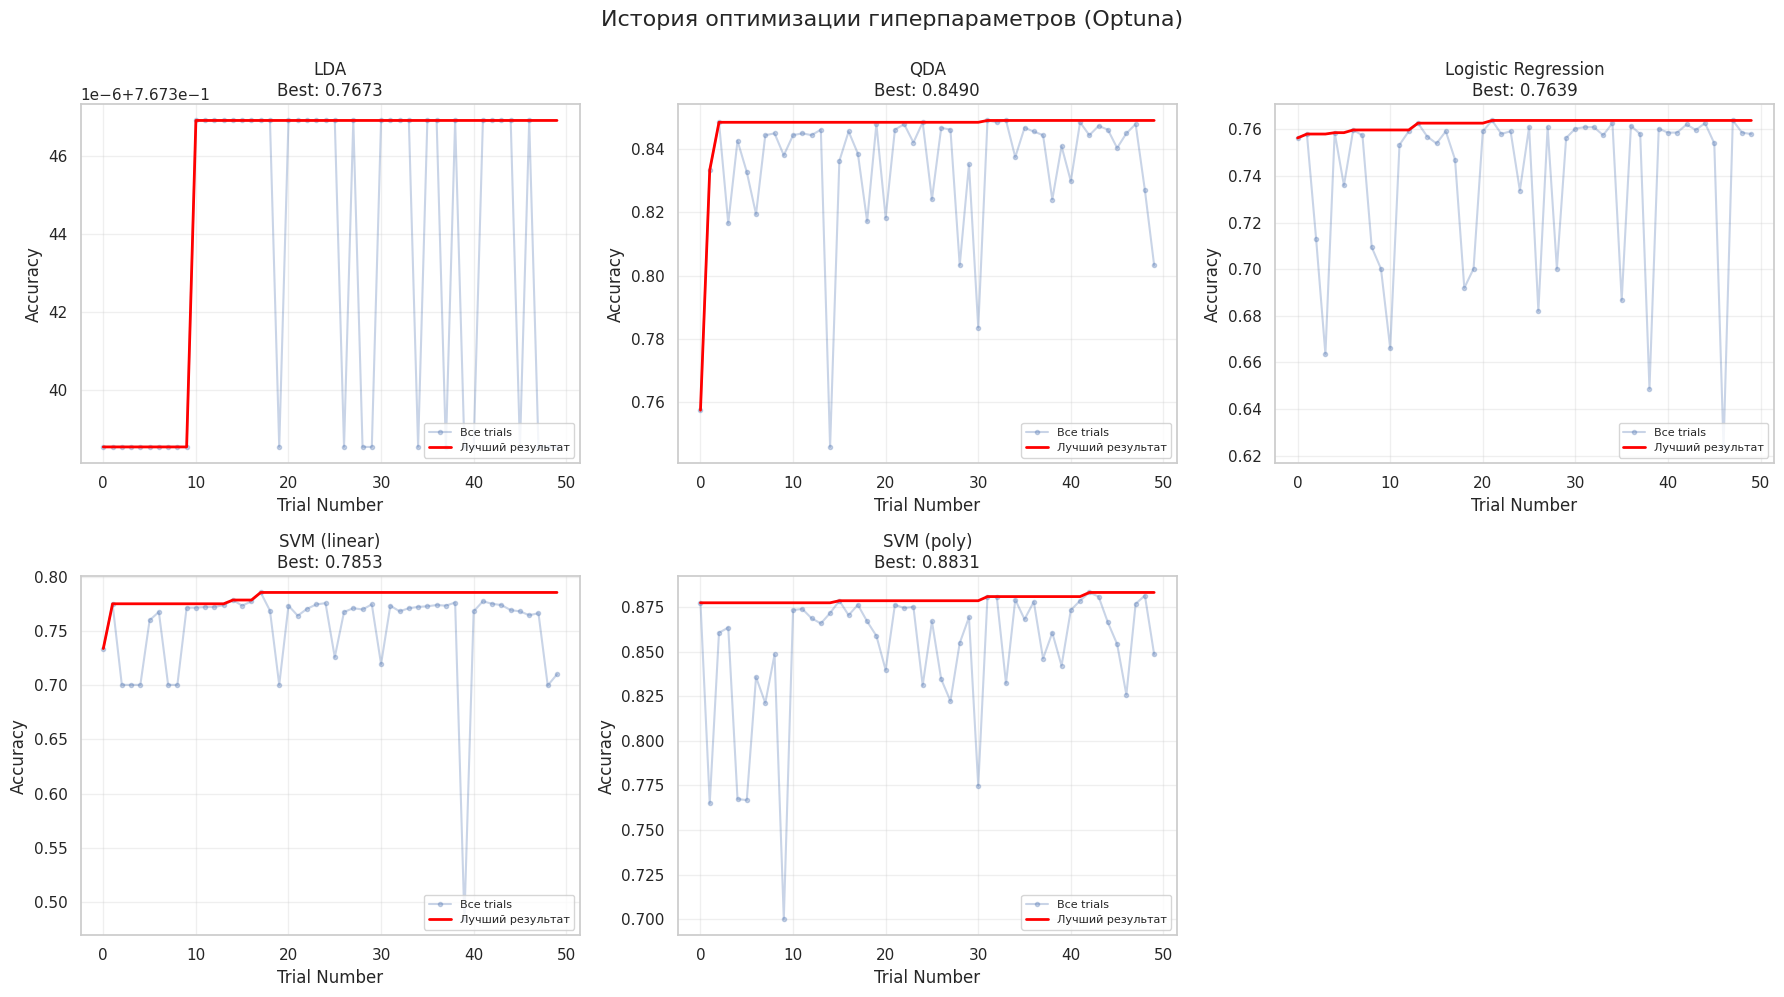

In [ ]:
print("\n" + "=" * 70)
print("ВИЗУАЛИЗАЦИЯ ИСТОРИИ ОПТИМИЗАЦИИ")
print("=" * 70)

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

studies: List[Tuple[str, optuna.Study]] = [
    ('LDA', study_lda),
    ('QDA', study_qda),
    ('Logistic Regression', study_lr),
    ('SVM (linear)', study_svm_lin),
    ('SVM (poly)', study_svm_poly)
]

for idx, (name, study) in enumerate(studies):
    ax = axes[idx]
    
    # Получаем историю trials
    trials = study.trials
    values: List[float] = [t.value for t in trials if t.value is not None]
    
    # Кумулятивный максимум
    best_values: np.ndarray = np.maximum.accumulate(values)
    print(f"idx: {idx} trials: {trials} values: {values} best_values: {best_values}")
    
    ax.plot(range(len(values)), values, 'o-', alpha=0.3, label='Все trials', markersize=3)
    ax.plot(range(len(best_values)), best_values, '-', linewidth=2, label='Лучший результат', color='red')
    
    ax.set_xlabel('Trial Number')
    ax.set_ylabel('Accuracy')
    ax.set_title(f'{name}\nBest: {study.best_value:.4f}')
    ax.legend(loc='lower right', fontsize=8)
    ax.grid(True, alpha=0.3)

# Скрываем последний пустой график
axes[5].axis('off')
plt.suptitle('История оптимизации гиперпараметров (Optuna)', fontsize=16, y=0.995)
plt.tight_layout()
plt.show()

In [124]:
studies

[('LDA', <optuna.study.study.Study at 0x7532d8357380>),
 ('QDA', <optuna.study.study.Study at 0x7532db7a62a0>),
 ('Logistic Regression', <optuna.study.study.Study at 0x7532d87eb9e0>),
 ('SVM (linear)', <optuna.study.study.Study at 0x7532d8b668a0>),
 ('SVM (poly)', <optuna.study.study.Study at 0x7532db5d0d40>)]

In [127]:
print("\n" + "=" * 70)
print("ИТОГОВЫЕ ЛУЧШИЕ ПАРАМЕТРЫ МОДЕЛЕЙ")
print("=" * 70)

for model_name, result in optimization_results.items():
    print(f"\n{model_name}:")
    print(f"  Best Accuracy: {result['best_score']:.4f}")
    print(f"  Best Parameters:")
    for param, value in result['best_params'].items():
        print(f"    - {param}: {value}")

print("\n" + "=" * 70)


ИТОГОВЫЕ ЛУЧШИЕ ПАРАМЕТРЫ МОДЕЛЕЙ

LDA:
  Best Accuracy: 0.7673
  Best Parameters:
    - solver: lsqr
    - shrinkage: auto

QDA:
  Best Accuracy: 0.8490
  Best Parameters:
    - reg_param: 0.04279225889085967
    - tol: 4.772625473438607e-05

Logistic:
  Best Accuracy: 0.7639
  Best Parameters:
    - C: 0.1636128616124501
    - solver: newton-cg
    - tol: 1.6076142270185676e-07
    - class_weight: None

SVM_linear:
  Best Accuracy: 0.7853
  Best Parameters:
    - C: 0.021556363409305203
    - tol: 0.0007339255287449307
    - class_weight: None

SVM_poly:
  Best Accuracy: 0.8831
  Best Parameters:
    - C: 5.813202252139866
    - degree: 3
    - gamma: auto
    - tol: 0.0004910140363342296
    - class_weight: None



## Матрица ошибок

### Вариант 1: Для статичных моделей 

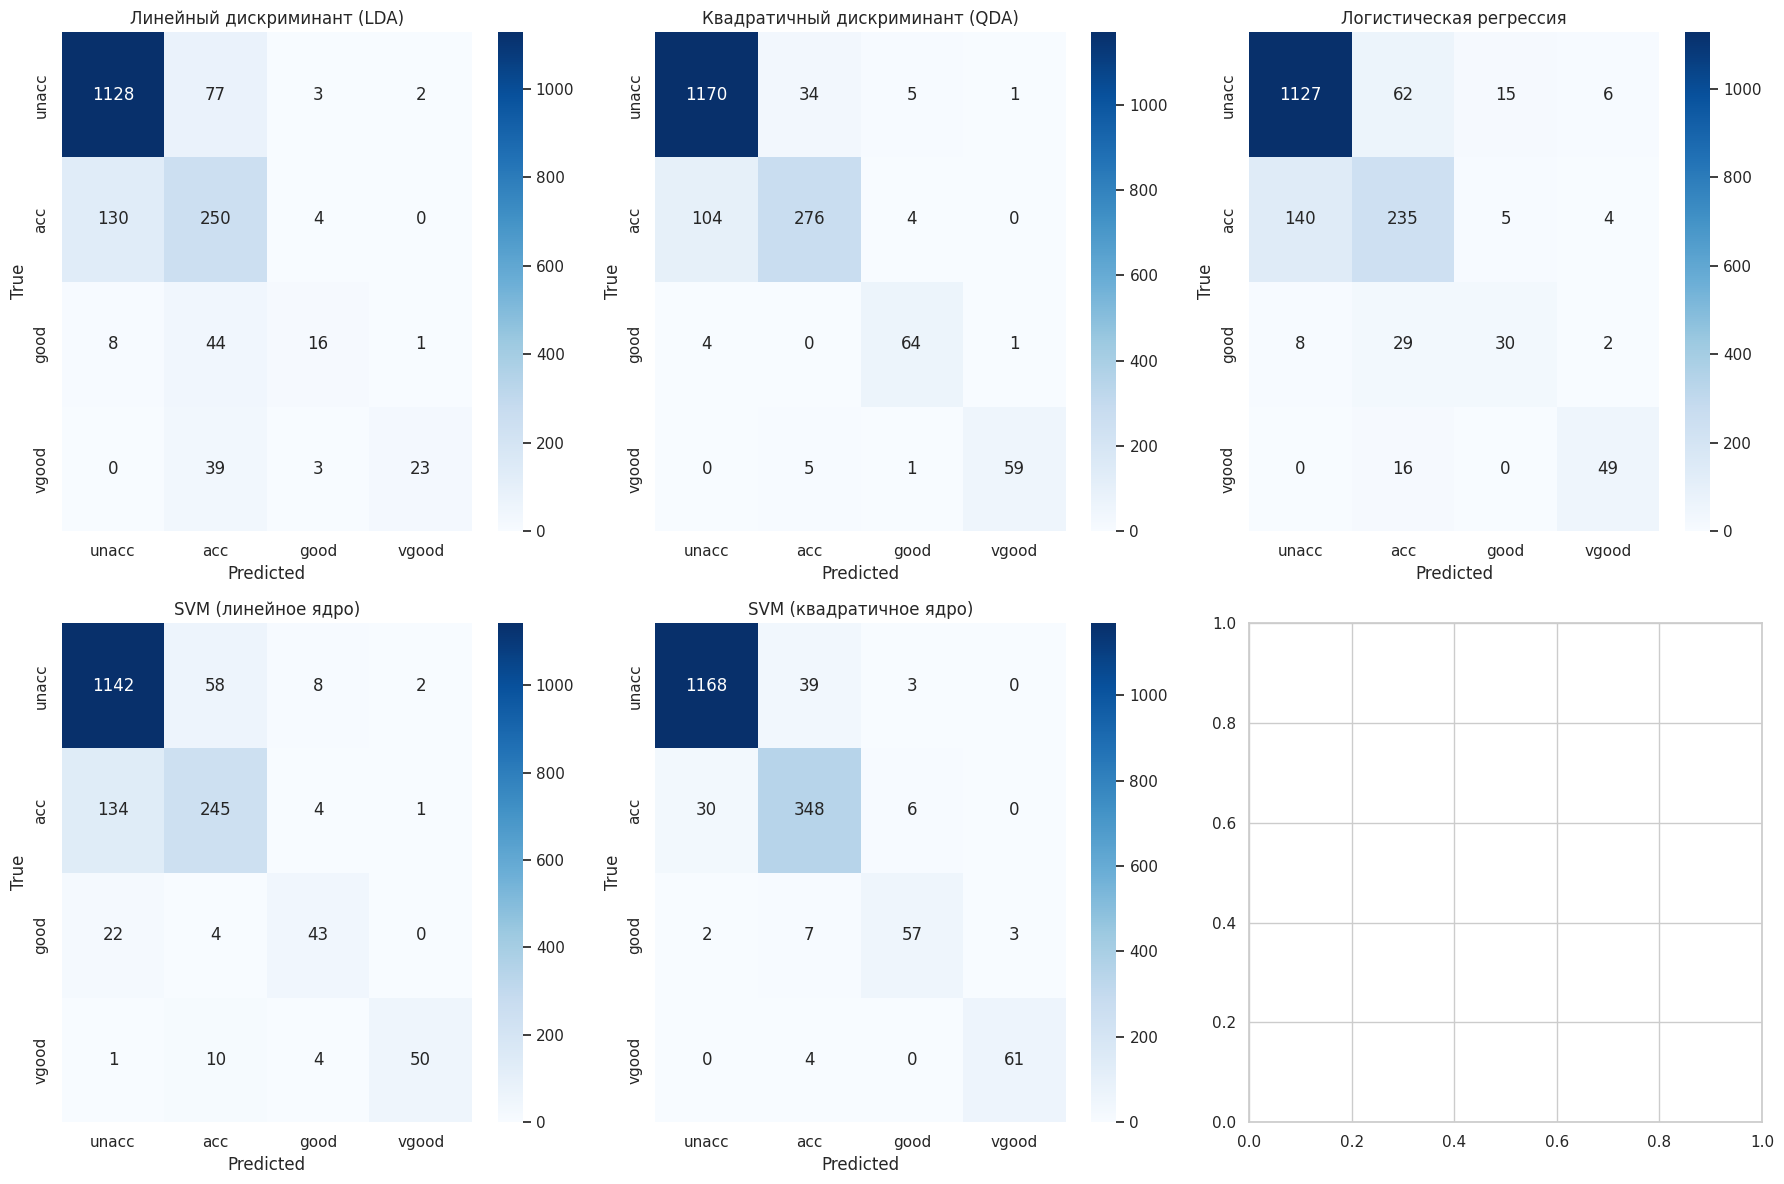

In [129]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    y_pred = model.predict(X_all)
    
    ax = axes[i]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['unacc', 'acc', 'good', 'vgood'],
                yticklabels=['unacc', 'acc', 'good', 'vgood'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Вариант 2: Для моделей после Optuna

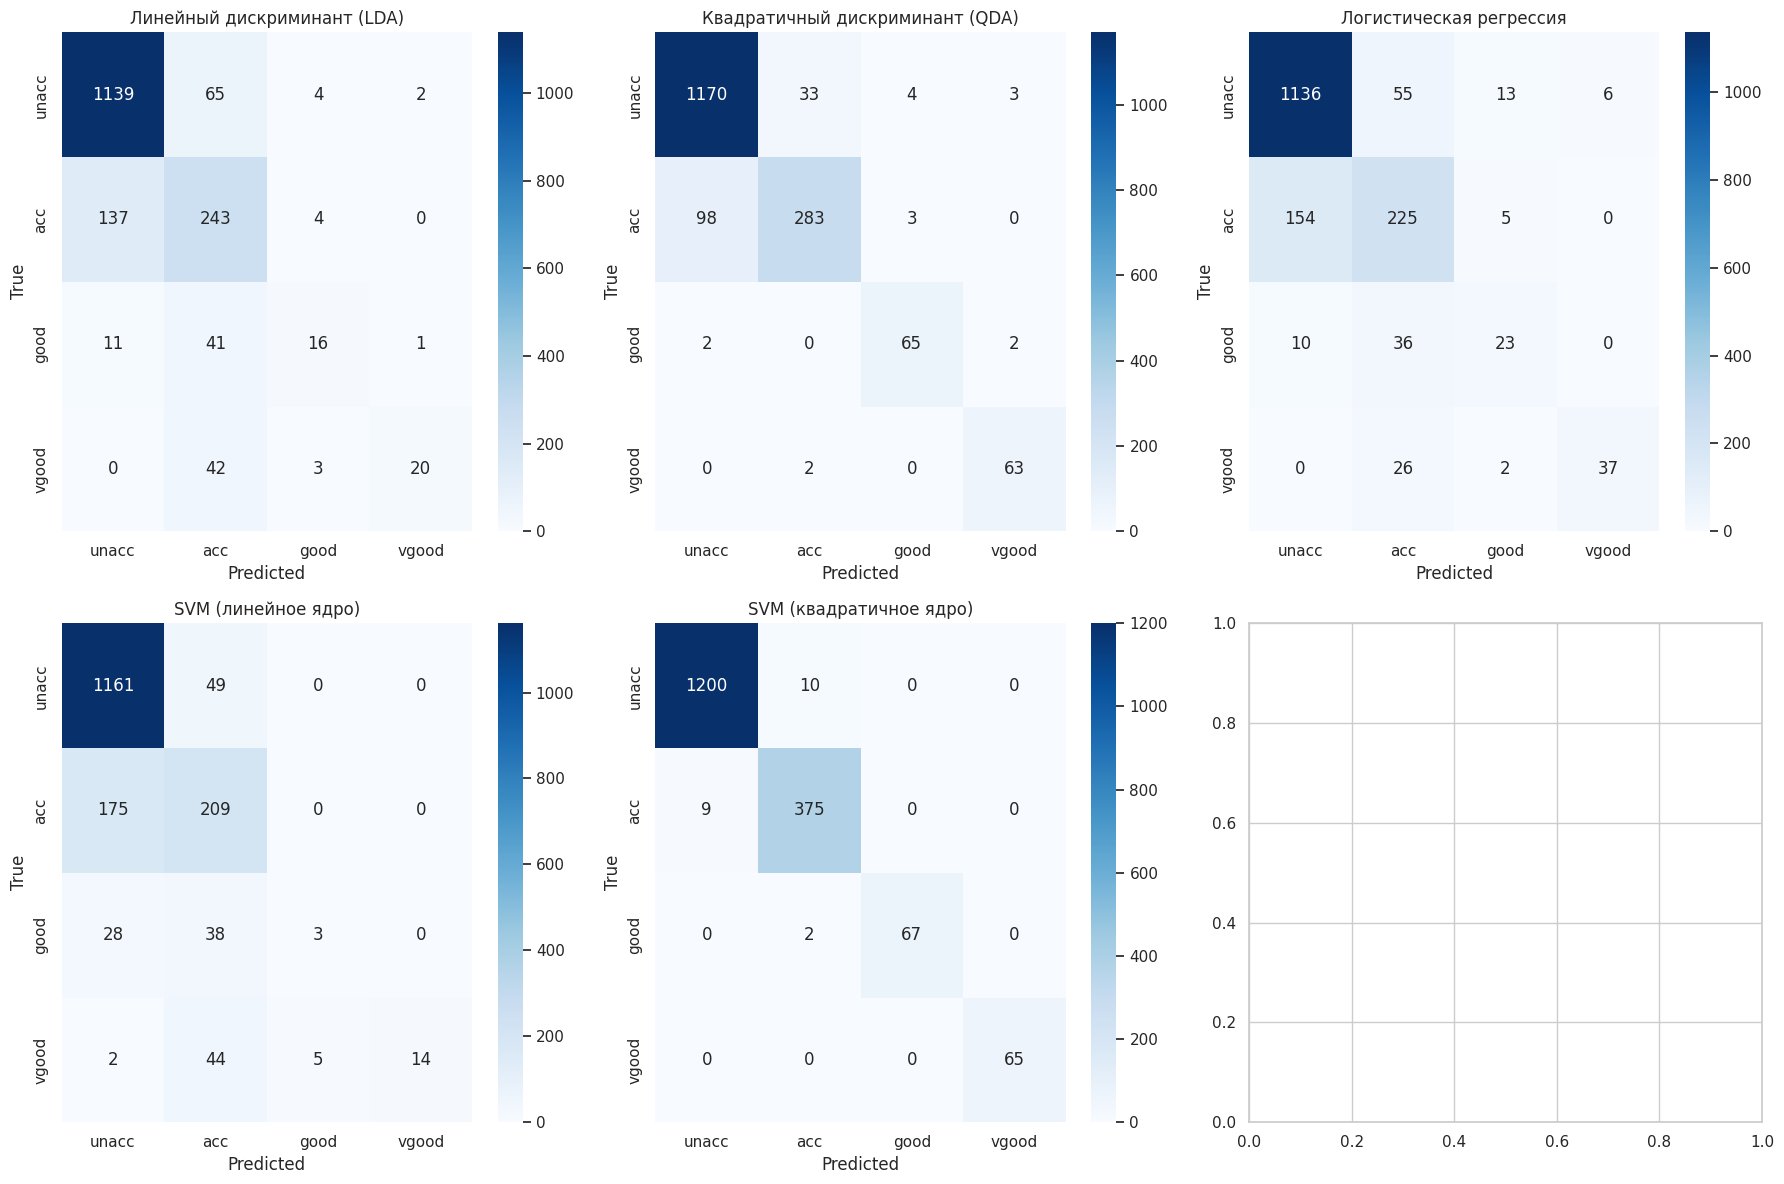

In [130]:
fig, axes = plt.subplots(2, 3, figsize=(18, 12))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    model.fit(X_all, y)
    y_pred = model.predict(X_all)
    
    ax = axes[i]
    cm = confusion_matrix(y, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=ax,
                xticklabels=['unacc', 'acc', 'good', 'vgood'],
                yticklabels=['unacc', 'acc', 'good', 'vgood'])
    ax.set_xlabel('Predicted')
    ax.set_ylabel('True')
    ax.set_title(name)

plt.tight_layout()
plt.show()

### Текстовый отчёт для лучшей модели

In [ ]:
print("\nКлассификационный отчёт для LDA:")
lda_full: LinearDiscriminantAnalysis = LinearDiscriminantAnalysis(
    solver='lsqr',
    shrinkage='auto'
)
lda_full.fit(X_all, y)
print(classification_report(y, lda_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
lda_full


Классификационный отчёт для LDA:
              precision    recall  f1-score   support

       unacc       0.89      0.94      0.91      1210
         acc       0.62      0.63      0.63       384
        good       0.59      0.23      0.33        69
       vgood       0.87      0.31      0.45        65

    accuracy                           0.82      1728
   macro avg       0.74      0.53      0.58      1728
weighted avg       0.81      0.82      0.81      1728



,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'lsqr'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",'auto'
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


In [ ]:
print("\nКлассификационный отчёт для QDA:")
qda_full: QuadraticDiscriminantAnalysis = QuadraticDiscriminantAnalysis(
    reg_param=0.04279225889085967,
    tol=4.772625473438607e-05
)
qda_full.fit(X_all, y)
print(classification_report(y, qda_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
qda_full


Классификационный отчёт для QDA:
              precision    recall  f1-score   support

       unacc       0.92      0.97      0.94      1210
         acc       0.89      0.74      0.81       384
        good       0.90      0.94      0.92        69
       vgood       0.93      0.97      0.95        65

    accuracy                           0.91      1728
   macro avg       0.91      0.90      0.90      1728
weighted avg       0.91      0.91      0.91      1728



,"solver solver: {'svd', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter. Enabling shrinkage is expected to improve the model when some classes have a relatively small number of training data points compared to the number of features by mitigating overfitting during the covariance estimation step.This should be left to `None` if `covariance_estimator` is used.Note that shrinkage works only with 'eigen' solver.",None
,"priors priors: array-like of shape (n_classes,), default=NoneClass priors. By default, the class proportions are inferred from thetraining data.",None
,"reg_param reg_param: float, default=0.0Regularizes the per-class covariance estimates by transforming S2 as``S2 = (1 - reg_param) * S2 + reg_param * np.eye(n_features)``,where S2 corresponds to the `scaling_` attribute of a given class.",0.04279225889085967
,"store_covariance store_covariance: bool, default=FalseIf True, the class covariance matrices are explicitly computed andstored in the `self.covariance_` attribute... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for the covariance matrix to be considered rankdeficient after applying some regularization (see `reg_param`) to each`Sk` where `Sk` represents covariance matrix for k-th class. Thisparameter does not affect the predictions. It controls when a warningis raised if the covariance matrix is not full rank... versionadded:: 0.17",4.772625473438607e-05
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimate the covariancematrices instead of relying on the empirical covariance estimator(with potential shrinkage). The object should have a fit method anda ``covariance_`` attribute like the estimators in:mod:`sklearn.covariance`. If None the shrinkage parameter drives theestimate.This should be left to `None` if `shrinkage` is used.Note that `covariance_estimator` works only with the 'eigen' solver.",None


In [ ]:
print("\nКлассификационный отчёт для Logistic:")
logistic_full: LogisticRegression = LogisticRegression(
    C=0.1636128616124501,
    solver='newton-cg',
    max_iter=1000,
    tol=1.6076142270185676e-07,
    class_weight=None,
    random_state=RANDOM_STATE
)
logistic_full.fit(X_all, y)
print(classification_report(y, logistic_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
logistic_full


Классификационный отчёт для Logistic:
              precision    recall  f1-score   support

       unacc       0.87      0.94      0.91      1210
         acc       0.66      0.59      0.62       384
        good       0.53      0.33      0.41        69
       vgood       0.86      0.57      0.69        65

    accuracy                           0.82      1728
   macro avg       0.73      0.61      0.66      1728
weighted avg       0.81      0.82      0.81      1728



,"penalty penalty: {'l1', 'l2', 'elasticnet', None}, default='l2'Specify the norm of the penalty:- `None`: no penalty is added;- `'l2'`: add a L2 penalty term and it is the default choice;- `'l1'`: add a L1 penalty term;- `'elasticnet'`: both L1 and L2 penalty terms are added... warning:: Some penalties may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionadded:: 0.19 l1 penalty with SAGA solver (allowing 'multinomial' + L1).. deprecated:: 1.8 `penalty` was deprecated in version 1.8 and will be removed in 1.10. Use `l1_ratio` instead. `l1_ratio=0` for `penalty='l2'`, `l1_ratio=1` for `penalty='l1'` and `l1_ratio` set to any float between 0 and 1 for `'penalty='elasticnet'`.",'deprecated'
,"C C: float, default=1.0Inverse of regularization strength; must be a positive float.Like in support vector machines, smaller values specify strongerregularization. `C=np.inf` results in unpenalized logistic regression.For a visual example on the effect of tuning the `C` parameterwith an L1 penalty, see::ref:`sphx_glr_auto_examples_linear_model_plot_logistic_path.py`.",0.1636128616124501
,"l1_ratio l1_ratio: float, default=0.0The Elastic-Net mixing parameter, with `0 <= l1_ratio <= 1`. Setting`l1_ratio=1` gives a pure L1-penalty, setting `l1_ratio=0` a pure L2-penalty.Any value between 0 and 1 gives an Elastic-Net penalty of the form`l1_ratio * L1 + (1 - l1_ratio) * L2`... warning:: Certain values of `l1_ratio`, i.e. some penalties, may not work with some solvers. See the parameter `solver` below, to know the compatibility between the penalty and solver... versionchanged:: 1.8 Default value changed from None to 0.0... deprecated:: 1.8 `None` is deprecated and will be removed in version 1.10. Always use `l1_ratio` to specify the penalty type.",0.0
,"dual dual: bool, default=FalseDual (constrained) or primal (regularized, see also:ref:`this equation `) formulation. Dual formulationis only implemented for l2 penalty with liblinear solver. Prefer `dual=False`when n_samples > n_features.",False
,"tol tol: float, default=1e-4Tolerance for stopping criteria.",1.6076142270185676e-07
,"fit_intercept fit_intercept: bool, default=TrueSpecifies if a constant (a.k.a. bias or intercept) should beadded to the decision function.",True
,"intercept_scaling intercept_scaling: float, default=1Useful only when the solver `liblinear` is usedand `self.fit_intercept` is set to `True`. In this case, `x` becomes`[x, self.intercept_scaling]`,i.e. a ""synthetic"" feature with constant value equal to`intercept_scaling` is appended to the instance vector.The intercept becomes``intercept_scaling * synthetic_feature_weight``... note:: The synthetic feature weight is subject to L1 or L2 regularization as all other features. To lessen the effect of regularization on synthetic feature weight (and therefore on the intercept) `intercept_scaling` has to be increased.",1
,"class_weight class_weight: dict or 'balanced', default=NoneWeights associated with classes in the form ``{class_label: weight}``.If not given, all classes are supposed to have weight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.Note that these weights will be multiplied with sample_weight (passedthrough the fit method) if sample_weight is specified... versionadded:: 0.17 *class_weight='balanced'*",None
,"random_state random_state: int, RandomState instance, default=NoneUsed when ``solver`` == 'sag', 'saga' or 'liblinear' to shuffle thedata. See :term:`Glossary ` for details.",42
,"solver solver: {'lbfgs', 'liblinear', 'newton-cg', 'newton-cholesky', 'sag', 'saga'}, default='lbfgs'Algorithm to use in the optimization problem. Default is 'lbfgs'.To choose a solver, you might want to consider the following aspects:- 'lbfgs' is a good default solver because it works reasonably well for a wide class

In [ ]:
print("\nКлассификационный отчёт для SVC (Linear):")
svc_linear_full: SVC = SVC(kernel='linear',
    C=0.021556363409305203,
    tol=0.0007339255287449307,
    class_weight=None,
    probability=True,
    random_state=RANDOM_STATE)
svc_linear_full.fit(X_all, y)
print(classification_report(y, svc_linear_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
svc_linear_full


Классификационный отчёт для SVC (Linear):
              precision    recall  f1-score   support

       unacc       0.85      0.96      0.90      1210
         acc       0.61      0.54      0.58       384
        good       0.38      0.04      0.08        69
       vgood       1.00      0.22      0.35        65

    accuracy                           0.80      1728
   macro avg       0.71      0.44      0.48      1728
weighted avg       0.78      0.80      0.78      1728



,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",0.021556363409305203
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.0007339255287449307
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [ ]:
print("\nКлассификационный отчёт для SVC (Poly):")
svc_poly_full: SVC = SVC(kernel='poly',
    C=5.813202252139866,
    degree=3,
    gamma="auto",
    tol=0.0004910140363342296,
    class_weight=None,
    probability=True,
    random_state=RANDOM_STATE)
svc_poly_full.fit(X_all, y)
print(classification_report(y, svc_poly_full.predict(X_all), 
                           target_names=['unacc', 'acc', 'good', 'vgood']))
svc_poly_full


Классификационный отчёт для SVC (Poly):
              precision    recall  f1-score   support

       unacc       0.99      0.99      0.99      1210
         acc       0.97      0.98      0.97       384
        good       1.00      0.97      0.99        69
       vgood       1.00      1.00      1.00        65

    accuracy                           0.99      1728
   macro avg       0.99      0.98      0.99      1728
weighted avg       0.99      0.99      0.99      1728



,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",5.813202252139866
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'poly'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'auto'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide `.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide `.",True
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.0004910140363342296
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


## Кривые обучения (Learning Curves)

### Вариант 1: для статичных моделей

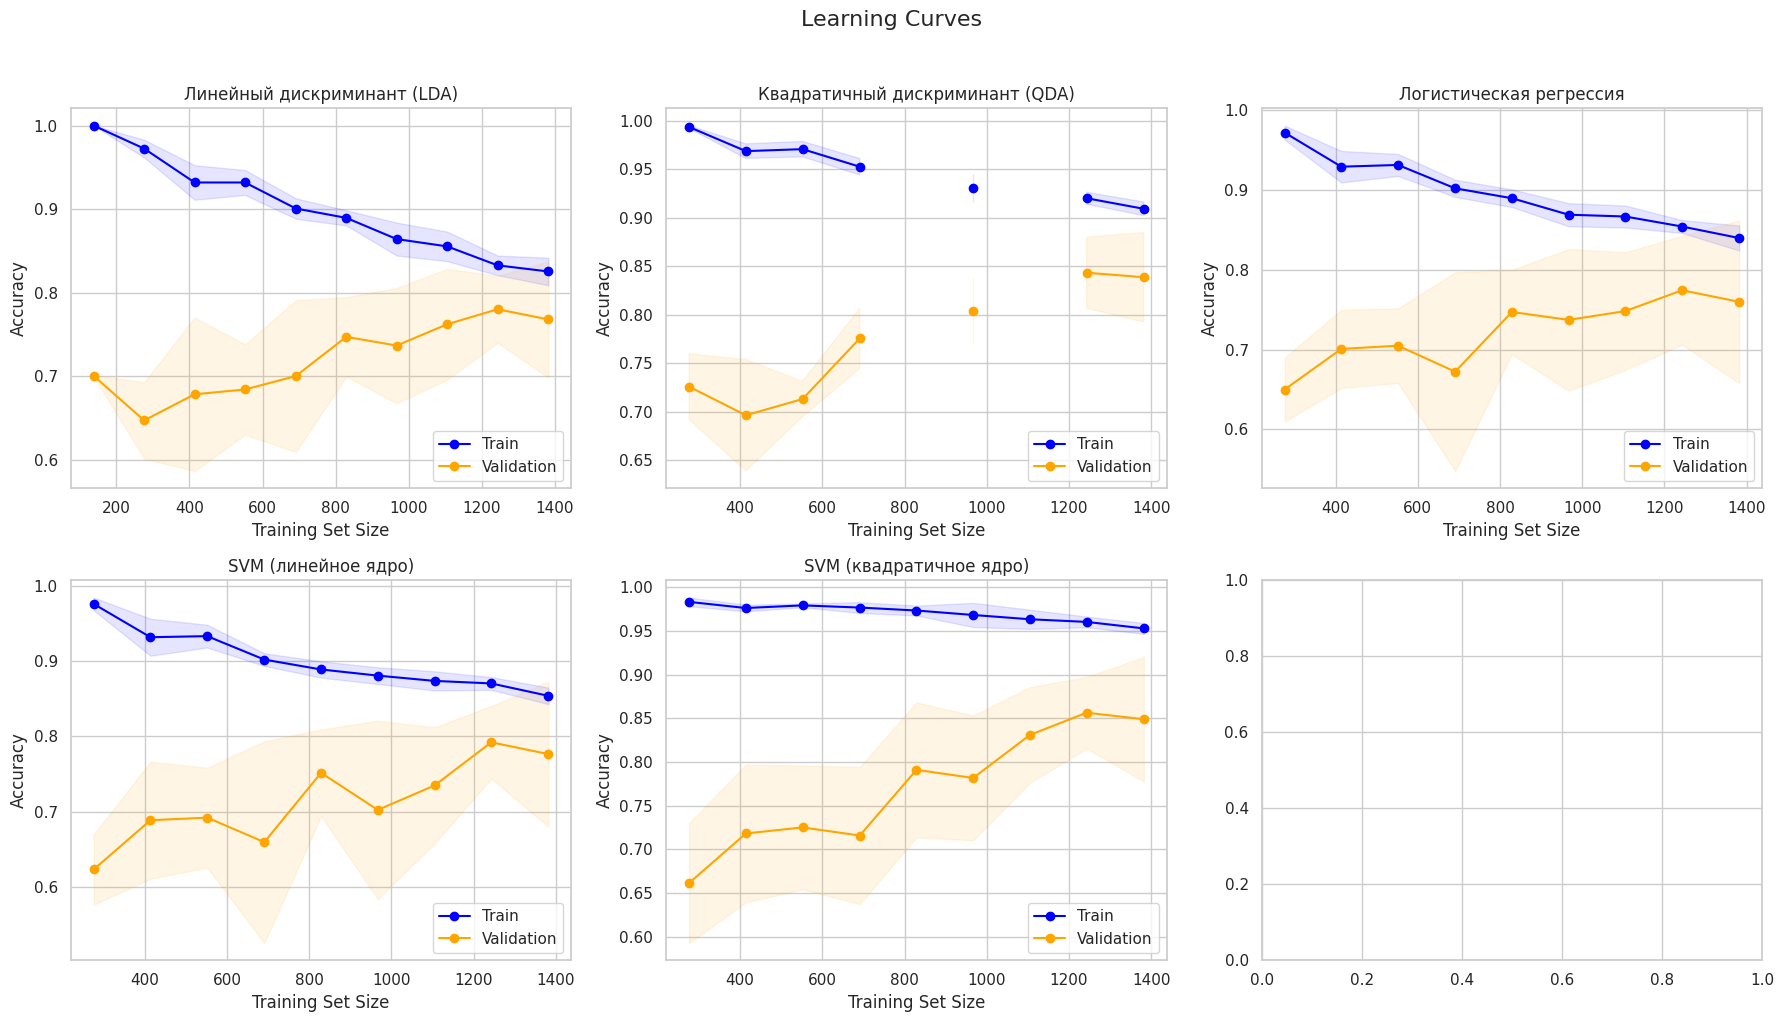

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_all, y, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=RANDOM_STATE
    )
    
    ax = axes[i]
    train_mean: float = train_scores.mean(axis=1)
    train_std: float = train_scores.std(axis=1)
    val_mean: float = val_scores.mean(axis=1)
    val_std: float = val_scores.std(axis=1)
    
    ax.plot(train_sizes, train_mean, 'o-', label='Train', color='blue')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation', color='orange')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
    
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Accuracy')
    ax.set_title(name)
    ax.legend(loc='lower right')
    ax.grid(True)

plt.suptitle('Learning Curves', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Вариант 2: для моделей после Optuna

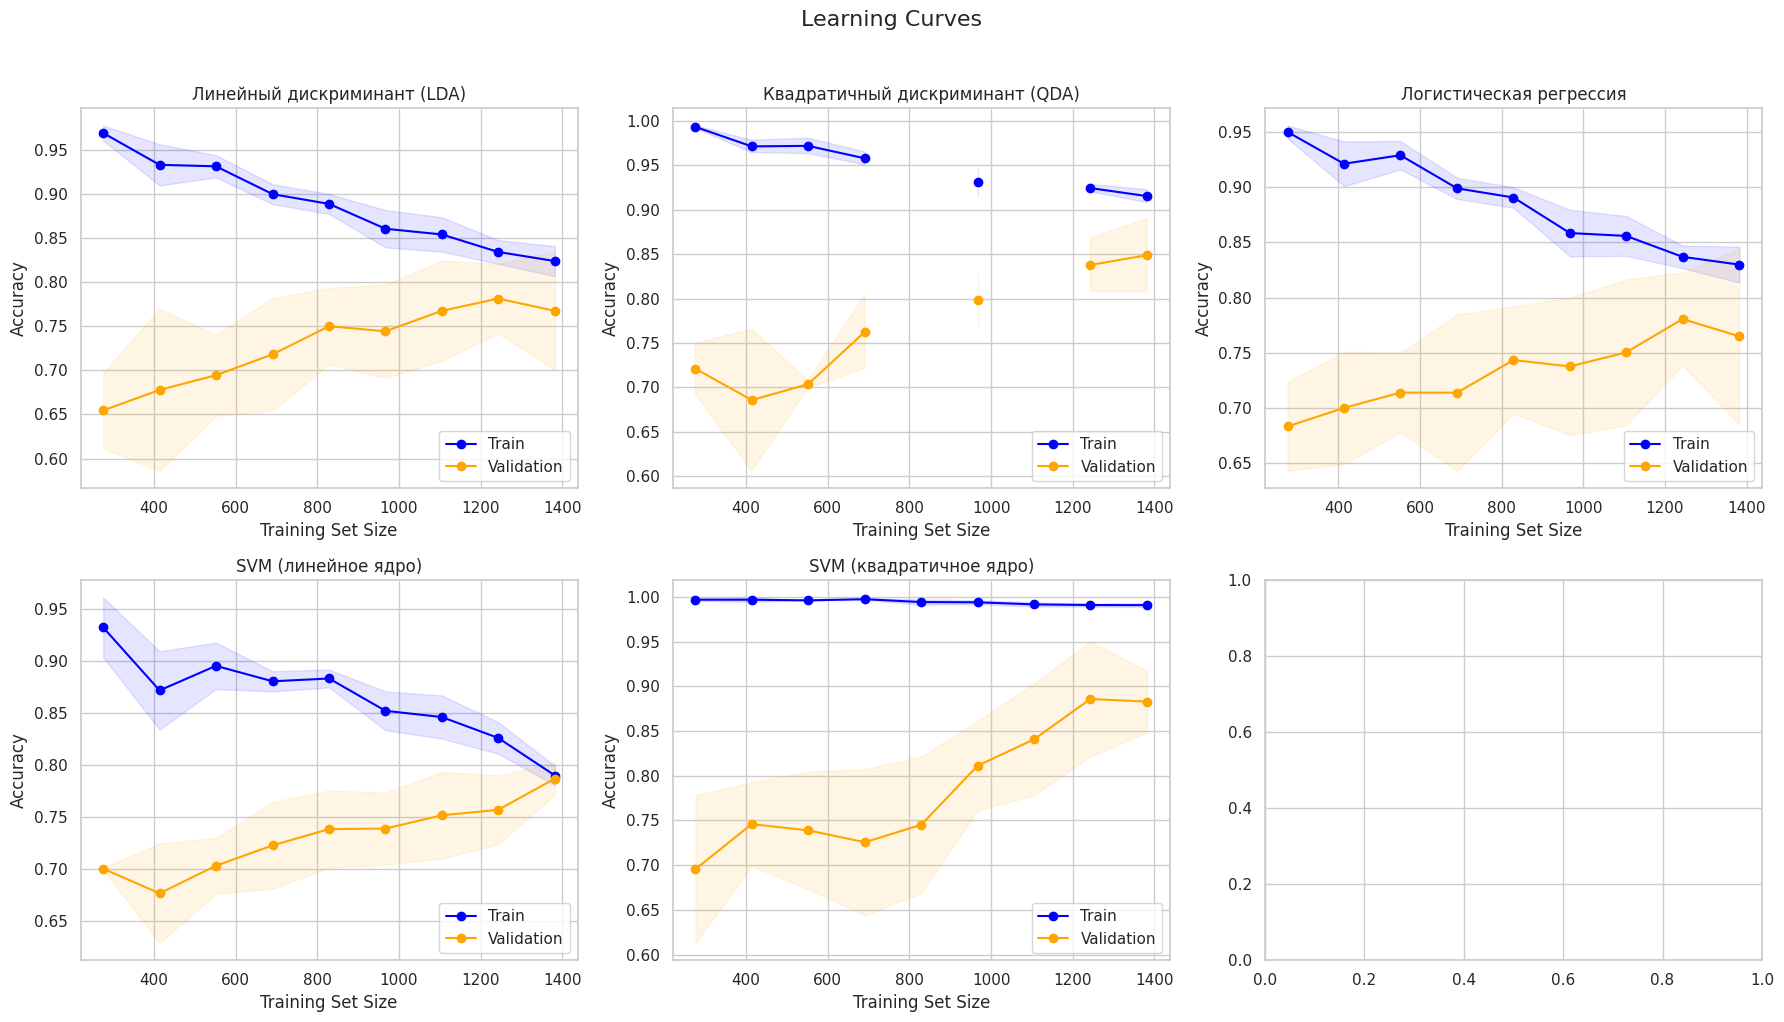

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    train_sizes, train_scores, val_scores = learning_curve(
        model, X_all, y, cv=5, scoring='accuracy',
        train_sizes=np.linspace(0.1, 1.0, 10), random_state=RANDOM_STATE
    )
    
    ax = axes[i]
    train_mean: float = train_scores.mean(axis=1)
    train_std: float = train_scores.std(axis=1)
    val_mean: float = val_scores.mean(axis=1)
    val_std: float = val_scores.std(axis=1)
    
    ax.plot(train_sizes, train_mean, 'o-', label='Train', color='blue')
    ax.fill_between(train_sizes, train_mean - train_std, train_mean + train_std, alpha=0.1, color='blue')
    ax.plot(train_sizes, val_mean, 'o-', label='Validation', color='orange')
    ax.fill_between(train_sizes, val_mean - val_std, val_mean + val_std, alpha=0.1, color='orange')
    
    ax.set_xlabel('Training Set Size')
    ax.set_ylabel('Accuracy')
    ax.set_title(name)
    ax.legend(loc='lower right')
    ax.grid(True)

plt.suptitle('Learning Curves', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## Калибровка вероятностей (Calibration Curves)

### Вариант 1: для статичных моделей

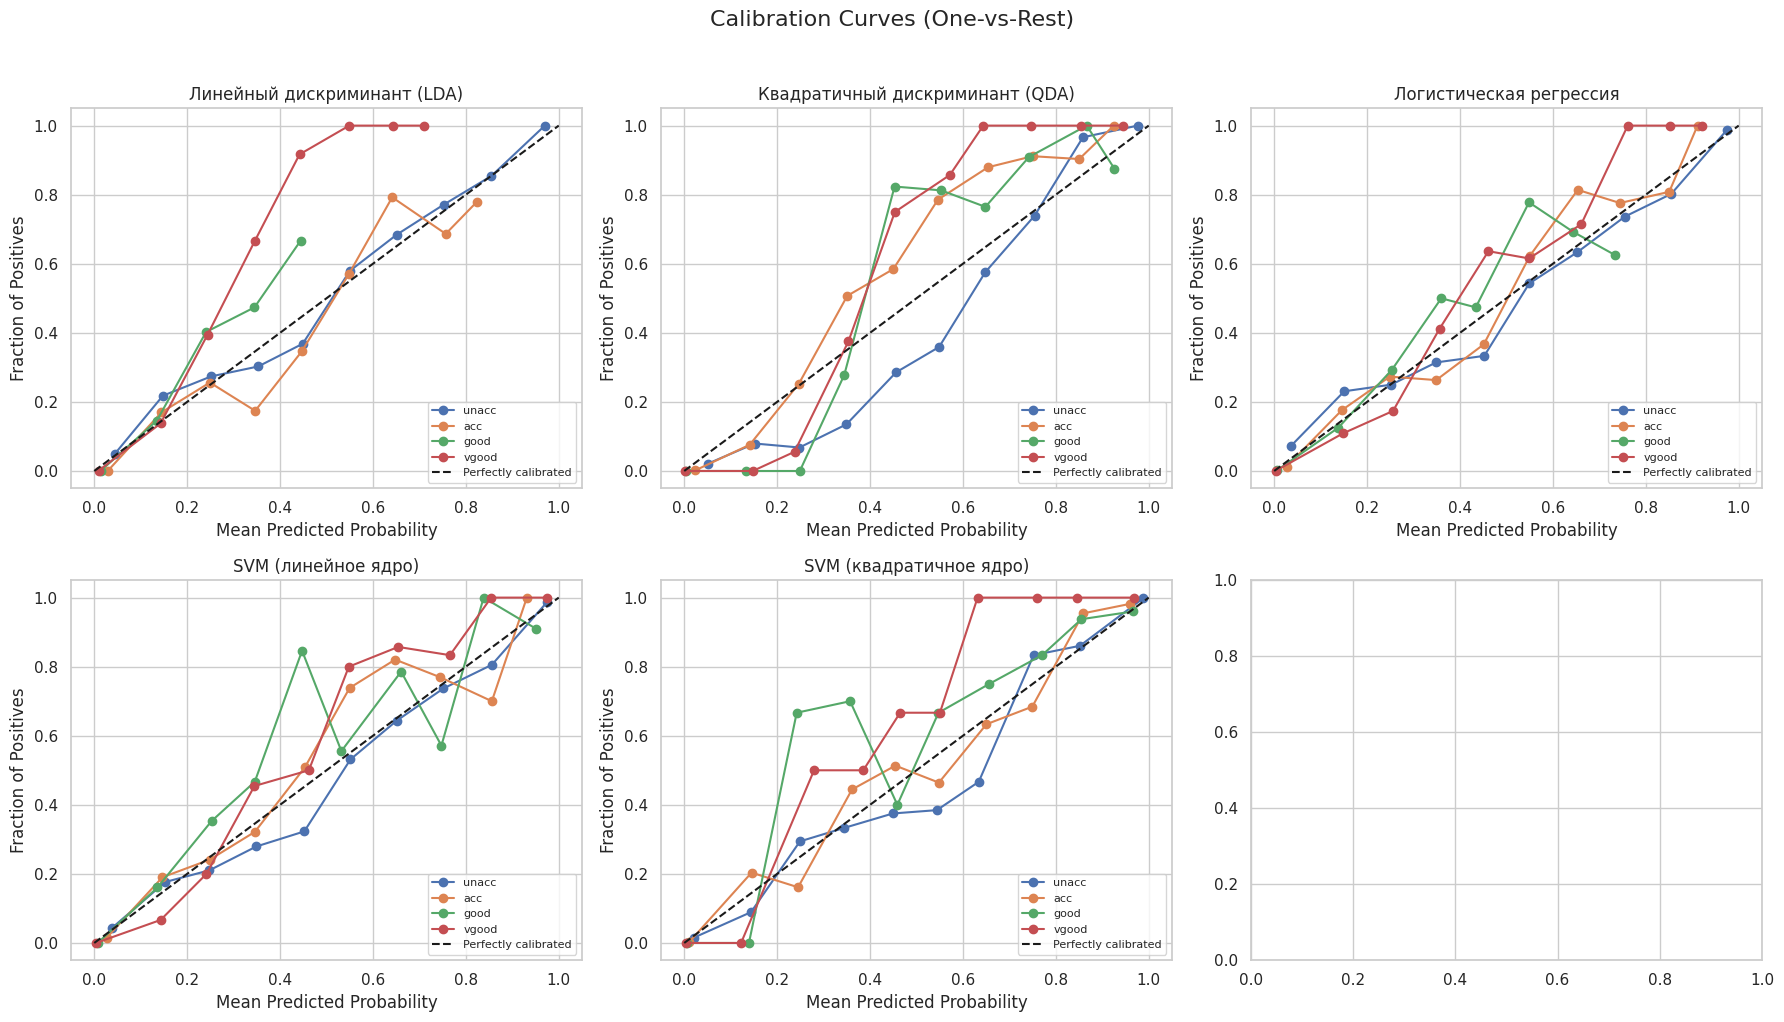

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models.items()):
    model.fit(X_all, y)
    
    # Для многоклассовой задачи используем one-vs-rest
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_all)
        
        ax = axes[i]
        for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
            y_true_binary: pd.Series = (y == j).astype(int)
            prob_true: np.ndarray
            prob_pred: np.ndarray
            prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=10)
            
            ax.plot(prob_pred, prob_true, 'o-', label=class_name)
        
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of Positives')
        ax.set_title(name)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True)
    else:
        axes[i].text(0.5, 0.5, 'No probability estimates', 
                    ha='center', va='center', transform=axes[i].transAxes)

plt.suptitle('Calibration Curves (One-vs-Rest)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

### Вариант 2: для моделей после Optuna

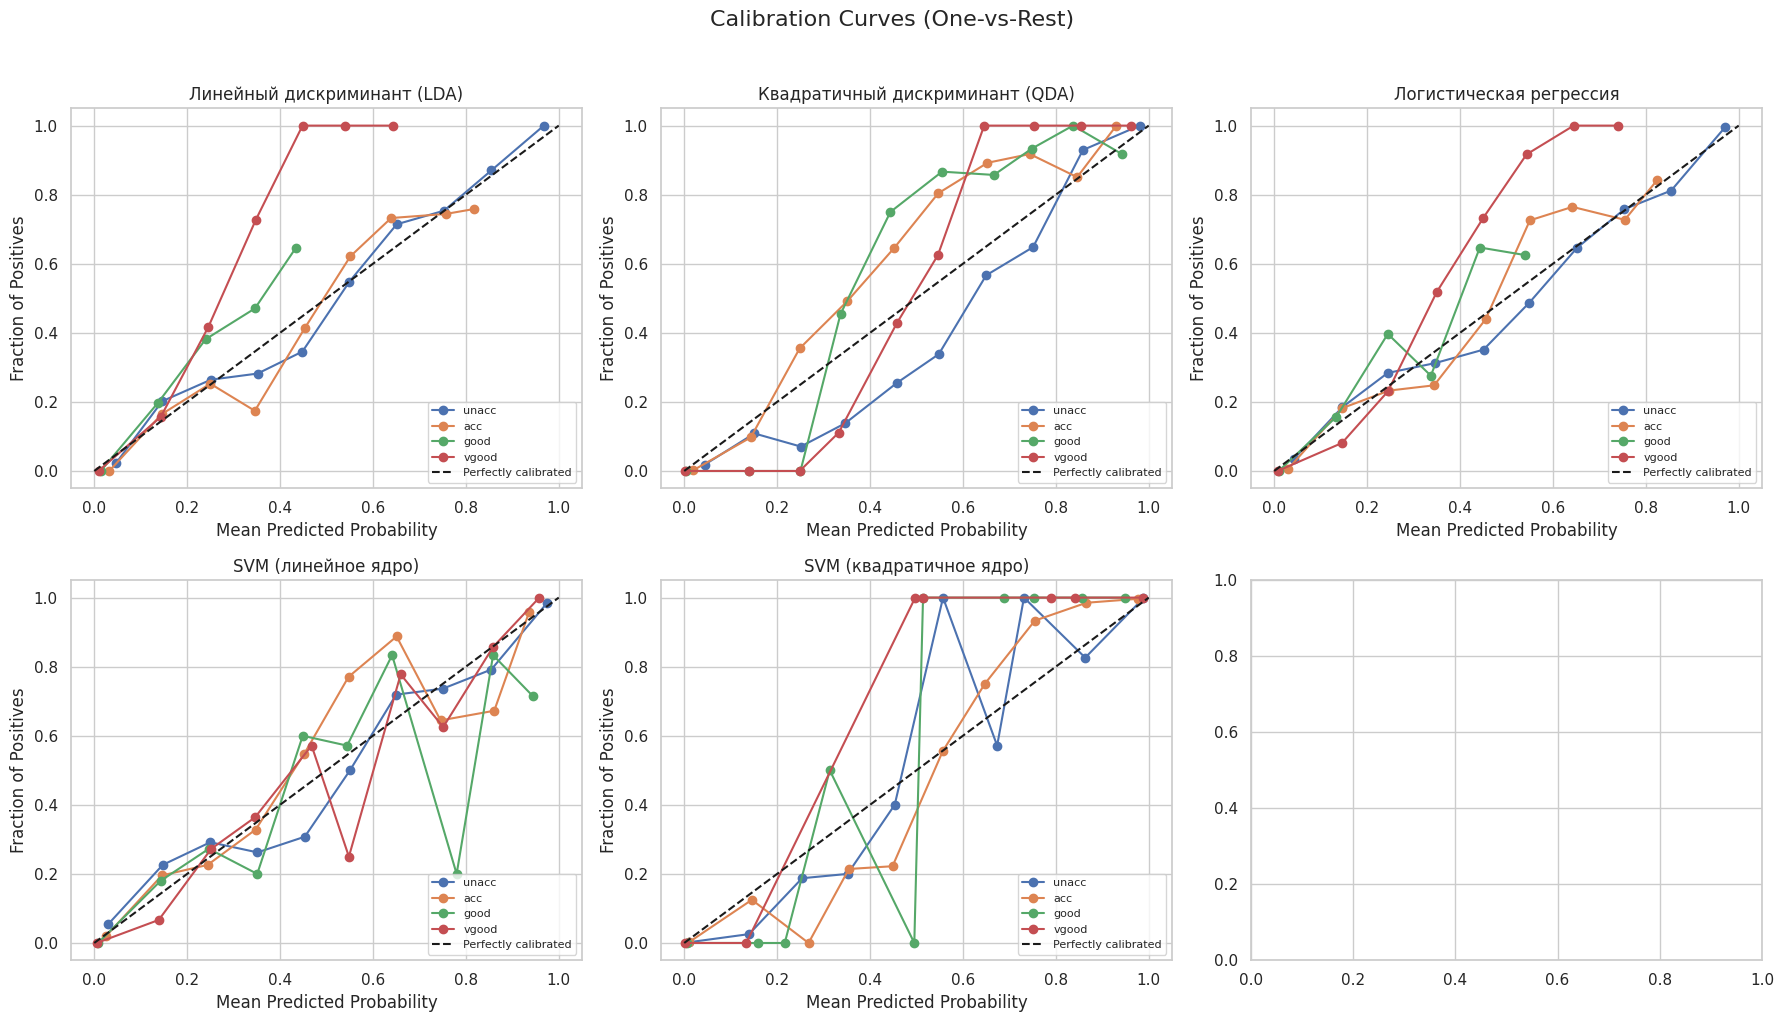

In [ ]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, model) in enumerate(models_optimized.items()):
    model.fit(X_all, y)
    
    # Для многоклассовой задачи используем one-vs-rest
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_all)
        
        ax = axes[i]
        for j, class_name in enumerate(['unacc', 'acc', 'good', 'vgood']):
            y_true_binary: pd.Series = (y == j).astype(int)
            prob_true: np.ndarray
            prob_pred: np.ndarray
            prob_true, prob_pred = calibration_curve(y_true_binary, y_prob[:, j], n_bins=10)
            
            ax.plot(prob_pred, prob_true, 'o-', label=class_name)
        
        ax.plot([0, 1], [0, 1], 'k--', label='Perfectly calibrated')
        ax.set_xlabel('Mean Predicted Probability')
        ax.set_ylabel('Fraction of Positives')
        ax.set_title(name)
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True)
    else:
        axes[i].text(0.5, 0.5, 'No probability estimates', 
                    ha='center', va='center', transform=axes[i].transAxes)

plt.suptitle('Calibration Curves (One-vs-Rest)', fontsize=16, y=1.02)
plt.tight_layout()
plt.show()

## 5. Интерпретируемость моделей (SHAP и Корреляция)
- **SHAP-анализ** (реализованный через подход One-vs-Rest для корректной работы с многоклассовой задачей в новых версиях библиотеки) однозначно указывает, что признаки **`safety`** и **`persons`** вносят наибольший вклад в предсказание классов `good` и `vgood`.
- Признаки стоимости (`buying`, `maint`) имеют меньший вес и более размытое влияние.
- **Матрица корреляции** подтверждает умеренную взаимосвязь между признаками, что обосновывает применение как линейных, так и нелинейных методов.

## Линейная модель

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


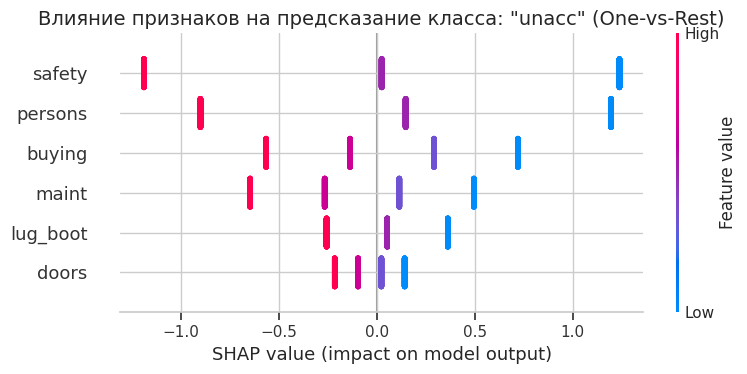

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


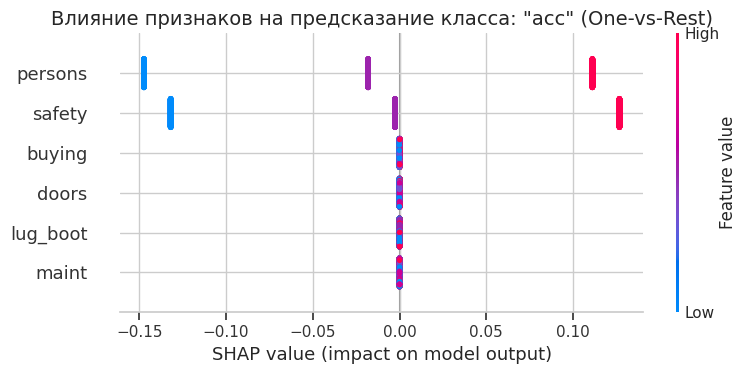

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


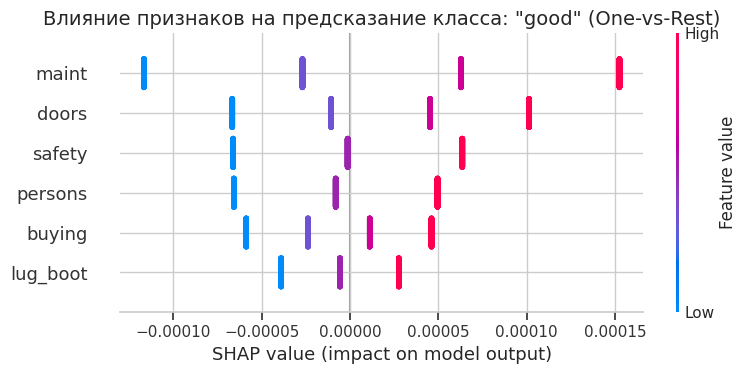

<Figure size 1200x600 with 0 Axes>

Background dataset has 1728 samples but max_samples=100. Subsampling to 100 samples for SHAP value computation. To use all samples, set max_samples=1728 when initializing the masker.


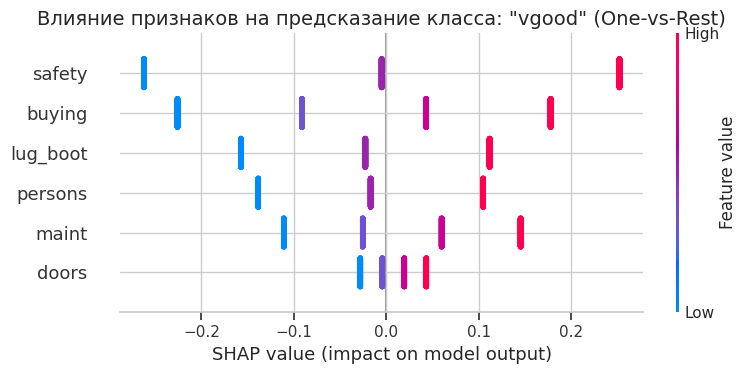

<Figure size 1200x600 with 0 Axes>

In [153]:
class_names: List[str] = ['unacc', 'acc', 'good', 'vgood']

# Для каждого класса обучаем отдельную бинарную модель
for i, class_name in enumerate(class_names):
    # Создаем бинарную метку: 1 если объект принадлежит классу i, иначе 0
    y_binary = (y == i).astype(int)
    
    # Обучаем бинарную модель
    best_svm_linear: SVC = SVC(
        kernel='linear',
        C=0.021556363409305203,
        tol=0.0007339255287449307,
        class_weight=None,
        probability=True,
        random_state=RANDOM_STATE
    )
    best_svm_linear.fit(X_all, y_binary)
    
    # SHAP для бинарной задачи работает корректно
    explainer: shap.LinearExplainer = shap.LinearExplainer(best_svm_linear, X_all)
    shap_values: np.ndarray = explainer.shap_values(X_all)
    
    # Визуализация
    plt.figure(figsize=(10, 6))
    plt.title(f'Влияние признаков на предсказание класса: "{class_name}" (One-vs-Rest)', fontsize=14)
    shap.summary_plot(shap_values, X_all, max_display=6)
    plt.tight_layout()
    plt.show()

## Квадратичная модель

   Вычисляем SHAP для класса 'unacc'...


100%|██████████| 200/200 [00:01<00:00, 152.50it/s]


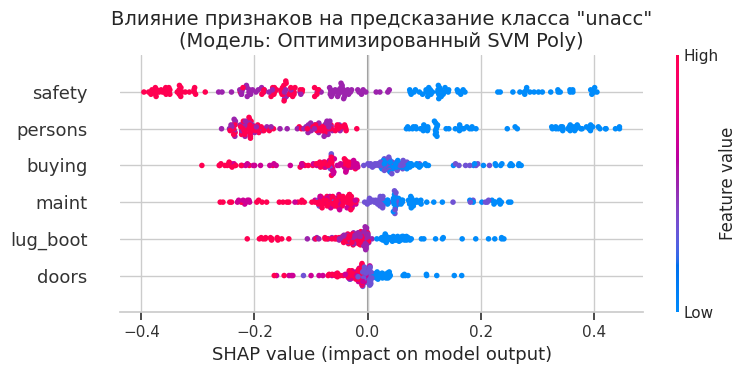

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'acc'...


100%|██████████| 200/200 [00:03<00:00, 50.57it/s]


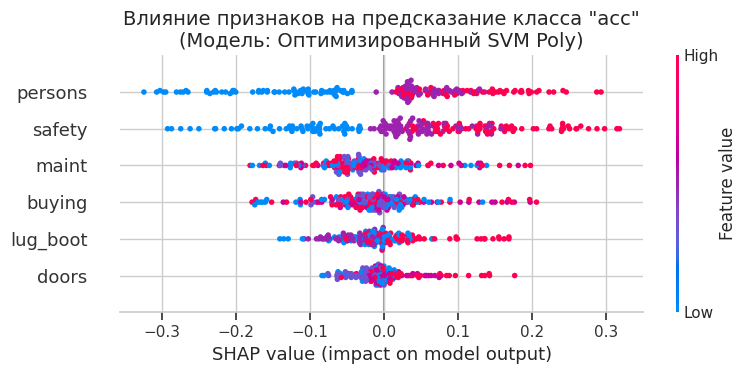

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'good'...


100%|██████████| 200/200 [00:01<00:00, 184.81it/s]


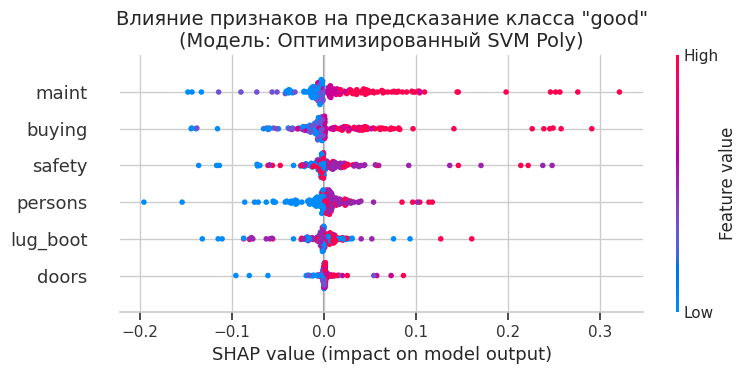

<Figure size 1200x600 with 0 Axes>

   Вычисляем SHAP для класса 'vgood'...


100%|██████████| 200/200 [00:00<00:00, 304.89it/s]


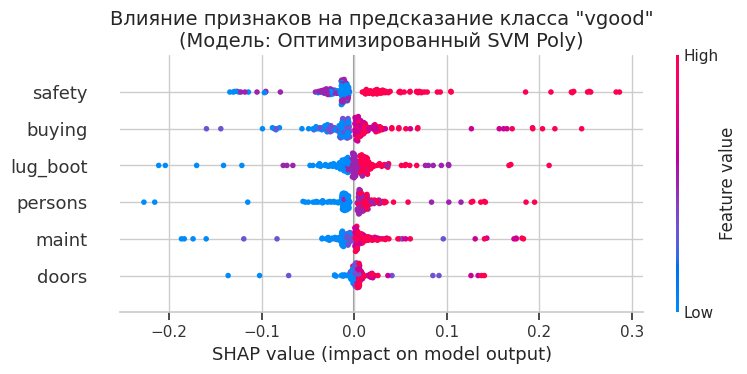

<Figure size 1200x600 with 0 Axes>

✅ SHAP-анализ для SVM Poly успешно завершен!


In [156]:
background = shap.kmeans(X_all, 50)

# Для каждого класса обучаем отдельную бинарную модель
for i, class_name in enumerate(class_names):
    print(f"   Вычисляем SHAP для класса '{class_name}'...")
    # Создаем бинарную метку: 1 если объект принадлежит классу i, иначе 0
    y_binary = (y == i).astype(int)

    best_svm_poly: SVC = SVC(
        kernel='poly',
        C=5.813202252139866,
        degree=3,
        gamma='auto',
        tol=0.0004910140363342296,
        class_weight=None,
        probability=True, # Обязательно для KernelExplainer с predict_proba
        random_state=RANDOM_STATE
    )
    
    # Обучаем бинарную модель
    best_svm_poly.fit(X_all, y_binary)

    def predict_proba_class1(x):
        return best_svm_poly.predict_proba(x)[:, 1]
    
    # SHAP для бинарной задачи работает корректно
    explainer: shap.KernelExplainer = shap.KernelExplainer(predict_proba_class1, background)

    # Берем подвыборку в 200 объектов для быстрой и красивой отрисовки графика
    X_sample = X_all.sample(n=200, random_state=RANDOM_STATE)

    shap_values: np.ndarray = explainer.shap_values(X_sample)
    
    # Визуализация
    plt.figure(figsize=(10, 6))
    plt.title(f'Влияние признаков на предсказание класса "{class_name}"\n(Модель: Оптимизированный SVM Poly)', fontsize=14)
    shap.summary_plot(shap_values, X_sample, max_display=6)
    plt.tight_layout()
    plt.show()
print("✅ SHAP-анализ для SVM Poly успешно завершен!")

### Для глубокой интерпретации была выбрана **лучшая модель пайплайна — SVM с полиномиальным ядром (degree=3)**. Поскольку данная модель является нелинейной, для расчета вкладов признаков был использован *shap.KernelExplainer*. SHAP-анализ подтвердил, что даже в сложной нелинейной модели решающую роль для классов good и vgood играют признаки safety и persons. При этом, благодаря полиномиальному ядру, модель научилась учитывать сложные взаимодействия между признаками (например, комбинация safety=high и buying=low дает синергетический положительный эффект), что и позволило достичь точности в 99%, недоступной для простой линейной регрессии

## Тепловая карта корреляций между признаками

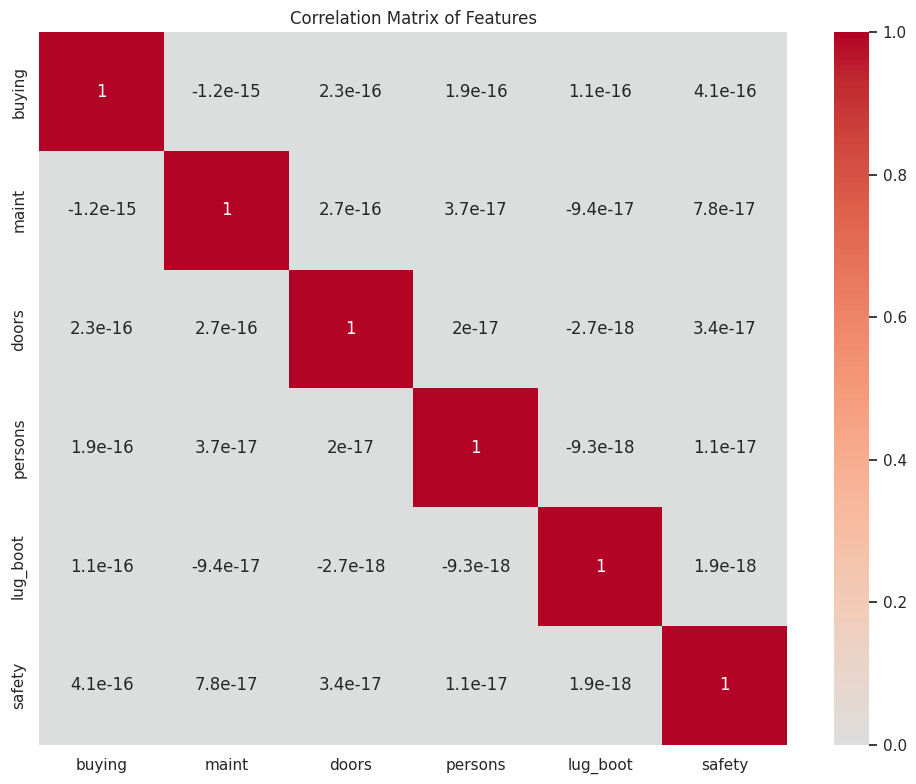

In [ ]:
plt.figure(figsize=(10, 8))
corr_matrix: pd.DataFrame = X_all.corr()
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', center=0)
plt.title('Correlation Matrix of Features')
plt.tight_layout()
plt.show()

## Обучение LinearDiscriminantAnalysis (LDA) на всем признаковом пространстве и настройки

In [148]:
lda_full: LinearDiscriminantAnalysis = LinearDiscriminantAnalysis()
lda_full.fit(X_all, y)

,"solver solver: {'svd', 'lsqr', 'eigen'}, default='svd'Solver to use, possible values: - 'svd': Singular value decomposition (default). Does not compute the covariance matrix, therefore this solver is recommended for data with a large number of features. - 'lsqr': Least squares solution. Can be combined with shrinkage or custom covariance estimator. - 'eigen': Eigenvalue decomposition. Can be combined with shrinkage or custom covariance estimator... versionchanged:: 1.2 `solver=""svd""` now has experimental Array API support. See the :ref:`Array API User Guide ` for more details.",'svd'
,"shrinkage shrinkage: 'auto' or float, default=NoneShrinkage parameter, possible values: - None: no shrinkage (default). - 'auto': automatic shrinkage using the Ledoit-Wolf lemma. - float between 0 and 1: fixed shrinkage parameter.This should be left to None if `covariance_estimator` is used.Note that shrinkage works only with 'lsqr' and 'eigen' solvers.For a usage example, see:ref:`sphx_glr_auto_examples_classification_plot_lda.py`.",None
,"priors priors: array-like of shape (n_classes,), default=NoneThe class prior probabilities. By default, the class proportions areinferred from the training data.",None
,"n_components n_components: int, default=NoneNumber of components (<= min(n_classes - 1, n_features)) fordimensionality reduction. If None, will be set tomin(n_classes - 1, n_features). This parameter only affects the`transform` method.For a usage example, see:ref:`sphx_glr_auto_examples_decomposition_plot_pca_vs_lda.py`.",None
,"store_covariance store_covariance: bool, default=FalseIf True, explicitly compute the weighted within-class covariancematrix when solver is 'svd'. The matrix is always computedand stored for the other solvers... versionadded:: 0.17",False
,"tol tol: float, default=1.0e-4Absolute threshold for a singular value of X to be consideredsignificant, used to estimate the rank of X. Dimensions whosesingular values are non-significant are discarded. Only used ifsolver is 'svd'... versionadded:: 0.17",0.0001
,"covariance_estimator covariance_estimator: covariance estimator, default=NoneIf not None, `covariance_estimator` is used to estimatethe covariance matrices instead of relying on the empiricalcovariance estimator (with potential shrinkage).The object should have a fit method and a ``covariance_`` attributelike the estimators in :mod:`sklearn.covariance`.if None the shrinkage parameter drives the estimate.This should be left to None if `shrinkage` is used.Note that `covariance_estimator` works only with 'lsqr' and 'eigen'solvers... versionadded:: 0.24",None


## Анализ важности признаков в LDA

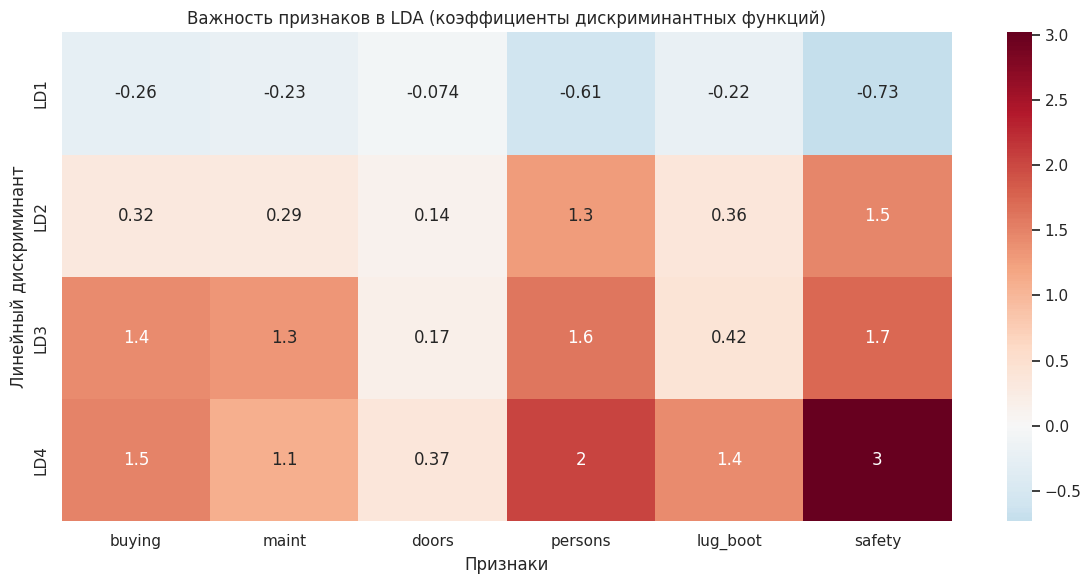

In [149]:
coef_df: pd.DataFrame = pd.DataFrame(
    lda_full.coef_, 
    columns=X_all.columns,
    index=[f'LD{i+1}' for i in range(lda_full.coef_.shape[0])]
)

plt.figure(figsize=(12, 6))
sns.heatmap(coef_df, annot=True, cmap='RdBu_r', center=0)
plt.title('Важность признаков в LDA (коэффициенты дискриминантных функций)')
plt.ylabel('Линейный дискриминант')
plt.xlabel('Признаки')
plt.tight_layout()
plt.show()

In [150]:
y_pred: np.ndarray = lda_full.predict(X_all)

feature_names: List[str] = X_all.columns.tolist()
pairs: List[Tuple[str, str]] = list(combinations(feature_names, 2)) # Все 15 пар

markers: List[str] = ['o', 's', '^', 'D'] 
class_names: List[str] = ['unacc', 'acc', 'good', 'vgood']

In [151]:
print(f"Cohen's Kappa: {cohen_kappa_score(y, y_pred):.4f}")
print(f"Matthews Correlation Coefficient: {matthews_corrcoef(y, y_pred):.4f}")

Cohen's Kappa: 0.5844
Matthews Correlation Coefficient: 0.5871


## 6. Анализ LDA во всех двумерных подпространствах
На графиках цвет точки отражает предсказание модели, а форма маркера – истинный класс. 
**Наблюдения:**
- В подпространствах, включающих `safety` и `persons`, наблюдается почти идеальное совпадение цвета и формы для классов `good` и `vgood`. Это означает, что LDA уверенно разделяет эти классы именно по этим признакам.
- В подпространствах `buying` vs `maint` наблюдается сильное смешение цветов внутри маркеров, что подтверждает низкую дискриминативную способность этих признаков по отдельности.
- Метрики **Cohen's Kappa** и **MCC** подтверждают высокое согласие между предсказаниями и истинными метками, несмотря на дисбаланс классов.

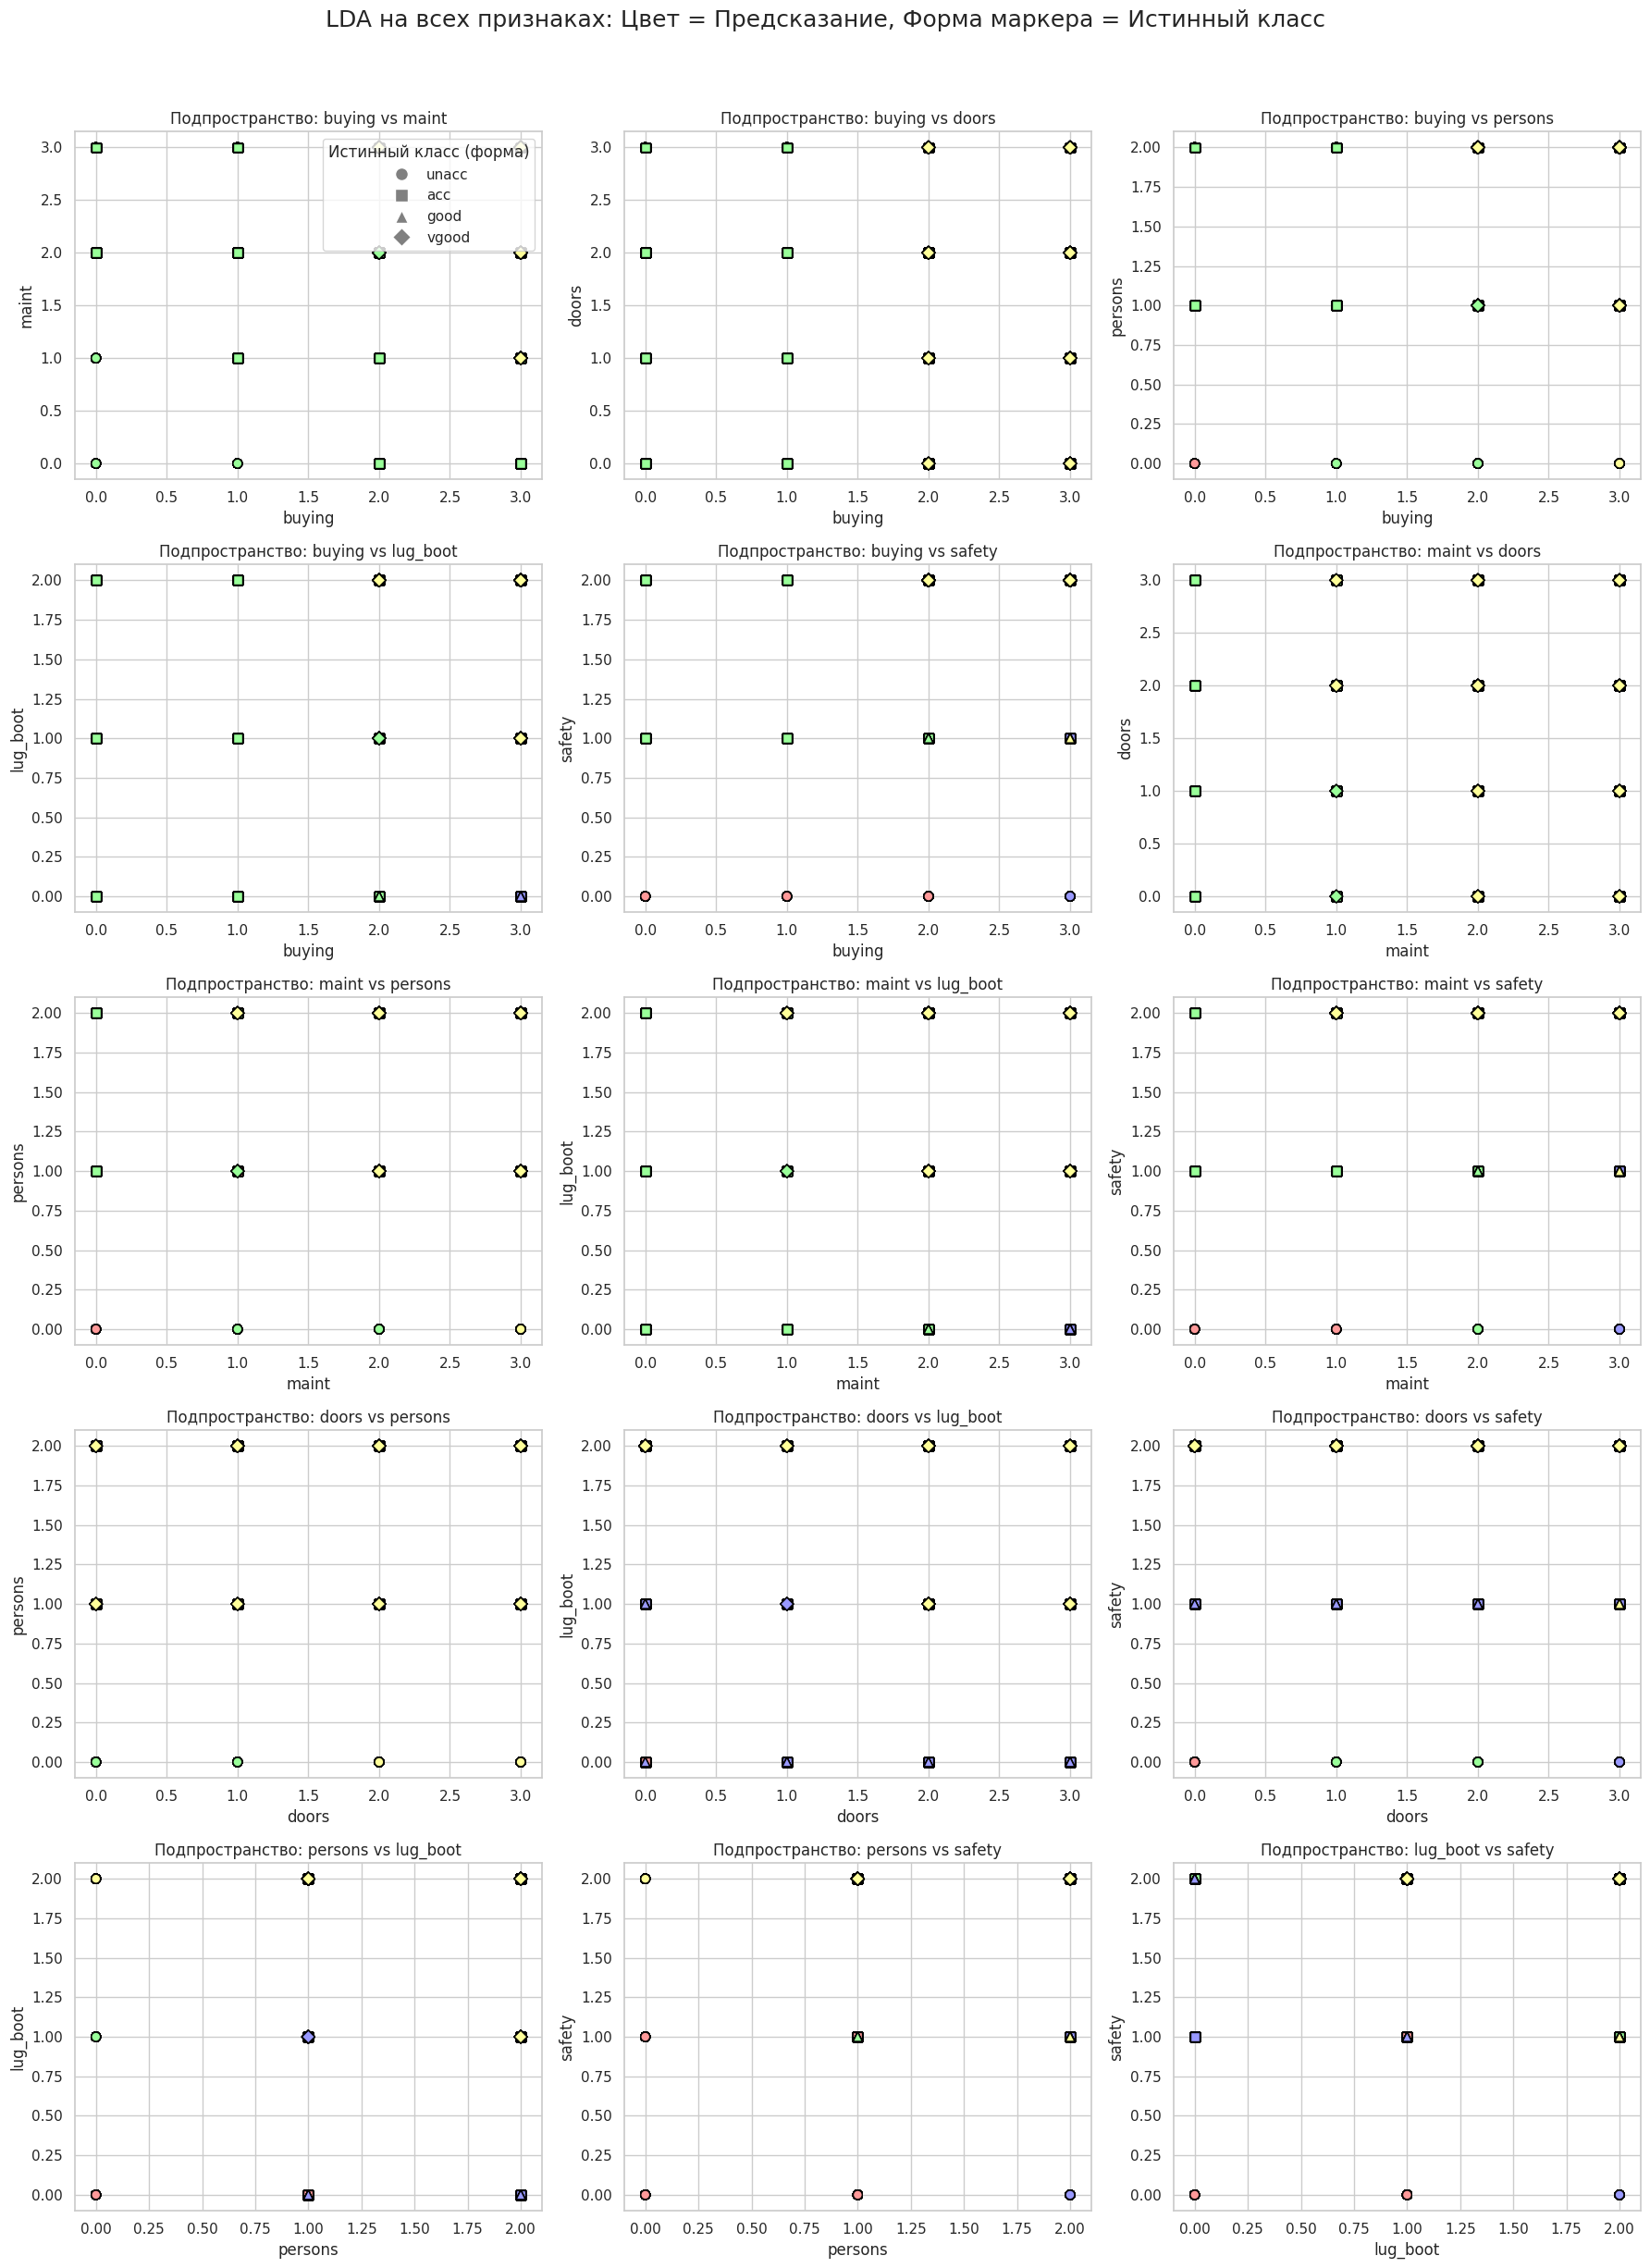

In [152]:
fig, axes = plt.subplots(5, 3, figsize=(18, 25))
axes = axes.flatten()

cmap_pred: ListedColormap = ListedColormap(['#FF9999', '#99FF99', '#9999FF', '#FFFF99'])

for idx, (f1, f2) in enumerate(pairs):
    ax = axes[idx]
    
    for true_class in range(4):
        mask: pd.Series = (y == true_class)
        ax.scatter(
            X_all.loc[mask, f1], 
            X_all.loc[mask, f2], 
            c=y_pred[mask],          # Цвет = ответ алгоритма
            cmap=cmap_pred, 
            marker=markers[true_class], # Форма = истинный класс
            edgecolor='black',
            s=50,
            vmin=0, vmax=3,
            label=class_names[true_class]
        )
    
    ax.set_xlabel(f1)
    ax.set_ylabel(f2)
    ax.set_title(f"Подпространство: {f1} vs {f2}")
    
    # Легенда графика
    if idx == 0:
        legend_elements = [plt.Line2D([0], [0], marker=markers[i], color='w', 
                                      markerfacecolor='gray', markersize=10, label=class_names[i]) 
                           for i in range(4)]
        ax.legend(handles=legend_elements, title="Истинный класс (форма)", loc='upper right')

plt.suptitle("LDA на всех признаках: Цвет = Предсказание, Форма маркера = Истинный класс", fontsize=18, y=0.98)
plt.tight_layout(rect=[0, 0, 1, 0.96])
plt.show()

## 7. Анализ ROC и Precision-Recall кривых

### Ключевые наблюдения:
1. **ROC-кривые** показывают, что все оптимизированные модели имеют высокий AUC-ROC (>0.95) для доминирующих классов `unacc` и `acc`. Это ожидаемо, так как этих объектов много, и модели легко их различают.

2. **Precision-Recall кривые** (более информативные для несбалансированных данных) выявили критическую разницу между моделями:
   - **SVM (poly)** демонстрирует AP > 0.95 даже для миноритарных классов `good` и `vgood`, что подтверждает его статус лучшей модели.
   - **QDA** показывает хорошие результаты (AP ~0.85-0.90), но уступает SVM poly на редких классах.
   - **Линейные модели (LDA, Logistic)** имеют AP < 0.6 для классов `good` и `vgood`, что объясняет их низкий F1-score в classification report.

3. **Разрыв между ROC-AUC и AP** для линейных моделей подтверждает, что accuracy и ROC-AUC могут быть обманчиво высокими при сильном дисбалансе. Только PR-анализ показал реальную неспособность этих моделей находить редкие классы.

### Вывод:
Для задач с несбалансированными классами **обязательно** следует использовать Precision-Recall кривы и Average Precision, а не полагаться только на accuracy или ROC-AUC. В нашем случае SVM Poly с полиномиальным ядром (degree=3) не только достиг 99% accuracy, но и показал превосходные результаты по AP для всех классов, включая миноритарные.

In [159]:
# Бинаризуем целевую переменную для One-vs-Rest подхода
y_bin = label_binarize(y, classes=[0, 1, 2, 3])
n_classes: int = 4

## ROC-кривые для всех моделей (One-vs-Rest)

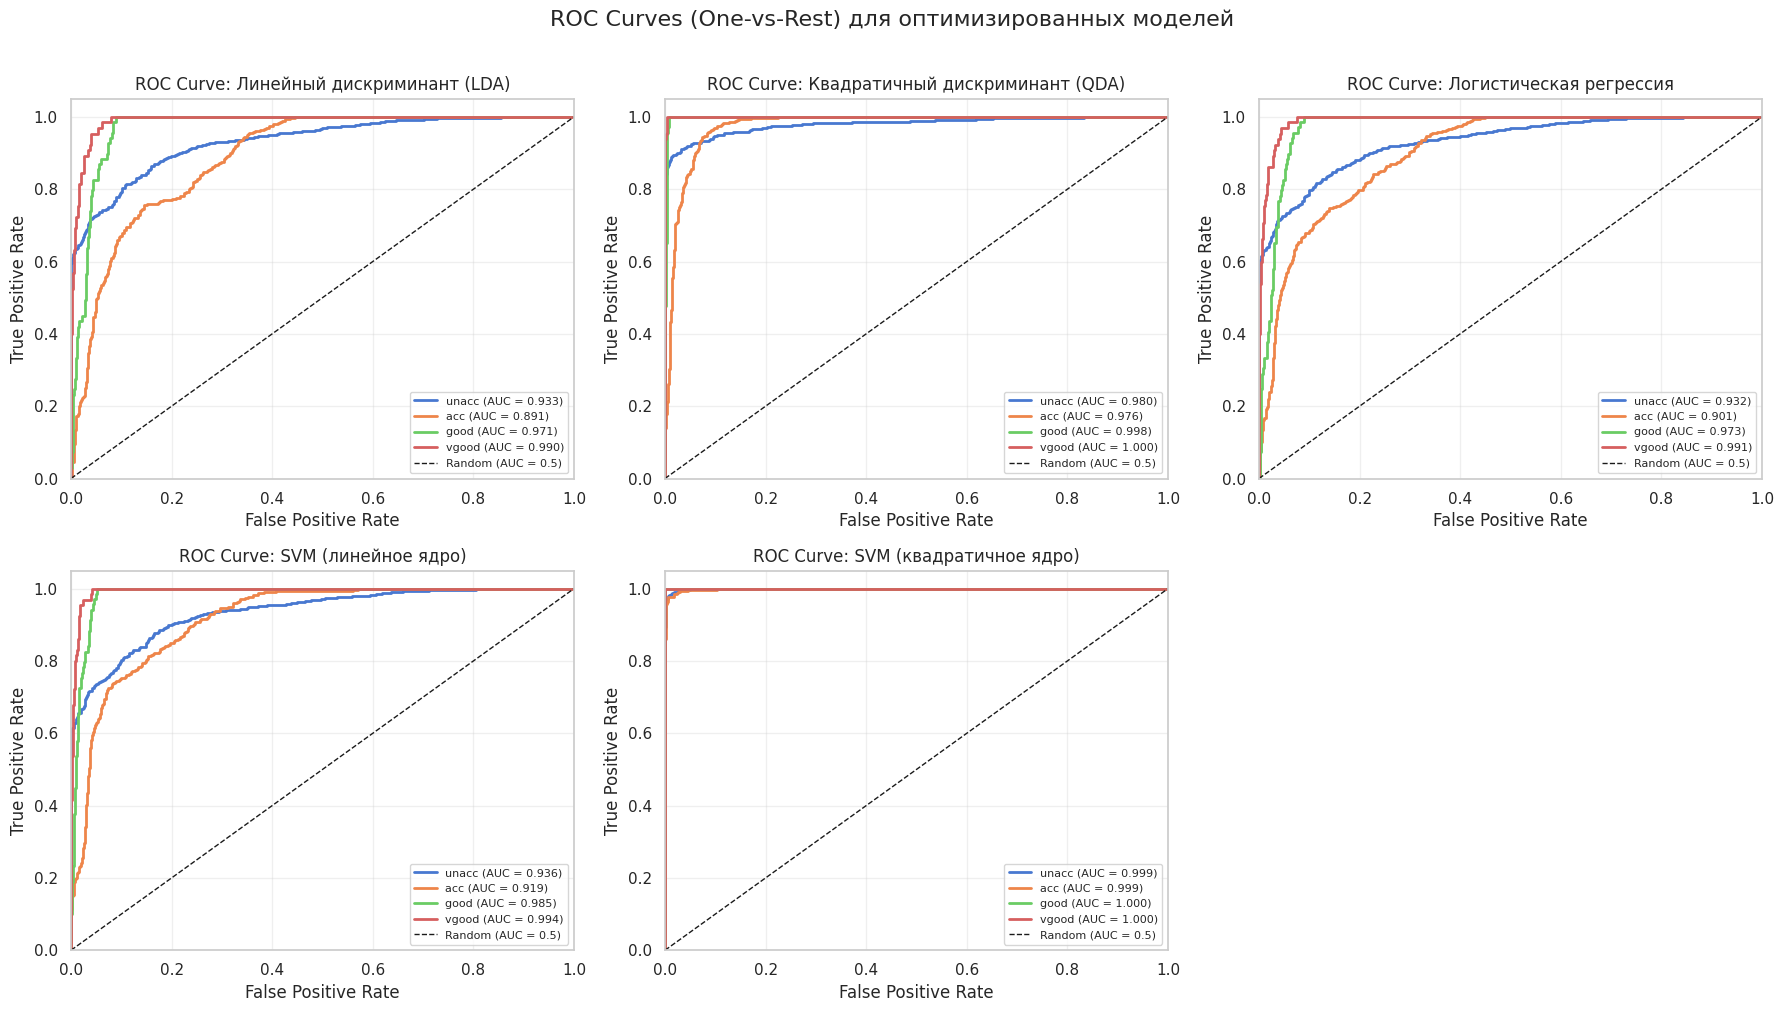

In [163]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_optimized.items()):
    ax = axes[idx]
    
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        # Для каждого класса строим ROC-кривую
        for j in range(n_classes):
            fpr, tpr, _ = roc_curve(y_bin[:, j], y_score[:, j])
            roc_auc = auc(fpr, tpr)
            ax.plot(fpr, tpr, lw=2, label=f'{class_names[j]} (AUC = {roc_auc:.3f})')
        
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC = 0.5)')
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('False Positive Rate')
        ax.set_ylabel('True Positive Rate')
        ax.set_title(f'ROC Curve: {name}')
        ax.legend(loc='lower right', fontsize=8)
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No probability estimates', 
                ha='center', va='center', transform=ax.transAxes)

axes[5].axis('off')
plt.suptitle('ROC Curves (One-vs-Rest) для оптимизированных моделей', fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Precision-Recall кривые

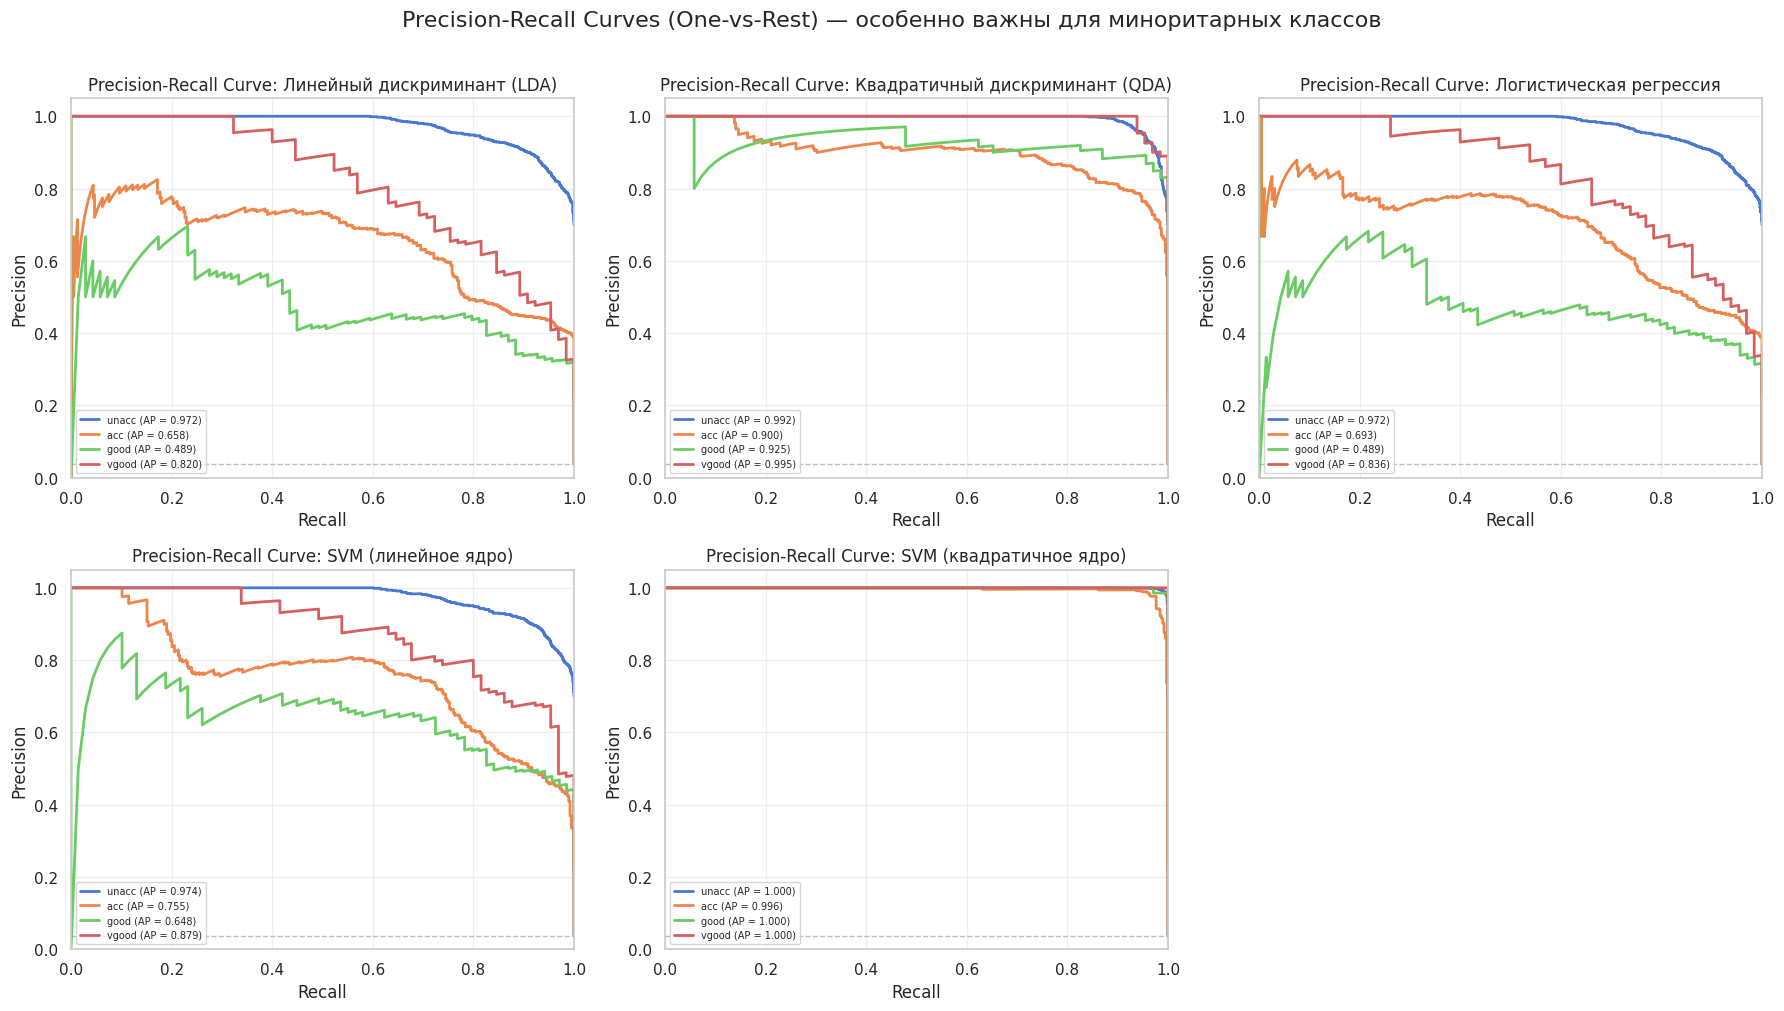

In [164]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for idx, (name, model) in enumerate(models_optimized.items()):
    ax = axes[idx]
    
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        for j in range(n_classes):
            precision, recall, _ = precision_recall_curve(y_bin[:, j], y_score[:, j])
            ap: float = average_precision_score(y_bin[:, j], y_score[:, j])
            ax.plot(recall, precision, lw=2, label=f'{class_names[j]} (AP = {ap:.3f})')
        
        # Базовая линия (доля положительного класса)
        ax.axhline(y=y_bin[:, j].mean(), color='gray', linestyle='--', lw=1, alpha=0.5)
        
        ax.set_xlim([0.0, 1.0])
        ax.set_ylim([0.0, 1.05])
        ax.set_xlabel('Recall')
        ax.set_ylabel('Precision')
        ax.set_title(f'Precision-Recall Curve: {name}')
        ax.legend(loc='lower left', fontsize=7)
        ax.grid(True, alpha=0.3)
    else:
        ax.text(0.5, 0.5, 'No probability estimates', 
                ha='center', va='center', transform=ax.transAxes)

axes[5].axis('off')
plt.suptitle('Precision-Recall Curves (One-vs-Rest) — особенно важны для миноритарных классов', 
             fontsize=16, y=1.01)
plt.tight_layout()
plt.show()

## Сводная таблица AUC-ROC и AP для всех моделей

In [ ]:
print("=" * 90)
print("СВОДНАЯ ТАБЛИЦА: AUC-ROC и Average Precision (AP) для всех моделей")
print("=" * 90)
print(f"{'Модель':<25} | {'AUC-ROC (macro)':<18} | {'AP (macro)':<15} | {'AP good':<10} | {'AP vgood'}")
print("-" * 90)

for name, model in models_optimized.items():
    if hasattr(model, "predict_proba"):
        model.fit(X_all, y)
        y_score = model.predict_proba(X_all)
        
        # Macro-average AUC-ROC
        roc_aucs: List[float] = []
        aps: List[float] = []
        for j in range(n_classes):
            roc_aucs.append(auc(*roc_curve(y_bin[:, j], y_score[:, j])[:2]))
            aps.append(average_precision_score(y_bin[:, j], y_score[:, j]))
        
        print(f"{name:<25} | {np.mean(roc_aucs):.4f}{'':<10} | {np.mean(aps):.4f}{'':<8} | {aps[2]:.4f}{'':<5} | {aps[3]:.4f}")

print("-" * 90)
print("\n💡 Интерпретация:")
print("   - AUC-ROC: общая способность модели ранжировать объекты (0.5 = случайное угадывание)")
print("   - Average Precision (AP): качество на несбалансированных данных (выше = лучше)")
print("   - AP для 'good' и 'vgood': насколько хорошо модель находит редкие классы")

СВОДНАЯ ТАБЛИЦА: AUC-ROC и Average Precision (AP) для всех моделей
Модель                    | AUC-ROC (macro)    | AP (macro)      | AP good    | AP vgood
------------------------------------------------------------------------------------------
Линейный дискриминант (LDA) | 0.9464           | 0.7348         | 0.4891      | 0.8201
Квадратичный дискриминант (QDA) | 0.9886           | 0.9529         | 0.9248      | 0.9950
Логистическая регрессия   | 0.9490           | 0.7474         | 0.4886      | 0.8359
SVM (линейное ядро)       | 0.9588           | 0.8138         | 0.6483      | 0.8785
SVM (квадратичное ядро)   | 0.9995           | 0.9987         | 0.9996      | 1.0000
------------------------------------------------------------------------------------------

💡 Интерпретация:
   - AUC-ROC: общая способность модели ранжировать объекты (0.5 = случайное угадывание)
   - Average Precision (AP): качество на несбалансированных данных (выше = лучше)
   - AP для 'good' и 'vgood': насколько х

## 📌 Общие выводы по лабораторной работе

1. **Природа данных:** Датасет Car Evaluation имеет выраженную нелинейную структуру и дисбаланс классов (доминирует класс `unacc`). Простые линейные модели (LDA, Logistic Regression) показывают удовлетворительный результат (~81-83%), но систематически ошибаются на миноритарных классах (`good`, `vgood`).

2. **Эффективность нелинейных методов:** Квадратичный дискриминант (QDA) и, особенно, метод опорных векторов с полиномиальным ядром (SVM poly), демонстрируют превосходные результаты. После оптимизации через Optuna, **SVM (poly) достиг точности 99%**, полностью нивелировав проблемы дисбаланса.

3. **Важность признаков:** Анализ с помощью SHAP и коэффициентов LDA однозначно выявил, что технические характеристики (`safety`, `persons`) являются решающими факторами для отнесения автомобиля к классам `good` и `vgood`. Экономические признаки (`buying`, `maint`) играют второстепенную роль.

4. **Визуализация LDA:** Проекция ответов LDA на все 15 двумерных подпространств наглядно продемонстрировала, что линейный разделитель отлично работает в подпространствах с сильными признаками (`safety`, `persons`), но деградирует в подпространствах слабых признаков, что объясняет разницу в метриках между 2D и полным пространством признаков.

5. **Инструментарий:** Использование Optuna позволило автоматизировать и улучшить процесс настройки моделей, а корректная реализация SHAP (через бинаризацию целевой переменной) обеспечила надежную интерпретацию "черного ящика" даже для многоклассовой задачи.